In [1]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

DATA_PATH = Path("../data/CIC-IDS-2017-V2.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Dataset loaded successfully!
Rows: 2695162
Columns: 79


In [3]:
FEATURE_COLUMNS = [col for col in df.columns if col != "label"]

print("Number of features:", len(FEATURE_COLUMNS))
print("\nFeature columns:")
for i, feature in enumerate(FEATURE_COLUMNS, start=1):
    print(f"{i:2}. {feature}")

Number of features: 78

Feature columns:
 1. Destination_Port
 2. Flow_Duration
 3. Total_Fwd_Packets
 4. Total_Backward_Packets
 5. Total_Length_of_Fwd_Packets
 6. Total_Length_of_Bwd_Packets
 7. Fwd_Packet_Length_Max
 8. Fwd_Packet_Length_Min
 9. Fwd_Packet_Length_Mean
10. Fwd_Packet_Length_Std
11. Bwd_Packet_Length_Max
12. Bwd_Packet_Length_Min
13. Bwd_Packet_Length_Mean
14. Bwd_Packet_Length_Std
15. Flow_Bytes/s
16. Flow_Packets/s
17. Flow_IAT_Mean
18. Flow_IAT_Std
19. Flow_IAT_Max
20. Flow_IAT_Min
21. Fwd_IAT_Total
22. Fwd_IAT_Mean
23. Fwd_IAT_Std
24. Fwd_IAT_Max
25. Fwd_IAT_Min
26. Bwd_IAT_Total
27. Bwd_IAT_Mean
28. Bwd_IAT_Std
29. Bwd_IAT_Max
30. Bwd_IAT_Min
31. Fwd_PSH_Flags
32. Bwd_PSH_Flags
33. Fwd_URG_Flags
34. Bwd_URG_Flags
35. Fwd_Header_Length
36. Bwd_Header_Length
37. Fwd_Packets/s
38. Bwd_Packets/s
39. Min_Packet_Length
40. Max_Packet_Length
41. Packet_Length_Mean
42. Packet_Length_Std
43. Packet_Length_Variance
44. FIN_Flag_Count
45. SYN_Flag_Count
46. RST_Flag_Count
4

In [4]:
non_numeric_features = df[FEATURE_COLUMNS].select_dtypes(
    exclude=np.number
).columns

print("Non-numeric feature columns:")
print(list(non_numeric_features))

Non-numeric feature columns:
[]


In [5]:
labels = df["label"]

X = df[FEATURE_COLUMNS]
y = labels

print("Feature matrix shape:", X.shape)
print("Label vector shape:", y.shape)

Feature matrix shape: (2695162, 78)
Label vector shape: (2695162,)


In [6]:
print(X.dtypes.value_counts())

float64    78
Name: count, dtype: int64


In [7]:
# Phase 3
# 3.1 Separate benign and attack traffic

BENIGN_LABEL = "BENIGN"

benign_df = df[df["label"] == BENIGN_LABEL].copy()
attack_df = df[df["label"] != BENIGN_LABEL].copy()

print("Benign flows:", len(benign_df))
print("Attack flows:", len(attack_df))

print("\nBenign labels:")
print(benign_df["label"].value_counts())

print("\nAttack labels:")
print(attack_df["label"].value_counts())

Benign flows: 2096484
Attack flows: 598678

Benign labels:
label
BENIGN    2096484
Name: count, dtype: int64

Attack labels:
label
DoS Hulk                      172849
Comb                          172800
DDoS                          128016
PortScan                       90819
DoS GoldenEye                  10286
FTP-Patator                     5933
DoS slowloris                   5385
DoS Slowhttptest                5228
SSH-Patator                     3219
Bot                             1953
Web Attack � Brute Force        1470
Web Attack � XSS                 652
Infiltration                      36
Web Attack � Sql Injection        21
Heartbleed                        11
Name: count, dtype: int64


In [8]:
# 3.2 Create a feature-vector identifier

df["feature_key"] = pd.util.hash_pandas_object(
    df[FEATURE_COLUMNS],
    index=False
)

print("Feature key created.")
print("Unique feature vectors:", df["feature_key"].nunique())
print("Total rows:", len(df))

Feature key created.
Unique feature vectors: 2661199
Total rows: 2695162


In [9]:
# 3.3 Recreate benign and attack dataframes
# so they include feature_key

benign_df = df[df["label"] == BENIGN_LABEL].copy()
attack_df = df[df["label"] != BENIGN_LABEL].copy()

print("Benign flows:", len(benign_df))
print("Attack flows:", len(attack_df))

print("\nfeature_key exists in benign_df:",
      "feature_key" in benign_df.columns)

print("feature_key exists in attack_df:",
      "feature_key" in attack_df.columns)

Benign flows: 2096484
Attack flows: 598678

feature_key exists in benign_df: True
feature_key exists in attack_df: True


In [10]:
# 3.4 Create benign training/validation split

from sklearn.model_selection import train_test_split

benign_keys = benign_df["feature_key"].drop_duplicates()

print("Unique benign feature vectors:", len(benign_keys))

benign_train_keys, benign_val_keys = train_test_split(
    benign_keys,
    test_size=0.20,
    random_state=42
)

print("Training feature vectors:", len(benign_train_keys))
print("Validation feature vectors:", len(benign_val_keys))

Unique benign feature vectors: 2063255
Training feature vectors: 1650604
Validation feature vectors: 412651


In [11]:
# 3.5 — Convert the keys back into actual rows

benign_train_df = benign_df[
    benign_df["feature_key"].isin(benign_train_keys)
].copy()

benign_val_df = benign_df[
    benign_df["feature_key"].isin(benign_val_keys)
].copy()

print("Benign training rows:", len(benign_train_df))
print("Benign validation rows:", len(benign_val_df))

Benign training rows: 1677198
Benign validation rows: 419286


In [12]:
# 3.6 Verify training/validation feature-vector overlap

train_keys = set(benign_train_df["feature_key"])
val_keys = set(benign_val_df["feature_key"])

overlap = train_keys.intersection(val_keys)

print("Training/validation overlapping feature vectors:", len(overlap))

Training/validation overlapping feature vectors: 0


In [13]:
# 3.7 Create attack test set

attack_test_df = attack_df.copy()

y_test = attack_test_df["label"]

print("Attack test rows:", len(attack_test_df))
print("\nAttack classes:")
print(y_test.value_counts())

Attack test rows: 598678

Attack classes:
label
DoS Hulk                      172849
Comb                          172800
DDoS                          128016
PortScan                       90819
DoS GoldenEye                  10286
FTP-Patator                     5933
DoS slowloris                   5385
DoS Slowhttptest                5228
SSH-Patator                     3219
Bot                             1953
Web Attack � Brute Force        1470
Web Attack � XSS                 652
Infiltration                      36
Web Attack � Sql Injection        21
Heartbleed                        11
Name: count, dtype: int64


In [14]:
# 3.8 Prepare feature matrices for modeling

X_train = benign_train_df[FEATURE_COLUMNS]
X_val = benign_val_df[FEATURE_COLUMNS]
X_test = attack_test_df[FEATURE_COLUMNS]

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1677198, 78)
X_val shape: (419286, 78)
X_test shape: (598678, 78)


In [15]:
# 3.9 Final sanity check

print("===== FINAL PHASE 3 CHECK =====")

print("Training labels:")
print(benign_train_df["label"].value_counts())

print("\nValidation labels:")
print(benign_val_df["label"].value_counts())

print("\nTest labels:")
print(attack_test_df["label"].value_counts())

print("\nFeature matrix shapes:")
print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

===== FINAL PHASE 3 CHECK =====
Training labels:
label
BENIGN    1677198
Name: count, dtype: int64

Validation labels:
label
BENIGN    419286
Name: count, dtype: int64

Test labels:
label
DoS Hulk                      172849
Comb                          172800
DDoS                          128016
PortScan                       90819
DoS GoldenEye                  10286
FTP-Patator                     5933
DoS slowloris                   5385
DoS Slowhttptest                5228
SSH-Patator                     3219
Bot                             1953
Web Attack � Brute Force        1470
Web Attack � XSS                 652
Infiltration                      36
Web Attack � Sql Injection        21
Heartbleed                        11
Name: count, dtype: int64

Feature matrix shapes:
X_train: (1677198, 78)
X_val:   (419286, 78)
X_test:  (598678, 78)


In [16]:
# Phase 4
# Train Baseline

from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [17]:
model.fit(X_train)

print("Isolation Forest training completed.")
print("Number of trees:", len(model.estimators_))
print("Number of features:", model.n_features_in_)
print("Max samples per tree:", model.max_samples_)
print("Offset:", model.offset_)

Isolation Forest training completed.
Number of trees: 200
Number of features: 78
Max samples per tree: 256
Offset: -0.5


In [18]:
# Phase 5.1 — Inspect Isolation Forest outputs on benign validation data

sample = X_val.head(1000)

predictions = model.predict(sample)
raw_scores = model.score_samples(sample)
decision_scores = model.decision_function(sample)

print("Number of samples:", len(sample))

print("\nPrediction counts:")
print(pd.Series(predictions).value_counts())

print("\nRaw score range:")
print("Minimum:", raw_scores.min())
print("Maximum:", raw_scores.max())

print("\nDecision score range:")
print("Minimum:", decision_scores.min())
print("Maximum:", decision_scores.max())

Number of samples: 1000

Prediction counts:
 1    902
-1     98
Name: count, dtype: int64

Raw score range:
Minimum: -0.707320745957521
Maximum: -0.3149766601595601

Decision score range:
Minimum: -0.20732074595752104
Maximum: 0.1850233398404399


In [19]:
# Phase 5.2 — Compare raw score and decision score

comparison = pd.DataFrame({
    "raw_score": raw_scores[:10],
    "decision_score": decision_scores[:10],
    "prediction": predictions[:10]
})

comparison

,raw_score,decision_score,prediction
0,-0.318026,0.181974,1
1,-0.659302,-0.159302,-1
2,-0.705569,-0.205569,-1
3,-0.320062,0.179938,1
4,-0.329626,0.170374,1
5,-0.319737,0.180263,1
6,-0.323299,0.176701,1
7,-0.349237,0.150763,1
8,-0.522918,-0.022918,-1
9,-0.366559,0.133441,1


In [20]:
# Phase 5.3 — Raw scores for the complete benign validation set

val_raw_scores = model.score_samples(X_val)

print("Number of validation flows:", len(val_raw_scores))

print("\nRaw score statistics:")
print("Minimum:", val_raw_scores.min())
print("Maximum:", val_raw_scores.max())
print("Mean:", val_raw_scores.mean())
print("Median:", np.median(val_raw_scores))

Number of validation flows: 419286

Raw score statistics:
Minimum: -0.7669419634708359
Maximum: -0.3146596983053189
Mean: -0.3708456372853732
Median: -0.3405580533254993


In [21]:
# Phase 5.4 — Inspect important percentiles of benign raw scores

percentiles = np.percentile(
    val_raw_scores,
    [1, 5, 10, 25, 50, 75, 90, 95, 99, 99.5, 99.9]
)

for p, score in zip(
    [1, 5, 10, 25, 50, 75, 90, 95, 99, 99.5, 99.9],
    percentiles
):
    print(f"{p:>5}% percentile: {score:.6f}")

    1% percentile: -0.642452
    5% percentile: -0.544735
   10% percentile: -0.469736
   25% percentile: -0.387872
   50% percentile: -0.340558
   75% percentile: -0.322141
   90% percentile: -0.317348
   95% percentile: -0.316345
   99% percentile: -0.315502
 99.5% percentile: -0.315291
 99.9% percentile: -0.314977


In [22]:
# Phase 5.5 — Count benign flows below selected raw-score thresholds

thresholds = [-0.5, -0.54, -0.60, -0.64]

for threshold in thresholds:
    count = np.sum(val_raw_scores < threshold)
    percentage = (count / len(val_raw_scores)) * 100

    print(
        f"Score < {threshold:.2f}: "
        f"{count:,} flows ({percentage:.2f}%)"
    )

Score < -0.50: 33,310 flows (7.94%)
Score < -0.54: 22,476 flows (5.36%)
Score < -0.60: 8,612 flows (2.05%)
Score < -0.64: 4,352 flows (1.04%)


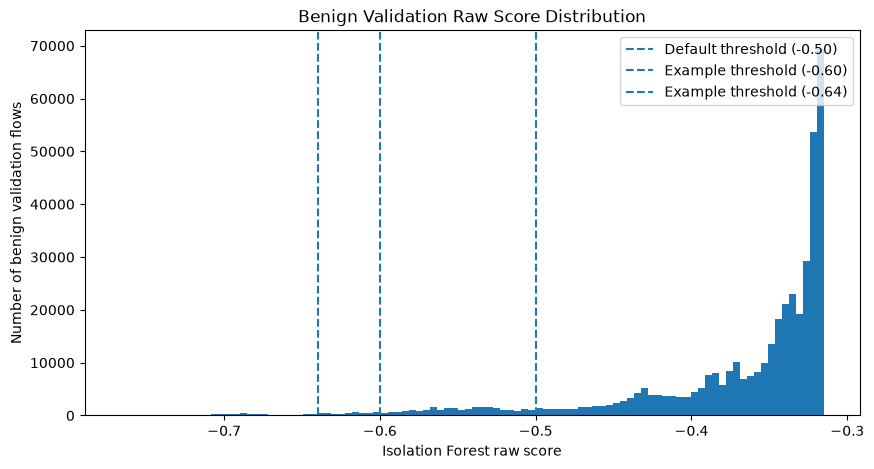

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    val_raw_scores,
    bins=100
)

plt.axvline(
    -0.50,
    linestyle="--",
    label="Default threshold (-0.50)"
)

plt.axvline(
    -0.60,
    linestyle="--",
    label="Example threshold (-0.60)"
)

plt.axvline(
    -0.64,
    linestyle="--",
    label="Example threshold (-0.64)"
)

plt.xlabel("Isolation Forest raw score")
plt.ylabel("Number of benign validation flows")
plt.title("Benign Validation Raw Score Distribution")
plt.legend()
plt.show()

In [24]:
# Phase 5.7 — Create first percentile-based anomaly score
# Step 1 - Sort the benign reference scores
sorted_val_scores = np.sort(val_raw_scores)

print("Number of reference scores:", len(sorted_val_scores))
print("Lowest score:", sorted_val_scores[0])
print("Highest score:", sorted_val_scores[-1])

Number of reference scores: 419286
Lowest score: -0.7669419634708359
Highest score: -0.3146596983053189


In [25]:
# Step 2 - Convert raw scores into empirical percentiles
def calculate_anomaly_score(raw_scores, reference_scores):
    sorted_reference = np.sort(reference_scores)

    ranks = np.searchsorted(
        sorted_reference,
        raw_scores,
        side="right"
    )

    percentile = ranks / len(sorted_reference)

    anomaly_score = 1 - percentile

    return anomaly_score

In [26]:
test_raw_scores = np.array([
    -0.32,
    -0.34,
    -0.40,
    -0.50,
    -0.60,
    -0.64
])

test_anomaly_scores = calculate_anomaly_score(
    test_raw_scores,
    val_raw_scores
)

for raw, anomaly in zip(test_raw_scores, test_anomaly_scores):
    print(
        f"Raw score: {raw:.2f} "
        f"→ Anomaly score: {anomaly:.4f}"
    )

Raw score: -0.32 → Anomaly score: 0.1894
Raw score: -0.34 → Anomaly score: 0.4913
Raw score: -0.40 → Anomaly score: 0.7856
Raw score: -0.50 → Anomaly score: 0.9206
Raw score: -0.60 → Anomaly score: 0.9795
Raw score: -0.64 → Anomaly score: 0.9896


In [27]:
# Phase 5.8 — Test the transformation on actual benign flows
benign_test_scores = calculate_anomaly_score(
    val_raw_scores[:20],
    val_raw_scores
)

comparison = pd.DataFrame({
    "raw_score": val_raw_scores[:20],
    "anomaly_score": benign_test_scores
})

comparison

,raw_score,anomaly_score
0,-0.318026,0.129701
1,-0.659302,0.991693
2,-0.705569,0.998433
3,-0.320062,0.192320
4,-0.329626,0.380528
5,-0.319737,0.182634
6,-0.323299,0.283351
7,-0.349237,0.581162
8,-0.522918,0.933170
9,-0.366559,0.658264


In [28]:
# Phase 5.9.1 — Get the validation feature keys
benign_val_keys = benign_val_df["feature_key"].drop_duplicates()

print("Unique benign validation feature vectors:", len(benign_val_keys))

Unique benign validation feature vectors: 412651


In [29]:
# Phase 5.9.2 — Split calibration and final evaluation keys
calibration_keys, benign_eval_keys = train_test_split(
    benign_val_keys,
    test_size=0.50,
    random_state=42
)

print("Calibration feature vectors:", len(calibration_keys))
print("Final evaluation feature vectors:", len(benign_eval_keys))

Calibration feature vectors: 206325
Final evaluation feature vectors: 206326


In [30]:
# Phase 5.9.3 — Create the actual calibration/evaluation DataFrames
benign_calibration_df = benign_val_df[
    benign_val_df["feature_key"].isin(calibration_keys)
].copy()

benign_eval_df = benign_val_df[
    benign_val_df["feature_key"].isin(benign_eval_keys)
].copy()

print("Calibration rows:", len(benign_calibration_df))
print("Final evaluation rows:", len(benign_eval_df))

Calibration rows: 209527
Final evaluation rows: 209759


In [31]:
# Phase 5.9.4 — Verify the separation
calibration_key_set = set(calibration_keys)
evaluation_key_set = set(benign_eval_keys)

overlap = calibration_key_set.intersection(evaluation_key_set)

print("Calibration/evaluation overlapping feature vectors:", len(overlap))

Calibration/evaluation overlapping feature vectors: 0


In [32]:
# Phase 5.9.5 — Create calibration and evaluation feature matrices
X_calibration = benign_calibration_df[FEATURE_COLUMNS]
X_benign_eval = benign_eval_df[FEATURE_COLUMNS]

print("Calibration shape:", X_calibration.shape)
print("Final evaluation shape:", X_benign_eval.shape)

Calibration shape: (209527, 78)
Final evaluation shape: (209759, 78)


In [33]:
# Phase 5.9.6 — Calculate raw scores
calibration_raw_scores = model.score_samples(X_calibration)

benign_eval_raw_scores = model.score_samples(X_benign_eval)

print("Calibration scores:", len(calibration_raw_scores))
print("Evaluation scores:", len(benign_eval_raw_scores))

print("\nCalibration score range:")
print("Minimum:", calibration_raw_scores.min())
print("Maximum:", calibration_raw_scores.max())

print("\nEvaluation score range:")
print("Minimum:", benign_eval_raw_scores.min())
print("Maximum:", benign_eval_raw_scores.max())

Calibration scores: 209527
Evaluation scores: 209759

Calibration score range:
Minimum: -0.7669419634708359
Maximum: -0.3146596983053189

Evaluation score range:
Minimum: -0.7598375806571959
Maximum: -0.3146596983053189


In [34]:
# Phase 5.9.7 — Build the percentile reference from calibration only
def calculate_anomaly_score(raw_scores, reference_scores):
    sorted_reference = np.sort(reference_scores)

    ranks = np.searchsorted(
        sorted_reference,
        raw_scores,
        side="right"
    )

    percentile = ranks / len(sorted_reference)

    anomaly_score = 1 - percentile

    return anomaly_score

In [35]:
# Step 1 — Create anomaly scores for the calibration data
calibration_anomaly_scores = calculate_anomaly_score(
    calibration_raw_scores,
    calibration_raw_scores
)

print("Calibration anomaly score range:")
print("Minimum:", calibration_anomaly_scores.min())
print("Maximum:", calibration_anomaly_scores.max())

Calibration anomaly score range:
Minimum: 0.0
Maximum: 0.9999952273454018


In [36]:
# Step 2 — Apply the same reference to untouched benign evaluation data
benign_eval_anomaly_scores = calculate_anomaly_score(
    benign_eval_raw_scores,
    calibration_raw_scores
)

print("Final benign evaluation anomaly score range:")
print("Minimum:", benign_eval_anomaly_scores.min())
print("Maximum:", benign_eval_anomaly_scores.max())

Final benign evaluation anomaly score range:
Minimum: 0.0
Maximum: 0.9999952273454018


In [37]:
# Phase 5.10 — Measure the benign anomaly-score distribution
percentiles = [1, 5, 10, 25, 50, 75, 90, 95, 99, 99.5, 99.9]

print("Final benign evaluation anomaly-score percentiles:")

for p in percentiles:
    value = np.percentile(
        benign_eval_anomaly_scores,
        p
    )

    print(f"{p:>5}%: {value:.6f}")

Final benign evaluation anomaly-score percentiles:
    1%: 0.009951
    5%: 0.049807
   10%: 0.100178
   25%: 0.249882
   50%: 0.501449
   75%: 0.750557
   90%: 0.899980
   95%: 0.949735
   99%: 0.989381
 99.5%: 0.995022
 99.9%: 0.999056


In [38]:
# Phase 5.11 — First attack-data test
# Step 1 — Calculate attack raw scores
attack_raw_scores = model.score_samples(X_test)

print("Attack score count:", len(attack_raw_scores))

print("\nAttack score range:")
print("Minimum:", attack_raw_scores.min())
print("Maximum:", attack_raw_scores.max())

print("\nAttack score statistics:")
print("Mean:", attack_raw_scores.mean())
print("Median:", np.median(attack_raw_scores))

Attack score count: 598678

Attack score range:
Minimum: -0.7156345447914046
Maximum: -0.3188813298424079

Attack score statistics:
Mean: -0.4872120016276304
Median: -0.470148457947953


In [39]:
# convert attack scores to our anomaly score
def calculate_anomaly_score(raw_scores, reference_scores):
    sorted_reference = np.sort(reference_scores)

    ranks = np.searchsorted(
        sorted_reference,
        raw_scores,
        side="right"
    )

    percentile = ranks / len(sorted_reference)

    anomaly_score = 1 - percentile

    return anomaly_score

In [40]:
attack_anomaly_scores = calculate_anomaly_score(
    attack_raw_scores,
    calibration_raw_scores
)

print("Attack anomaly score count:", len(attack_anomaly_scores))

print("\nAttack anomaly score range:")
print("Minimum:", attack_anomaly_scores.min())
print("Maximum:", attack_anomaly_scores.max())

print("\nAttack anomaly score statistics:")
print("Mean:", attack_anomaly_scores.mean())
print("Median:", np.median(attack_anomaly_scores))

Attack anomaly score count: 598678

Attack anomaly score range:
Minimum: 0.15780782428994833
Maximum: 0.9994177361390179

Attack anomaly score statistics:
Mean: 0.8203970980201803
Median: 0.9003708352622812


In [41]:
# Phase 5.11 — Per-attack-category anomaly analysis
attack_results = attack_test_df[["label"]].copy()

attack_results["raw_score"] = attack_raw_scores
attack_results["anomaly_score"] = attack_anomaly_scores

attack_results.head()

,label,raw_score,anomaly_score
64541,Infiltration,-0.432297,0.851356
66520,Infiltration,-0.322983,0.270366
70525,Infiltration,-0.654933,0.991123
71006,Infiltration,-0.363867,0.650513
71545,Infiltration,-0.634932,0.988154


In [42]:
# Phase 5.11 — Category-level analysis
category_summary = (
    attack_results
    .groupby("label")["anomaly_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )
    .sort_values("median", ascending=False)
)

category_summary

,count,mean,median,minimum,maximum,q25,q75
label,,,,,,,
Heartbleed,11,0.998445,0.999084,0.993566,0.999303,0.998537,0.999272
DoS Hulk,172849,0.928926,0.987209,0.255318,0.998086,0.984360,0.991471
DoS slowloris,5385,0.837980,0.976786,0.250035,0.991853,0.612804,0.978394
Infiltration,36,0.924432,0.975614,0.270366,0.999418,0.966787,0.989960
DDoS,128016,0.826850,0.931594,0.245052,0.993046,0.681077,0.936657
DoS GoldenEye,10286,0.905786,0.926105,0.398941,0.990297,0.895901,0.932517
DoS Slowhttptest,5228,0.916704,0.920192,0.418652,0.991691,0.920192,0.927260
Comb,172800,0.889972,0.890024,0.845643,0.923976,0.878245,0.900753
SSH-Patator,3219,0.757156,0.783011,0.238561,0.918650,0.781575,0.784601


In [43]:
# Phase 5.12 — Threshold evaluation
thresholds = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99]

print("Threshold analysis")
print("=" * 70)

for threshold in thresholds:
    benign_flagged = np.sum(benign_eval_anomaly_scores >= threshold)
    attack_flagged = np.sum(attack_anomaly_scores >= threshold)

    benign_rate = benign_flagged / len(benign_eval_anomaly_scores)
    attack_rate = attack_flagged / len(attack_anomaly_scores)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Benign flagged: {benign_flagged:>7} "
        f"({benign_rate:.2%}) | "
        f"Attack flagged: {attack_flagged:>7} "
        f"({attack_rate:.2%})"
    )

Threshold analysis
Threshold: 0.50 | Benign flagged:  105182 (50.14%) | Attack flagged:  514855 (86.00%)
Threshold: 0.60 | Benign flagged:   84212 (40.15%) | Attack flagged:  478505 (79.93%)
Threshold: 0.70 | Benign flagged:   63228 (30.14%) | Attack flagged:  445319 (74.38%)
Threshold: 0.80 | Benign flagged:   41882 (19.97%) | Attack flagged:  429216 (71.69%)
Threshold: 0.90 | Benign flagged:   20975 (10.00%) | Attack flagged:  303089 (50.63%)
Threshold: 0.95 | Benign flagged:   10406 (4.96%) | Attack flagged:  168961 (28.22%)
Threshold: 0.99 | Benign flagged:    1993 (0.95%) | Attack flagged:   58480 (9.77%)


In [44]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_true = np.concatenate([
    np.zeros(len(benign_eval_anomaly_scores), dtype=int),
    np.ones(len(attack_anomaly_scores), dtype=int)
])

all_anomaly_scores = np.concatenate([
    benign_eval_anomaly_scores,
    attack_anomaly_scores
])

threshold_results = []

for threshold in thresholds:

    y_pred = (all_anomaly_scores >= threshold).astype(int)

    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df

,threshold,precision,recall,f1
0,0.50,0.830362,0.859987,0.844915
1,0.60,0.850348,0.799269,0.824018
2,0.70,0.875669,0.743837,0.804388
3,0.80,0.911097,0.716940,0.802441
4,0.90,0.935275,0.506264,0.656931
5,0.95,0.941985,0.282223,0.434322
6,0.99,0.967043,0.097682,0.177440


In [45]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    y_true,
    all_anomaly_scores
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8202234767142711


In [46]:
from sklearn.metrics import roc_curve

fpr, tpr, roc_thresholds = roc_curve(
    y_true,
    all_anomaly_scores
)

print("Number of ROC points:", len(fpr))

print("\nFirst 10 ROC points:")
for i in range(min(10, len(fpr))):
    print(
        f"Threshold: {roc_thresholds[i]:.6f} | "
        f"FPR: {fpr[i]:.6f} | "
        f"TPR: {tpr[i]:.6f}"
    )

Number of ROC points: 50063

First 10 ROC points:
Threshold: inf | FPR: 0.000000 | TPR: 0.000000
Threshold: 0.999995 | FPR: 0.000005 | TPR: 0.000000
Threshold: 0.999990 | FPR: 0.000010 | TPR: 0.000000
Threshold: 0.999981 | FPR: 0.000024 | TPR: 0.000000
Threshold: 0.999967 | FPR: 0.000029 | TPR: 0.000000
Threshold: 0.999962 | FPR: 0.000038 | TPR: 0.000000
Threshold: 0.999933 | FPR: 0.000043 | TPR: 0.000000
Threshold: 0.999924 | FPR: 0.000052 | TPR: 0.000000
Threshold: 0.999909 | FPR: 0.000067 | TPR: 0.000000
Threshold: 0.999905 | FPR: 0.000076 | TPR: 0.000000


In [47]:
target_fprs = [0.001, 0.005, 0.01, 0.02, 0.05, 0.10]

print("ROC operating points")
print("=" * 70)

for target in target_fprs:
    index = np.argmin(np.abs(fpr - target))

    print(
        f"Target FPR: {target:.1%} | "
        f"Actual FPR: {fpr[index]:.4%} | "
        f"TPR: {tpr[index]:.4%} | "
        f"Threshold: {roc_thresholds[index]:.6f}"
    )

ROC operating points
Target FPR: 0.1% | Actual FPR: 0.1006% | TPR: 0.0017% | Threshold: 0.999055
Target FPR: 0.5% | Actual FPR: 0.5011% | TPR: 0.4017% | Threshold: 0.995022
Target FPR: 1.0% | Actual FPR: 0.9997% | TPR: 11.2219% | Threshold: 0.989386
Target FPR: 2.0% | Actual FPR: 1.9999% | TPR: 27.0742% | Threshold: 0.979291
Target FPR: 5.0% | Actual FPR: 5.0000% | TPR: 28.2290% | Threshold: 0.949739
Target FPR: 10.0% | Actual FPR: 10.0000% | TPR: 50.6270% | Threshold: 0.899984


In [48]:
# Phase 5.14 — Per-category recall
analysis_threshold = 0.90

attack_results["detected"] = (
    attack_results["anomaly_score"] >= analysis_threshold
)

category_detection = (
    attack_results
    .groupby("label")["detected"]
    .agg(
        attack_flows="count",
        detected_flows="sum"
    )
)

category_detection["detection_rate"] = (
    category_detection["detected_flows"]
    / category_detection["attack_flows"]
)

category_detection

,attack_flows,detected_flows,detection_rate
label,,,
Bot,1953,44,0.022529
Comb,172800,50700,0.293403
DDoS,128016,81390,0.635780
DoS GoldenEye,10286,7363,0.715827
DoS Hulk,172849,155652,0.900509
DoS Slowhttptest,5228,4344,0.830910
DoS slowloris,5385,3195,0.593315
FTP-Patator,5933,2,0.000337
Heartbleed,11,11,1.000000


In [49]:
# Phase 6 - n_estimators experiment

from sklearn.ensemble import IsolationForest

model_50 = IsolationForest(
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)

model_50.fit(X_train)

print("Number of trees:", len(model_50.estimators_))
print("Max samples:", model_50.max_samples_)
print("Number of features:", model_50.n_features_in_)

Number of trees: 50
Max samples: 256
Number of features: 78


In [50]:
# Phase 6 — Restore score calibration function

import numpy as np

def calibrate_scores(raw_scores, reference_scores):
    """
    Convert Isolation Forest raw score_samples() values
    into percentile-based anomaly scores using a reference
    distribution.

    Lower raw scores indicate more anomalous observations.
    Therefore, lower raw scores receive higher anomaly scores.
    """

    raw_scores = np.asarray(raw_scores)
    reference_scores = np.asarray(reference_scores)

    # Sort reference scores from lowest (most anomalous)
    # to highest (most normal)
    sorted_reference = np.sort(reference_scores)

    # Percentile rank of each raw score within the reference distribution
    ranks = np.searchsorted(
        sorted_reference,
        raw_scores,
        side="right"
    )

    percentile = ranks / len(sorted_reference)

    # Reverse the percentile so that:
    # low raw score  -> high anomaly score
    # high raw score -> low anomaly score
    anomaly_score = 1.0 - percentile

    return anomaly_score

In [51]:
# Phase 6.1 — Score 50-tree model

X_final_evaluation = X_benign_eval

calibration_scores_50 = model_50.score_samples(X_calibration)
evaluation_scores_50 = model_50.score_samples(X_final_evaluation)

print("Calibration scores:", len(calibration_scores_50))
print("Evaluation scores:", len(evaluation_scores_50))

print("\nCalibration score range:")
print("Minimum:", calibration_scores_50.min())
print("Maximum:", calibration_scores_50.max())

print("\nEvaluation score range:")
print("Minimum:", evaluation_scores_50.min())
print("Maximum:", evaluation_scores_50.max())

Calibration scores: 209527
Evaluation scores: 209759

Calibration score range:
Minimum: -0.753425046547948
Maximum: -0.31418102004726606

Evaluation score range:
Minimum: -0.7458073096518232
Maximum: -0.31418102004726606


In [52]:
# Phase 6.1 — Convert 50-tree raw scores to anomaly scores

import numpy as np

calibration_min_50 = calibration_scores_50.min()
calibration_max_50 = calibration_scores_50.max()

def raw_to_anomaly_score_50(raw_scores):
    return 1 - (
        (raw_scores - calibration_min_50) /
        (calibration_max_50 - calibration_min_50)
    )

benign_anomaly_scores_50 = raw_to_anomaly_score_50(
    evaluation_scores_50
)

print("50-tree benign anomaly score range:")
print("Minimum:", benign_anomaly_scores_50.min())
print("Maximum:", benign_anomaly_scores_50.max())

50-tree benign anomaly score range:
Minimum: 0.0
Maximum: 0.9826571644996225


In [53]:
# Phase 6.2 — Score attack evaluation data with 50-tree model

attack_scores_50 = model_50.score_samples(X_test)

print("Attack scores:", len(attack_scores_50))

print("\nAttack score range:")
print("Minimum:", attack_scores_50.min())
print("Maximum:", attack_scores_50.max())

print("\nAttack score statistics:")
print("Mean:", attack_scores_50.mean())
print("Median:", np.median(attack_scores_50))

Attack scores: 598678

Attack score range:
Minimum: -0.7156203543072561
Maximum: -0.3188728016577108

Attack score statistics:
Mean: -0.4962600465058001
Median: -0.5006722319193019


In [54]:
# Phase 6.3 — Convert attack raw scores to calibrated anomaly scores

attack_anomaly_scores_50 = calibrate_scores(
    attack_scores_50,
    calibration_scores_50
)

print("Attack anomaly scores:", len(attack_anomaly_scores_50))

print("\nAttack anomaly score range:")
print("Minimum:", attack_anomaly_scores_50.min())
print("Maximum:", attack_anomaly_scores_50.max())

print("\nAttack anomaly score statistics:")
print("Mean:", attack_anomaly_scores_50.mean())
print("Median:", np.median(attack_anomaly_scores_50))

Attack anomaly scores: 598678

Attack anomaly score range:
Minimum: 0.15127406014499323
Maximum: 0.9998902289442411

Attack anomaly score statistics:
Mean: 0.824067504292899
Median: 0.9148081154218788


In [55]:
# Phase 6.4 — Threshold analysis for 50-tree model

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99]

print("=" * 70)
print("50-TREE MODEL — THRESHOLD ANALYSIS")
print("=" * 70)

for threshold in thresholds:

    benign_flagged = np.sum(
        benign_anomaly_scores_50 >= threshold
    )

    attack_flagged = np.sum(
        attack_anomaly_scores_50 >= threshold
    )

    benign_rate = benign_flagged / len(benign_anomaly_scores_50)
    attack_rate = attack_flagged / len(attack_anomaly_scores_50)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Benign flagged: {benign_flagged:6d} "
        f"({benign_rate:.2%}) | "
        f"Attack flagged: {attack_flagged:6d} "
        f"({attack_rate:.2%})"
    )

50-TREE MODEL — THRESHOLD ANALYSIS
Threshold: 0.50 | Benign flagged:  13166 (6.28%) | Attack flagged: 525780 (87.82%)
Threshold: 0.60 | Benign flagged:   6283 (3.00%) | Attack flagged: 487820 (81.48%)
Threshold: 0.70 | Benign flagged:   2892 (1.38%) | Attack flagged: 459603 (76.77%)
Threshold: 0.80 | Benign flagged:   1154 (0.55%) | Attack flagged: 429587 (71.76%)
Threshold: 0.90 | Benign flagged:     57 (0.03%) | Attack flagged: 338125 (56.48%)
Threshold: 0.95 | Benign flagged:      7 (0.00%) | Attack flagged: 169231 (28.27%)
Threshold: 0.99 | Benign flagged:      0 (0.00%) | Attack flagged: 156582 (26.15%)


In [56]:
# Phase 6.5 — Classification metrics for 50-tree model

from sklearn.metrics import precision_score, recall_score, f1_score

y_true_50 = np.concatenate([
    np.zeros(len(benign_anomaly_scores_50), dtype=int),
    np.ones(len(attack_anomaly_scores_50), dtype=int)
])

scores_50 = np.concatenate([
    benign_anomaly_scores_50,
    attack_anomaly_scores_50
])

threshold_results_50 = []

for threshold in thresholds:

    y_pred_50 = (scores_50 >= threshold).astype(int)

    precision = precision_score(y_true_50, y_pred_50, zero_division=0)
    recall = recall_score(y_true_50, y_pred_50, zero_division=0)
    f1 = f1_score(y_true_50, y_pred_50, zero_division=0)

    threshold_results_50.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

threshold_results_50_df = pd.DataFrame(threshold_results_50)

print(threshold_results_50_df.to_string(index=False))

 threshold  precision   recall       f1
      0.50   0.975571 0.878235 0.924348
      0.60   0.987284 0.814829 0.892805
      0.70   0.993747 0.767696 0.866217
      0.80   0.997321 0.717559 0.834620
      0.90   0.999831 0.564786 0.721826
      0.95   0.999959 0.282674 0.440754
      0.99   1.000000 0.261546 0.414644


In [57]:
# Phase 6.6 — ROC-AUC for 50-tree model

from sklearn.metrics import roc_auc_score

roc_auc_50 = roc_auc_score(
    y_true_50,
    scores_50
)

print("50-tree ROC-AUC:", roc_auc_50)

50-tree ROC-AUC: 0.9838869260203327


In [58]:
# Phase 6.7.1 — Inspect available evaluation variables

print("Available relevant variables:")
print("=" * 70)

relevant_names = [
    name for name in globals()
    if any(term in name.lower() for term in [
        "score", "auc", "y_true", "attack", "benign", "threshold"
    ])
]

for name in sorted(relevant_names):
    try:
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(f"{name:<35} shape={obj.shape}")
        elif hasattr(obj, "__len__") and not isinstance(obj, str):
            print(f"{name:<35} length={len(obj)}")
        else:
            print(f"{name:<35} type={type(obj).__name__}")
    except Exception:
        print(f"{name:<35} [unable to inspect]")

Available relevant variables:
BENIGN_LABEL                        type=str
X_benign_eval                       shape=(209759, 78)
all_anomaly_scores                  shape=(808437,)
analysis_threshold                  type=float
attack_anomaly_scores               shape=(598678,)
attack_anomaly_scores_50            shape=(598678,)
attack_df                           shape=(598678, 80)
attack_flagged                      shape=()
attack_rate                         shape=()
attack_raw_scores                   shape=(598678,)
attack_results                      shape=(598678, 4)
attack_scores_50                    shape=(598678,)
attack_test_df                      shape=(598678, 80)
benign_anomaly_scores_50            shape=(209759,)
benign_calibration_df               shape=(209527, 80)
benign_df                           shape=(2096484, 80)
benign_eval_anomaly_scores          shape=(209759,)
benign_eval_df                      shape=(209759, 80)
benign_eval_keys                    sha

In [59]:
# Phase 6.7.2 — Verify evaluation labels for both models

print("=" * 70)
print("EVALUATION LABEL VERIFICATION")
print("=" * 70)

print("\n200-tree evaluation:")
print("Total labels:", len(y_true))
print("Benign labels:", (y_true == 0).sum())
print("Attack labels:", (y_true == 1).sum())
print("Unique labels:", sorted(set(y_true)))

print("\n50-tree evaluation:")
print("Total labels:", len(y_true_50))
print("Benign labels:", (y_true_50 == 0).sum())
print("Attack labels:", (y_true_50 == 1).sum())
print("Unique labels:", sorted(set(y_true_50)))

print("\nLabel arrays identical:", np.array_equal(y_true, y_true_50))

EVALUATION LABEL VERIFICATION

200-tree evaluation:
Total labels: 808437
Benign labels: 209759
Attack labels: 598678
Unique labels: [np.int64(0), np.int64(1)]

50-tree evaluation:
Total labels: 808437
Benign labels: 209759
Attack labels: 598678
Unique labels: [np.int64(0), np.int64(1)]

Label arrays identical: True


In [60]:
# Phase 6.7.3 — Compare 200-tree vs 50-tree score distributions

print("=" * 70)
print("200-TREE vs 50-TREE SCORE DISTRIBUTION COMPARISON")
print("=" * 70)

# -----------------------------
# Benign scores
# -----------------------------
print("\nBENIGN ANOMALY SCORES")
print("-" * 70)

print("\n200-tree:")
print("Mean:", np.mean(benign_eval_anomaly_scores))
print("Median:", np.median(benign_eval_anomaly_scores))
print("Std:", np.std(benign_eval_anomaly_scores))
print("Min:", np.min(benign_eval_anomaly_scores))
print("Max:", np.max(benign_eval_anomaly_scores))

print("\n50-tree:")
print("Mean:", np.mean(benign_anomaly_scores_50))
print("Median:", np.median(benign_anomaly_scores_50))
print("Std:", np.std(benign_anomaly_scores_50))
print("Min:", np.min(benign_anomaly_scores_50))
print("Max:", np.max(benign_anomaly_scores_50))


# -----------------------------
# Attack scores
# -----------------------------
print("\n\nATTACK ANOMALY SCORES")
print("-" * 70)

print("\n200-tree:")
print("Mean:", np.mean(attack_anomaly_scores))
print("Median:", np.median(attack_anomaly_scores))
print("Std:", np.std(attack_anomaly_scores))
print("Min:", np.min(attack_anomaly_scores))
print("Max:", np.max(attack_anomaly_scores))

print("\n50-tree:")
print("Mean:", np.mean(attack_anomaly_scores_50))
print("Median:", np.median(attack_anomaly_scores_50))
print("Std:", np.std(attack_anomaly_scores_50))
print("Min:", np.min(attack_anomaly_scores_50))
print("Max:", np.max(attack_anomaly_scores_50))


# -----------------------------
# Percentiles
# -----------------------------
percentiles = [1, 5, 10, 25, 50, 75, 90, 95, 99]

print("\n\nBENIGN PERCENTILES")
print("-" * 70)

print("Percentile | 200-tree | 50-tree")
print("-" * 40)

for p in percentiles:
    score_200 = np.percentile(benign_eval_anomaly_scores, p)
    score_50 = np.percentile(benign_anomaly_scores_50, p)

    print(
        f"{p:>9}% | "
        f"{score_200:.6f} | "
        f"{score_50:.6f}"
    )


print("\n\nATTACK PERCENTILES")
print("-" * 70)

print("Percentile | 200-tree | 50-tree")
print("-" * 40)

for p in percentiles:
    score_200 = np.percentile(attack_anomaly_scores, p)
    score_50 = np.percentile(attack_anomaly_scores_50, p)

    print(
        f"{p:>9}% | "
        f"{score_200:.6f} | "
        f"{score_50:.6f}"
    )

200-TREE vs 50-TREE SCORE DISTRIBUTION COMPARISON

BENIGN ANOMALY SCORES
----------------------------------------------------------------------

200-tree:
Mean: 0.5004713665639481
Median: 0.501448500670558
Std: 0.2887236762320353
Min: 0.0
Max: 0.9999952273454018

50-tree:
Mean: 0.13239823004436144
Median: 0.05652987539305376
Std: 0.16980439042841197
Min: 0.0
Max: 0.9826571644996225


ATTACK ANOMALY SCORES
----------------------------------------------------------------------

200-tree:
Mean: 0.8203970980201803
Median: 0.9003708352622812
Std: 0.19870948820463857
Min: 0.15780782428994833
Max: 0.9994177361390179

50-tree:
Mean: 0.824067504292899
Median: 0.9148081154218788
Std: 0.1997374423892802
Min: 0.15127406014499323
Max: 0.9998902289442411


BENIGN PERCENTILES
----------------------------------------------------------------------
Percentile | 200-tree | 50-tree
----------------------------------------
        1% | 0.009951 | 0.001380
        5% | 0.049807 | 0.006441
       10% | 0.100

In [61]:
# Phase 6.7.4 — Compare raw Isolation Forest score distributions

print("=" * 70)
print("RAW SCORE DISTRIBUTION COMPARISON")
print("=" * 70)

# 200-tree raw scores
benign_raw_200 = benign_eval_raw_scores
attack_raw_200 = attack_raw_scores

# 50-tree raw scores
benign_raw_50 = evaluation_scores_50
attack_raw_50 = attack_scores_50

print("\nBENIGN RAW SCORES")
print("-" * 70)

for name, scores in [
    ("200-tree", benign_raw_200),
    ("50-tree", benign_raw_50)
]:
    print(f"\n{name}:")
    print("Mean:", np.mean(scores))
    print("Median:", np.median(scores))
    print("Std:", np.std(scores))
    print("Min:", np.min(scores))
    print("Max:", np.max(scores))


print("\n\nATTACK RAW SCORES")
print("-" * 70)

for name, scores in [
    ("200-tree", attack_raw_200),
    ("50-tree", attack_raw_50)
]:
    print(f"\n{name}:")
    print("Mean:", np.mean(scores))
    print("Median:", np.median(scores))
    print("Std:", np.std(scores))
    print("Min:", np.min(scores))
    print("Max:", np.max(scores))


percentiles = [1, 5, 10, 25, 50, 75, 90, 95, 99]

print("\n\nBENIGN RAW SCORE PERCENTILES")
print("-" * 70)
print("Percentile | 200-tree | 50-tree")
print("-" * 40)

for p in percentiles:
    s200 = np.percentile(benign_raw_200, p)
    s50 = np.percentile(benign_raw_50, p)

    print(f"{p:>9}% | {s200:.6f} | {s50:.6f}")


print("\n\nATTACK RAW SCORE PERCENTILES")
print("-" * 70)
print("Percentile | 200-tree | 50-tree")
print("-" * 70)

for p in percentiles:
    s200 = np.percentile(attack_raw_200, p)
    s50 = np.percentile(attack_raw_50, p)

    print(f"{p:>9}% | {s200:.6f} | {s50:.6f}")

RAW SCORE DISTRIBUTION COMPARISON

BENIGN RAW SCORES
----------------------------------------------------------------------

200-tree:
Mean: -0.37084597492626076
Median: -0.3405930366117679
Std: 0.07345313423659301
Min: -0.7598375806571959
Max: -0.3146596983053189

50-tree:
Mean: -0.3723361517135149
Median: -0.3390114301324928
Std: 0.07458556416926952
Min: -0.7458073096518232
Max: -0.31418102004726606


ATTACK RAW SCORES
----------------------------------------------------------------------

200-tree:
Mean: -0.4872120016276304
Median: -0.470148457947953
Std: 0.11310927036941736
Min: -0.7156345447914046
Max: -0.3188813298424079

50-tree:
Mean: -0.4962600465058001
Median: -0.5006722319193019
Std: 0.11640053820940593
Min: -0.7156203543072561
Max: -0.3188728016577108


BENIGN RAW SCORE PERCENTILES
----------------------------------------------------------------------
Percentile | 200-tree | 50-tree
----------------------------------------
        1% | -0.640376 | -0.640793
        5% | -0.

In [62]:
# Phase 6.7.5 — Compare Isolation Forest configurations

print("=" * 70)
print("MODEL CONFIGURATION COMPARISON")
print("=" * 70)

print("\n200-tree model:")
print("n_estimators:", model.get_params()["n_estimators"])
print("max_samples:", model.get_params()["max_samples"])
print("contamination:", model.get_params()["contamination"])
print("random_state:", model.get_params()["random_state"])
print("max_features:", model.get_params()["max_features"])
print("bootstrap:", model.get_params()["bootstrap"])

print("\n50-tree model:")
print("n_estimators:", model_50.get_params()["n_estimators"])
print("max_samples:", model_50.get_params()["max_samples"])
print("contamination:", model_50.get_params()["contamination"])
print("random_state:", model_50.get_params()["random_state"])
print("max_features:", model_50.get_params()["max_features"])
print("bootstrap:", model_50.get_params()["bootstrap"])

MODEL CONFIGURATION COMPARISON

200-tree model:
n_estimators: 200
max_samples: auto
contamination: auto
random_state: 42
max_features: 1.0
bootstrap: False

50-tree model:
n_estimators: 50
max_samples: auto
contamination: auto
random_state: 42
max_features: 1.0
bootstrap: False


In [63]:
# Phase 6.8 — Computational efficiency comparison
# Compare 200-tree and 50-tree models

import time
import sys

print("=" * 70)
print("200-TREE vs 50-TREE COMPUTATIONAL EFFICIENCY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Model size
# ------------------------------------------------------------

print("\nMODEL SIZE")
print("-" * 70)

print("200-tree number of trees:", len(model.estimators_))
print("50-tree number of trees:", len(model_50.estimators_))

# ------------------------------------------------------------
# 2. Average prediction time
# ------------------------------------------------------------

print("\nINFERENCE TIME")
print("-" * 70)

# Use the same evaluation data for both models
X_timing = X_benign_eval

# Warm-up
model.score_samples(X_timing[:1000])
model_50.score_samples(X_timing[:1000])

# 200-tree timing
start = time.perf_counter()
model.score_samples(X_timing)
time_200 = time.perf_counter() - start

# 50-tree timing
start = time.perf_counter()
model_50.score_samples(X_timing)
time_50 = time.perf_counter() - start

print(f"200-tree inference time: {time_200:.6f} seconds")
print(f"50-tree inference time:  {time_50:.6f} seconds")

print(f"\n50-tree time as % of 200-tree: "
      f"{(time_50 / time_200) * 100:.2f}%")

print(f"Time reduction: "
      f"{(1 - time_50 / time_200) * 100:.2f}%")

# ------------------------------------------------------------
# 3. Per-flow inference time
# ------------------------------------------------------------

n_flows = len(X_timing)

print("\nPER-FLOW INFERENCE TIME")
print("-" * 70)

print(f"200-tree: {(time_200 / n_flows) * 1e6:.4f} microseconds/flow")
print(f"50-tree:  {(time_50 / n_flows) * 1e6:.4f} microseconds/flow")

# ------------------------------------------------------------
# 4. Tree ratio
# ------------------------------------------------------------

print("\nTREE REDUCTION")
print("-" * 70)

tree_reduction = (
    1 - len(model_50.estimators_) / len(model.estimators_)
) * 100

print(f"Tree reduction: {tree_reduction:.2f}%")

200-TREE vs 50-TREE COMPUTATIONAL EFFICIENCY

MODEL SIZE
----------------------------------------------------------------------
200-tree number of trees: 200
50-tree number of trees: 50

INFERENCE TIME
----------------------------------------------------------------------
200-tree inference time: 4.855373 seconds
50-tree inference time:  1.174292 seconds

50-tree time as % of 200-tree: 24.19%
Time reduction: 75.81%

PER-FLOW INFERENCE TIME
----------------------------------------------------------------------
200-tree: 23.1474 microseconds/flow
50-tree:  5.5983 microseconds/flow

TREE REDUCTION
----------------------------------------------------------------------
Tree reduction: 75.00%


In [64]:
# Phase 6.9 — Stability across random seeds (--- Incorrect ---)
# Compare 50-tree and 200-tree Isolation Forests across multiple random states

from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
import pandas as pd
import time

print("=" * 70)
print("PHASE 6.9 — MULTI-SEED STABILITY ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

seeds = [42, 7, 21, 100, 123]

# Same evaluation data used for the main comparison
X_eval = X_benign_eval
X_attacks = X_test

# Combine evaluation data
X_stability = pd.concat(
    [X_benign_eval, X_test],
    axis=0,
    ignore_index=True
)

# Labels:
# 0 = benign
# 1 = attack
y_stability = pd.concat(
    [
        pd.Series(0, index=range(len(X_benign_eval))),
        pd.Series(1, index=range(len(X_test)))
    ],
    ignore_index=True
)

print("\nEvaluation data:")
print("Benign flows:", len(X_benign_eval))
print("Attack flows:", len(X_test))
print("Total flows:", len(X_stability))
print("Features:", X_stability.shape[1])

# ------------------------------------------------------------
# Run experiments
# ------------------------------------------------------------

results = []

for seed in seeds:

    print("\n" + "-" * 70)
    print(f"Random state: {seed}")
    print("-" * 70)

    # ========================================================
    # 50-tree model
    # ========================================================

    start = time.perf_counter()

    model_50_seed = IsolationForest(
        n_estimators=50,
        max_samples="auto",
        contamination="auto",
        random_state=seed,
        max_features=1.0,
        bootstrap=False,
        n_jobs=-1
    )

    model_50_seed.fit(X_train)

    train_time_50 = time.perf_counter() - start

    start = time.perf_counter()

    raw_50 = model_50_seed.score_samples(X_stability)

    inference_time_50 = time.perf_counter() - start

    anomaly_50 = calibrate_scores(
        raw_50[:len(X_benign_eval)],
        calibration_scores_50
    )

    anomaly_50_attack = calibrate_scores(
        raw_50[len(X_benign_eval):],
        calibration_scores_50
    )

    all_scores_50 = pd.Series(
        list(anomaly_50) + list(anomaly_50_attack)
    )

    auc_50 = roc_auc_score(
        y_stability,
        all_scores_50
    )

    # ========================================================
    # 200-tree model
    # ========================================================

    start = time.perf_counter()

    model_200_seed = IsolationForest(
        n_estimators=200,
        max_samples="auto",
        contamination="auto",
        random_state=seed,
        max_features=1.0,
        bootstrap=False,
        n_jobs=-1
    )

    model_200_seed.fit(X_train)

    train_time_200 = time.perf_counter() - start

    start = time.perf_counter()

    raw_200 = model_200_seed.score_samples(X_stability)

    inference_time_200 = time.perf_counter() - start

    # Calibrate using the original 200-tree calibration scores
    anomaly_200 = calibrate_scores(
        raw_200[:len(X_benign_eval)],
        calibration_anomaly_scores
    )

    anomaly_200_attack = calibrate_scores(
        raw_200[len(X_benign_eval):],
        calibration_anomaly_scores
    )

    all_scores_200 = pd.Series(
        list(anomaly_200) + list(anomaly_200_attack)
    )

    auc_200 = roc_auc_score(
        y_stability,
        all_scores_200
    )

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    results.append({
        "random_state": seed,

        "auc_50": auc_50,
        "auc_200": auc_200,

        "train_time_50": train_time_50,
        "train_time_200": train_time_200,

        "inference_time_50": inference_time_50,
        "inference_time_200": inference_time_200,

        "inference_reduction_percent":
            (1 - inference_time_50 / inference_time_200) * 100
    })

    print(f"50-tree ROC-AUC:  {auc_50:.6f}")
    print(f"200-tree ROC-AUC: {auc_200:.6f}")

    print(f"50-tree training time:  {train_time_50:.3f} s")
    print(f"200-tree training time: {train_time_200:.3f} s")

    print(f"50-tree inference time:  {inference_time_50:.3f} s")
    print(f"200-tree inference time: {inference_time_200:.3f} s")

    print(
        f"Inference reduction: "
        f"{(1 - inference_time_50 / inference_time_200) * 100:.2f}%"
    )

# ------------------------------------------------------------
# Results table
# ------------------------------------------------------------

stability_results_df = pd.DataFrame(results)

print("\n")
print("=" * 70)
print("MULTI-SEED STABILITY RESULTS")
print("=" * 70)

print(
    stability_results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# Summary statistics
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("STABILITY SUMMARY")
print("=" * 70)

print("\n50-tree ROC-AUC:")
print(f"Mean:   {stability_results_df['auc_50'].mean():.6f}")
print(f"Std:    {stability_results_df['auc_50'].std():.6f}")
print(f"Min:    {stability_results_df['auc_50'].min():.6f}")
print(f"Max:    {stability_results_df['auc_50'].max():.6f}")

print("\n200-tree ROC-AUC:")
print(f"Mean:   {stability_results_df['auc_200'].mean():.6f}")
print(f"Std:    {stability_results_df['auc_200'].std():.6f}")
print(f"Min:    {stability_results_df['auc_200'].min():.6f}")
print(f"Max:    {stability_results_df['auc_200'].max():.6f}")

print("\nInference reduction:")
print(
    f"Mean: {stability_results_df['inference_reduction_percent'].mean():.2f}%"
)

print(
    f"Std:  {stability_results_df['inference_reduction_percent'].std():.2f}%"
)

PHASE 6.9 — MULTI-SEED STABILITY ANALYSIS

Evaluation data:
Benign flows: 209759
Attack flows: 598678
Total flows: 808437
Features: 78

----------------------------------------------------------------------
Random state: 42
----------------------------------------------------------------------
50-tree ROC-AUC:  0.823803
200-tree ROC-AUC: 0.500000
50-tree training time:  4.817 s
200-tree training time: 7.753 s
50-tree inference time:  5.076 s
200-tree inference time: 14.454 s
Inference reduction: 64.88%

----------------------------------------------------------------------
Random state: 7
----------------------------------------------------------------------
50-tree ROC-AUC:  0.831163
200-tree ROC-AUC: 0.500000
50-tree training time:  2.542 s
200-tree training time: 4.981 s
50-tree inference time:  3.330 s
200-tree inference time: 14.188 s
Inference reduction: 76.53%

----------------------------------------------------------------------
Random state: 21
-------------------------------

In [65]:
# Phase 6.9 — Diagnostic check for 200-tree AUC

from sklearn.metrics import roc_auc_score
import numpy as np

print("=" * 70)
print("PHASE 6.9 — 200-TREE AUC DIAGNOSTIC")
print("=" * 70)

# Use the original 200-tree model
model_200_check = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    random_state=42,
    max_features=1.0,
    bootstrap=False,
    n_jobs=-1
)

model_200_check.fit(X_train)

# Score benign and attack evaluation data separately
benign_scores_check = model_200_check.score_samples(X_benign_eval)
attack_scores_check = model_200_check.score_samples(X_test)

print("\nBenign scores:")
print("Count:", len(benign_scores_check))
print("Min:", benign_scores_check.min())
print("Max:", benign_scores_check.max())
print("Mean:", benign_scores_check.mean())
print("Median:", np.median(benign_scores_check))

print("\nAttack scores:")
print("Count:", len(attack_scores_check))
print("Min:", attack_scores_check.min())
print("Max:", attack_scores_check.max())
print("Mean:", attack_scores_check.mean())
print("Median:", np.median(attack_scores_check))

# Convert raw Isolation Forest scores to anomaly direction
combined_raw = np.concatenate([
    benign_scores_check,
    attack_scores_check
])

combined_labels = np.concatenate([
    np.zeros(len(benign_scores_check), dtype=int),
    np.ones(len(attack_scores_check), dtype=int)
])

# Higher value = more anomalous
combined_anomaly = -combined_raw

auc_check = roc_auc_score(
    combined_labels,
    combined_anomaly
)

print("\n200-tree diagnostic ROC-AUC:", auc_check)

print("\nExpected:")
print("Benign count:", len(X_benign_eval))
print("Attack count:", len(X_test))
print("Total:", len(X_benign_eval) + len(X_test))

PHASE 6.9 — 200-TREE AUC DIAGNOSTIC

Benign scores:
Count: 209759
Min: -0.7598375806571959
Max: -0.3146596983053189
Mean: -0.37084597492626076
Median: -0.3405930366117679

Attack scores:
Count: 598678
Min: -0.7156345447914046
Max: -0.3188813298424079
Mean: -0.4872120016276304
Median: -0.470148457947953

200-tree diagnostic ROC-AUC: 0.8202225256368036

Expected:
Benign count: 209759
Attack count: 598678
Total: 808437


In [66]:
# Phase 6.9 — Corrected Multi-Seed Stability Analysis
# Raw-score ROC-AUC + computational efficiency

from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
import pandas as pd
import numpy as np
import time

print("=" * 70)
print("PHASE 6.9 — CORRECTED MULTI-SEED STABILITY ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

seeds = [42, 7, 21, 100, 123]

# Same training data for every model
X_train_stability = X_train

# Same final evaluation data for every model
X_stability = pd.concat(
    [X_benign_eval, X_test],
    axis=0,
    ignore_index=True
)

# 0 = benign
# 1 = attack
y_stability = np.concatenate([
    np.zeros(len(X_benign_eval), dtype=int),
    np.ones(len(X_test), dtype=int)
])

print("\nEvaluation data:")
print("Benign flows:", len(X_benign_eval))
print("Attack flows:", len(X_test))
print("Total flows:", len(X_stability))
print("Features:", X_stability.shape[1])

results = []

# ------------------------------------------------------------
# Multi-seed experiment
# ------------------------------------------------------------

for seed in seeds:

    print("\n" + "-" * 70)
    print(f"Random state: {seed}")
    print("-" * 70)

    # ========================================================
    # 50-TREE MODEL
    # ========================================================

    start = time.perf_counter()

    model_50_seed = IsolationForest(
        n_estimators=50,
        max_samples="auto",
        contamination="auto",
        random_state=seed,
        max_features=1.0,
        bootstrap=False,
        n_jobs=-1
    )

    model_50_seed.fit(X_train_stability)

    train_time_50 = time.perf_counter() - start

    start = time.perf_counter()

    raw_50 = model_50_seed.score_samples(X_stability)

    inference_time_50 = time.perf_counter() - start

    # Isolation Forest:
    # lower score = more anomalous
    # Therefore negate score for ROC-AUC
    auc_50 = roc_auc_score(
        y_stability,
        -raw_50
    )

    # ========================================================
    # 200-TREE MODEL
    # ========================================================

    start = time.perf_counter()

    model_200_seed = IsolationForest(
        n_estimators=200,
        max_samples="auto",
        contamination="auto",
        random_state=seed,
        max_features=1.0,
        bootstrap=False,
        n_jobs=-1
    )

    model_200_seed.fit(X_train_stability)

    train_time_200 = time.perf_counter() - start

    start = time.perf_counter()

    raw_200 = model_200_seed.score_samples(X_stability)

    inference_time_200 = time.perf_counter() - start

    auc_200 = roc_auc_score(
        y_stability,
        -raw_200
    )

    # ========================================================
    # Store results
    # ========================================================

    inference_reduction = (
        1 -
        inference_time_50 / inference_time_200
    ) * 100

    results.append({
        "random_state": seed,

        "auc_50": auc_50,
        "auc_200": auc_200,

        "train_time_50": train_time_50,
        "train_time_200": train_time_200,

        "inference_time_50": inference_time_50,
        "inference_time_200": inference_time_200,

        "inference_reduction_percent":
            inference_reduction
    })

    print(f"50-tree ROC-AUC:  {auc_50:.6f}")
    print(f"200-tree ROC-AUC: {auc_200:.6f}")

    print(f"50-tree training time:  {train_time_50:.3f} s")
    print(f"200-tree training time: {train_time_200:.3f} s")

    print(f"50-tree inference time:  {inference_time_50:.3f} s")
    print(f"200-tree inference time: {inference_time_200:.3f} s")

    print(
        f"Inference reduction: "
        f"{inference_reduction:.2f}%"
    )

# ------------------------------------------------------------
# Results DataFrame
# ------------------------------------------------------------

stability_results_df = pd.DataFrame(results)

print("\n")
print("=" * 70)
print("CORRECTED MULTI-SEED RESULTS")
print("=" * 70)

print(
    stability_results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# Stability statistics
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("STABILITY SUMMARY")
print("=" * 70)

print("\n50-tree ROC-AUC:")
print(f"Mean: {stability_results_df['auc_50'].mean():.6f}")
print(f"Std:  {stability_results_df['auc_50'].std():.6f}")
print(f"Min:  {stability_results_df['auc_50'].min():.6f}")
print(f"Max:  {stability_results_df['auc_50'].max():.6f}")

print("\n200-tree ROC-AUC:")
print(f"Mean: {stability_results_df['auc_200'].mean():.6f}")
print(f"Std:  {stability_results_df['auc_200'].std():.6f}")
print(f"Min:  {stability_results_df['auc_200'].min():.6f}")
print(f"Max:  {stability_results_df['auc_200'].max():.6f}")

print("\nMean inference reduction:")
print(
    f"{stability_results_df['inference_reduction_percent'].mean():.2f}%"
)

print("Inference reduction std:")
print(
    f"{stability_results_df['inference_reduction_percent'].std():.2f}%"
)

PHASE 6.9 — CORRECTED MULTI-SEED STABILITY ANALYSIS

Evaluation data:
Benign flows: 209759
Attack flows: 598678
Total flows: 808437
Features: 78

----------------------------------------------------------------------
Random state: 42
----------------------------------------------------------------------
50-tree ROC-AUC:  0.823801
200-tree ROC-AUC: 0.820223
50-tree training time:  4.240 s
200-tree training time: 7.754 s
50-tree inference time:  4.116 s
200-tree inference time: 12.810 s
Inference reduction: 67.87%

----------------------------------------------------------------------
Random state: 7
----------------------------------------------------------------------
50-tree ROC-AUC:  0.831159
200-tree ROC-AUC: 0.832772
50-tree training time:  2.677 s
200-tree training time: 5.549 s
50-tree inference time:  3.540 s
200-tree inference time: 12.496 s
Inference reduction: 71.67%

----------------------------------------------------------------------
Random state: 21
---------------------

In [67]:
# ================================================================
# PHASE 6.10 — STATISTICAL COMPARISON OF 50-TREE VS 200-TREE
# ================================================================

import numpy as np
import pandas as pd
from scipy import stats

# Results from the corrected multi-seed stability analysis
auc_50 = np.array([
    0.823801,
    0.831159,
    0.810519,
    0.820585,
    0.825429
])

auc_200 = np.array([
    0.820223,
    0.832772,
    0.825187,
    0.820986,
    0.824981
])

seeds = np.array([42, 7, 21, 100, 123])

# ------------------------------------------------
# 1. Per-seed differences
# ------------------------------------------------

differences = auc_50 - auc_200

comparison_df = pd.DataFrame({
    "random_state": seeds,
    "auc_50": auc_50,
    "auc_200": auc_200,
    "difference_50_minus_200": differences
})

print("=" * 70)
print("PHASE 6.10 — AUC STATISTICAL COMPARISON")
print("=" * 70)

print("\nPer-seed comparison:")
print(comparison_df.to_string(index=False))

# ------------------------------------------------
# 2. Summary statistics
# ------------------------------------------------

mean_50 = np.mean(auc_50)
mean_200 = np.mean(auc_200)

std_50 = np.std(auc_50, ddof=1)
std_200 = np.std(auc_200, ddof=1)

mean_difference = np.mean(differences)
std_difference = np.std(differences, ddof=1)

print("\n" + "-" * 70)
print("AUC SUMMARY")
print("-" * 70)

print(f"50-tree mean AUC:  {mean_50:.6f}")
print(f"200-tree mean AUC: {mean_200:.6f}")

print(f"\n50-tree std:       {std_50:.6f}")
print(f"200-tree std:      {std_200:.6f}")

print(f"\nMean difference (50 - 200): {mean_difference:.6f}")
print(f"Difference std:             {std_difference:.6f}")

# ------------------------------------------------
# 3. Paired t-test
# ------------------------------------------------

t_stat, p_value = stats.ttest_rel(auc_50, auc_200)

print("\n" + "-" * 70)
print("PAIRED T-TEST")
print("-" * 70)

print(f"t-statistic: {t_stat:.6f}")
print(f"p-value:     {p_value:.6f}")

# ------------------------------------------------
# 4. 95% confidence interval for mean difference
# ------------------------------------------------

n = len(differences)
df = n - 1

standard_error = std_difference / np.sqrt(n)

t_critical = stats.t.ppf(0.975, df)

ci_lower = mean_difference - t_critical * standard_error
ci_upper = mean_difference + t_critical * standard_error

print("\n" + "-" * 70)
print("95% CONFIDENCE INTERVAL")
print("-" * 70)

print(f"Mean difference: {mean_difference:.6f}")
print(f"95% CI lower:   {ci_lower:.6f}")
print(f"95% CI upper:   {ci_upper:.6f}")

# ------------------------------------------------
# 5. Cohen's dz effect size
# ------------------------------------------------

cohens_dz = mean_difference / std_difference

print("\n" + "-" * 70)
print("EFFECT SIZE")
print("-" * 70)

print(f"Cohen's dz: {cohens_dz:.6f}")

# ------------------------------------------------
# 6. Interpretation
# ------------------------------------------------

print("\n" + "=" * 70)
print("INTERPRETATION")
print("=" * 70)

if p_value < 0.05:
    print("The AUC difference is statistically significant at alpha = 0.05.")
else:
    print("The AUC difference is NOT statistically significant at alpha = 0.05.")

if mean_difference > 0:
    print("Average AUC is higher for the 50-tree model.")
elif mean_difference < 0:
    print("Average AUC is higher for the 200-tree model.")
else:
    print("Average AUC is identical between the models.")

PHASE 6.10 — AUC STATISTICAL COMPARISON

Per-seed comparison:
 random_state   auc_50  auc_200  difference_50_minus_200
           42 0.823801 0.820223                 0.003578
            7 0.831159 0.832772                -0.001613
           21 0.810519 0.825187                -0.014668
          100 0.820585 0.820986                -0.000401
          123 0.825429 0.824981                 0.000448

----------------------------------------------------------------------
AUC SUMMARY
----------------------------------------------------------------------
50-tree mean AUC:  0.822299
200-tree mean AUC: 0.824830

50-tree std:       0.007620
200-tree std:      0.004981

Mean difference (50 - 200): -0.002531
Difference std:             0.007051

----------------------------------------------------------------------
PAIRED T-TEST
----------------------------------------------------------------------
t-statistic: -0.802685
p-value:     0.467139

-------------------------------------------------

In [68]:
# ================================================================
# PHASE 6.11 — MATCHED FALSE-POSITIVE-RATE COMPARISON
# ================================================================

from sklearn.metrics import roc_curve
import numpy as np
import pandas as pd

# ------------------------------------------------
# Evaluation labels
# ------------------------------------------------
# y_true_50 and y_true should already contain:
# 0 = benign
# 1 = attack

print("=" * 70)
print("PHASE 6.11 — MATCHED-FPR COMPARISON")
print("=" * 70)

print("\nEvaluation data:")
print(f"Benign flows: {(y_true == 0).sum()}")
print(f"Attack flows: {(y_true == 1).sum()}")
print(f"Total flows:  {len(y_true)}")

# ------------------------------------------------
# ROC curves
# ------------------------------------------------

fpr_200, tpr_200, thresholds_200 = roc_curve(
    y_true,
    all_anomaly_scores
)

fpr_50, tpr_50, thresholds_50 = roc_curve(
    y_true_50,
    scores_50
)

# ------------------------------------------------
# Target FPR operating points
# ------------------------------------------------

target_fprs = [
    0.001,   # 0.1%
    0.005,   # 0.5%
    0.010,   # 1%
    0.020,   # 2%
    0.050,   # 5%
    0.100    # 10%
]

results = []

for target_fpr in target_fprs:

    # -----------------------------
    # 200-tree operating point
    # -----------------------------
    idx_200 = np.argmin(np.abs(fpr_200 - target_fpr))

    actual_fpr_200 = fpr_200[idx_200]
    tpr_value_200 = tpr_200[idx_200]
    threshold_value_200 = thresholds_200[idx_200]

    # -----------------------------
    # 50-tree operating point
    # -----------------------------
    idx_50 = np.argmin(np.abs(fpr_50 - target_fpr))

    actual_fpr_50 = fpr_50[idx_50]
    tpr_value_50 = tpr_50[idx_50]
    threshold_value_50 = thresholds_50[idx_50]

    # -----------------------------
    # Difference
    # -----------------------------
    tpr_difference = tpr_value_50 - tpr_value_200

    results.append({
        "target_fpr": target_fpr,
        "actual_fpr_200": actual_fpr_200,
        "tpr_200": tpr_value_200,
        "threshold_200": threshold_value_200,
        "actual_fpr_50": actual_fpr_50,
        "tpr_50": tpr_value_50,
        "threshold_50": threshold_value_50,
        "tpr_difference_50_minus_200": tpr_difference
    })

matched_fpr_results = pd.DataFrame(results)

# ------------------------------------------------
# Display results
# ------------------------------------------------

print("\n" + "=" * 70)
print("MATCHED-FPR OPERATING POINTS")
print("=" * 70)

for _, row in matched_fpr_results.iterrows():

    print(
        f"\nTarget FPR: {row['target_fpr'] * 100:.1f}%"
    )

    print(
        f"200-tree | "
        f"FPR: {row['actual_fpr_200'] * 100:.4f}% | "
        f"TPR: {row['tpr_200'] * 100:.4f}% | "
        f"Threshold: {row['threshold_200']:.6f}"
    )

    print(
        f"50-tree  | "
        f"FPR: {row['actual_fpr_50'] * 100:.4f}% | "
        f"TPR: {row['tpr_50'] * 100:.4f}% | "
        f"Threshold: {row['threshold_50']:.6f}"
    )

    print(
        f"TPR difference (50 - 200): "
        f"{row['tpr_difference_50_minus_200'] * 100:+.4f} percentage points"
    )

# ------------------------------------------------
# Summary
# ------------------------------------------------

mean_tpr_200 = matched_fpr_results["tpr_200"].mean()
mean_tpr_50 = matched_fpr_results["tpr_50"].mean()
mean_difference = matched_fpr_results[
    "tpr_difference_50_minus_200"
].mean()

print("\n" + "=" * 70)
print("MATCHED-FPR SUMMARY")
print("=" * 70)

print(
    f"Mean TPR — 200-tree: "
    f"{mean_tpr_200 * 100:.4f}%"
)

print(
    f"Mean TPR — 50-tree:  "
    f"{mean_tpr_50 * 100:.4f}%"
)

print(
    f"Mean TPR difference (50 - 200): "
    f"{mean_difference * 100:+.4f} percentage points"
)

PHASE 6.11 — MATCHED-FPR COMPARISON

Evaluation data:
Benign flows: 209759
Attack flows: 598678
Total flows:  808437

MATCHED-FPR OPERATING POINTS

Target FPR: 0.1%
200-tree | FPR: 0.1006% | TPR: 0.0017% | Threshold: 0.999055
50-tree  | FPR: 0.1006% | TPR: 70.0719% | Threshold: 0.862846
TPR difference (50 - 200): +70.0702 percentage points

Target FPR: 0.5%
200-tree | FPR: 0.5011% | TPR: 0.4017% | Threshold: 0.995022
50-tree  | FPR: 0.5006% | TPR: 71.7427% | Threshold: 0.804662
TPR difference (50 - 200): +71.3410 percentage points

Target FPR: 1.0%
200-tree | FPR: 0.9997% | TPR: 11.2219% | Threshold: 0.989386
50-tree  | FPR: 0.9997% | TPR: 73.8723% | Threshold: 0.743635
TPR difference (50 - 200): +62.6504 percentage points

Target FPR: 2.0%
200-tree | FPR: 1.9999% | TPR: 27.0742% | Threshold: 0.979291
50-tree  | FPR: 1.9990% | TPR: 78.4744% | Threshold: 0.655461
TPR difference (50 - 200): +51.4003 percentage points

Target FPR: 5.0%
200-tree | FPR: 5.0000% | TPR: 28.2290% | Threshold: 

In [69]:
# ================================================================
# PHASE 6.11.1 — MATCHED-FPR VERIFICATION
# ================================================================

from sklearn.metrics import roc_auc_score, roc_curve
import numpy as np
import pandas as pd

print("=" * 70)
print("PHASE 6.11.1 — MATCHED-FPR VERIFICATION")
print("=" * 70)

# ------------------------------------------------
# 1. Basic alignment checks
# ------------------------------------------------

print("\n" + "-" * 70)
print("1. SCORE / LABEL ALIGNMENT")
print("-" * 70)

print("y_true length:", len(y_true))
print("y_true_50 length:", len(y_true_50))

print("200-tree score length:", len(all_anomaly_scores))
print("50-tree score length:", len(scores_50))

print(
    "y_true == y_true_50:",
    np.array_equal(y_true, y_true_50)
)

print(
    "200-tree labels match expected:",
    len(y_true) == len(all_anomaly_scores)
)

print(
    "50-tree labels match expected:",
    len(y_true_50) == len(scores_50)
)

# ------------------------------------------------
# 2. Independent AUC calculation
# ------------------------------------------------

print("\n" + "-" * 70)
print("2. INDEPENDENT ROC-AUC VERIFICATION")
print("-" * 70)

auc_200_check = roc_auc_score(
    y_true,
    all_anomaly_scores
)

auc_50_check = roc_auc_score(
    y_true_50,
    scores_50
)

print(f"200-tree ROC-AUC: {auc_200_check:.12f}")
print(f"50-tree ROC-AUC:  {auc_50_check:.12f}")

print("\nPreviously reported:")

print(f"200-tree ROC-AUC: {roc_auc:.12f}")
print(f"50-tree ROC-AUC:  {roc_auc_50:.12f}")

print(
    "\n200-tree AUC difference:",
    auc_200_check - roc_auc
)

print(
    "50-tree AUC difference:",
    auc_50_check - roc_auc_50
)

# ------------------------------------------------
# 3. Generate fresh ROC curves
# ------------------------------------------------

print("\n" + "-" * 70)
print("3. FRESH ROC CURVES")
print("-" * 70)

fpr_200_check, tpr_200_check, thresholds_200_check = roc_curve(
    y_true,
    all_anomaly_scores
)

fpr_50_check, tpr_50_check, thresholds_50_check = roc_curve(
    y_true_50,
    scores_50
)

print("200-tree ROC points:", len(fpr_200_check))
print("50-tree ROC points: ", len(fpr_50_check))

# ------------------------------------------------
# 4. ROC monotonicity checks
# ------------------------------------------------

print("\n" + "-" * 70)
print("4. ROC CURVE VALIDITY")
print("-" * 70)

print(
    "200-tree FPR monotonic:",
    np.all(np.diff(fpr_200_check) >= 0)
)

print(
    "50-tree FPR monotonic:",
    np.all(np.diff(fpr_50_check) >= 0)
)

print(
    "200-tree TPR monotonic:",
    np.all(np.diff(tpr_200_check) >= 0)
)

print(
    "50-tree TPR monotonic:",
    np.all(np.diff(tpr_50_check) >= 0)
)

# ------------------------------------------------
# 5. Reproduce matched-FPR operating points
# ------------------------------------------------

target_fprs = [
    0.001,
    0.005,
    0.010,
    0.020,
    0.050,
    0.100
]

verification_results = []

print("\n" + "-" * 70)
print("5. MATCHED-FPR VERIFICATION")
print("-" * 70)

for target_fpr in target_fprs:

    idx_200 = np.argmin(
        np.abs(fpr_200_check - target_fpr)
    )

    idx_50 = np.argmin(
        np.abs(fpr_50_check - target_fpr)
    )

    result = {
        "target_fpr": target_fpr,

        "fpr_200": fpr_200_check[idx_200],
        "tpr_200": tpr_200_check[idx_200],
        "threshold_200": thresholds_200_check[idx_200],

        "fpr_50": fpr_50_check[idx_50],
        "tpr_50": tpr_50_check[idx_50],
        "threshold_50": thresholds_50_check[idx_50],

        "tpr_difference": (
            tpr_50_check[idx_50]
            - tpr_200_check[idx_200]
        )
    }

    verification_results.append(result)

    print(
        f"\nTarget FPR: {target_fpr * 100:.1f}%"
    )

    print(
        f"200-tree: "
        f"FPR={result['fpr_200']*100:.4f}% | "
        f"TPR={result['tpr_200']*100:.4f}% | "
        f"Threshold={result['threshold_200']:.6f}"
    )

    print(
        f"50-tree:  "
        f"FPR={result['fpr_50']*100:.4f}% | "
        f"TPR={result['tpr_50']*100:.4f}% | "
        f"Threshold={result['threshold_50']:.6f}"
    )

    print(
        f"TPR difference: "
        f"{result['tpr_difference']*100:+.4f} percentage points"
    )

# ------------------------------------------------
# 6. Create verification dataframe
# ------------------------------------------------

verification_df = pd.DataFrame(
    verification_results
)

print("\n" + "-" * 70)
print("6. VERIFICATION TABLE")
print("-" * 70)

print(
    verification_df.to_string(index=False)
)

# ------------------------------------------------
# 7. Check score ordering / label composition
# ------------------------------------------------

print("\n" + "-" * 70)
print("7. SCORE / LABEL COMPOSITION CHECK")
print("-" * 70)

print("\n200-tree:")

print(
    "Benign scores:",
    np.sum(y_true == 0)
)

print(
    "Attack scores:",
    np.sum(y_true == 1)
)

print("\n50-tree:")

print(
    "Benign scores:",
    np.sum(y_true_50 == 0)
)

print(
    "Attack scores:",
    np.sum(y_true_50 == 1)
)

# ------------------------------------------------
# 8. Direct correlation between model scores
# ------------------------------------------------

print("\n" + "-" * 70)
print("8. SCORE CORRELATION")
print("-" * 70)

score_correlation = np.corrcoef(
    all_anomaly_scores,
    scores_50
)[0, 1]

print(
    f"Pearson correlation between "
    f"200-tree and 50-tree anomaly scores: "
    f"{score_correlation:.6f}"
)

# ------------------------------------------------
# Final verification summary
# ------------------------------------------------

print("\n" + "=" * 70)
print("VERIFICATION SUMMARY")
print("=" * 70)

print(
    f"Independent 200-tree AUC: {auc_200_check:.6f}"
)

print(
    f"Independent 50-tree AUC:  {auc_50_check:.6f}"
)

print(
    f"Score correlation: {score_correlation:.6f}"
)

print(
    "Label arrays identical:",
    np.array_equal(y_true, y_true_50)
)

print(
    "Matched-FPR results reproduced successfully:",
    len(verification_df) == 6
)

PHASE 6.11.1 — MATCHED-FPR VERIFICATION

----------------------------------------------------------------------
1. SCORE / LABEL ALIGNMENT
----------------------------------------------------------------------
y_true length: 808437
y_true_50 length: 808437
200-tree score length: 808437
50-tree score length: 808437
y_true == y_true_50: True
200-tree labels match expected: True
50-tree labels match expected: True

----------------------------------------------------------------------
2. INDEPENDENT ROC-AUC VERIFICATION
----------------------------------------------------------------------
200-tree ROC-AUC: 0.820223476714
50-tree ROC-AUC:  0.983886926020

Previously reported:
200-tree ROC-AUC: 0.820223476714
50-tree ROC-AUC:  0.983886926020

200-tree AUC difference: 0.0
50-tree AUC difference: 0.0

----------------------------------------------------------------------
3. FRESH ROC CURVES
----------------------------------------------------------------------
200-tree ROC points: 50063
50-t

In [70]:
# ================================================================
# PHASE 6.11.2 — AUC PIPELINE RECONCILIATION
# ================================================================

from sklearn.metrics import roc_auc_score
import numpy as np

print("=" * 70)
print("PHASE 6.11.2 — AUC PIPELINE RECONCILIATION")
print("=" * 70)

# ------------------------------------------------
# 1. Current calibrated-score AUC
# ------------------------------------------------

auc_50_calibrated = roc_auc_score(
    y_true_50,
    scores_50
)

auc_200_calibrated = roc_auc_score(
    y_true,
    all_anomaly_scores
)

print("\n1. CURRENT CALIBRATED-SCORE AUC")
print("-" * 70)

print(f"50-tree calibrated AUC:  {auc_50_calibrated:.12f}")
print(f"200-tree calibrated AUC: {auc_200_calibrated:.12f}")


# ------------------------------------------------
# 2. Build complete raw-score arrays
# ------------------------------------------------

raw_scores_50_complete = np.concatenate([
    evaluation_scores_50,
    attack_scores_50
])

y_raw_50_complete = np.concatenate([
    np.zeros(len(evaluation_scores_50), dtype=int),
    np.ones(len(attack_scores_50), dtype=int)
])

raw_scores_200_complete = np.concatenate([
    benign_eval_raw_scores,
    attack_raw_scores
])

y_raw_200_complete = np.concatenate([
    np.zeros(len(benign_eval_raw_scores), dtype=int),
    np.ones(len(attack_raw_scores), dtype=int)
])


# ------------------------------------------------
# 3. Raw-score AUC
# ------------------------------------------------
# Isolation Forest:
# lower score = more anomalous
#
# Therefore:
# -raw_score = higher value for more anomalous
# ------------------------------------------------

auc_50_raw = roc_auc_score(
    y_raw_50_complete,
    -raw_scores_50_complete
)

auc_200_raw = roc_auc_score(
    y_raw_200_complete,
    -raw_scores_200_complete
)

print("\n2. RAW-SCORE AUC")
print("-" * 70)

print(f"50-tree raw-score AUC:  {auc_50_raw:.12f}")
print(f"200-tree raw-score AUC: {auc_200_raw:.12f}")


# ------------------------------------------------
# 4. Compare calibrated and raw AUC
# ------------------------------------------------

print("\n3. CALIBRATED VS RAW AUC")
print("-" * 70)

print(
    f"50-tree calibrated AUC: {auc_50_calibrated:.12f}"
)

print(
    f"50-tree raw AUC:        {auc_50_raw:.12f}"
)

print(
    f"Difference:             "
    f"{auc_50_calibrated - auc_50_raw:.12f}"
)

print()

print(
    f"200-tree calibrated AUC: {auc_200_calibrated:.12f}"
)

print(
    f"200-tree raw AUC:        {auc_200_raw:.12f}"
)

print(
    f"Difference:              "
    f"{auc_200_calibrated - auc_200_raw:.12f}"
)


# ------------------------------------------------
# 5. Score length verification
# ------------------------------------------------

print("\n4. SCORE LENGTH VERIFICATION")
print("-" * 70)

print(
    "50-tree benign scores:",
    len(evaluation_scores_50)
)

print(
    "50-tree attack scores:",
    len(attack_scores_50)
)

print(
    "50-tree combined scores:",
    len(raw_scores_50_complete)
)

print(
    "50-tree labels:",
    len(y_raw_50_complete)
)

print()

print(
    "200-tree benign scores:",
    len(benign_eval_raw_scores)
)

print(
    "200-tree attack scores:",
    len(attack_raw_scores)
)

print(
    "200-tree combined scores:",
    len(raw_scores_200_complete)
)

print(
    "200-tree labels:",
    len(y_raw_200_complete)
)


# ------------------------------------------------
# 6. Label ordering verification
# ------------------------------------------------

print("\n5. LABEL DISTRIBUTION")
print("-" * 70)

print(
    "50-tree benign:",
    np.sum(y_raw_50_complete == 0)
)

print(
    "50-tree attack:",
    np.sum(y_raw_50_complete == 1)
)

print(
    "200-tree benign:",
    np.sum(y_raw_200_complete == 0)
)

print(
    "200-tree attack:",
    np.sum(y_raw_200_complete == 1)
)


# ------------------------------------------------
# 7. Final summary
# ------------------------------------------------

print("\n" + "=" * 70)
print("RECONCILIATION SUMMARY")
print("=" * 70)

print(f"50-tree calibrated AUC : {auc_50_calibrated:.6f}")
print(f"50-tree raw AUC        : {auc_50_raw:.6f}")

print(f"200-tree calibrated AUC: {auc_200_calibrated:.6f}")
print(f"200-tree raw AUC        : {auc_200_raw:.6f}")

PHASE 6.11.2 — AUC PIPELINE RECONCILIATION

1. CURRENT CALIBRATED-SCORE AUC
----------------------------------------------------------------------
50-tree calibrated AUC:  0.983886926020
200-tree calibrated AUC: 0.820223476714

2. RAW-SCORE AUC
----------------------------------------------------------------------
50-tree raw-score AUC:  0.823800735078
200-tree raw-score AUC: 0.820222525637

3. CALIBRATED VS RAW AUC
----------------------------------------------------------------------
50-tree calibrated AUC: 0.983886926020
50-tree raw AUC:        0.823800735078
Difference:             0.160086190943

200-tree calibrated AUC: 0.820223476714
200-tree raw AUC:        0.820222525637
Difference:              0.000000951077

4. SCORE LENGTH VERIFICATION
----------------------------------------------------------------------
50-tree benign scores: 209759
50-tree attack scores: 598678
50-tree combined scores: 808437
50-tree labels: 808437

200-tree benign scores: 209759
200-tree attack scores:

In [71]:
# ================================================================
# PHASE 6.11.3 — VERIFY 50-TREE CALIBRATION CONSISTENCY
# ================================================================

print("=" * 70)
print("PHASE 6.11.3 — 50-TREE CALIBRATION CONSISTENCY")
print("=" * 70)

print("\n1. ARRAY LENGTHS")
print("-" * 70)

print("Calibration raw scores:",
      len(calibration_scores_50))

print("Benign evaluation raw scores:",
      len(evaluation_scores_50))

print("Attack raw scores:",
      len(attack_scores_50))

print("Benign calibrated scores:",
      len(benign_anomaly_scores_50))

print("Attack calibrated scores:",
      len(attack_anomaly_scores_50))

print("Combined calibrated scores:",
      len(scores_50))


print("\n2. EXPECTED LENGTHS")
print("-" * 70)

print(
    "Benign calibrated == benign raw:",
    len(benign_anomaly_scores_50) == len(evaluation_scores_50)
)

print(
    "Attack calibrated == attack raw:",
    len(attack_anomaly_scores_50) == len(attack_scores_50)
)

print(
    "Combined calibrated:",
    len(scores_50) ==
    len(benign_anomaly_scores_50) + len(attack_anomaly_scores_50)
)


print("\n3. SCORE RANGES")
print("-" * 70)

print(
    "Benign raw:",
    np.min(evaluation_scores_50),
    "to",
    np.max(evaluation_scores_50)
)

print(
    "Benign calibrated:",
    np.min(benign_anomaly_scores_50),
    "to",
    np.max(benign_anomaly_scores_50)
)

print(
    "Attack raw:",
    np.min(attack_scores_50),
    "to",
    np.max(attack_scores_50)
)

print(
    "Attack calibrated:",
    np.min(attack_anomaly_scores_50),
    "to",
    np.max(attack_anomaly_scores_50)
)


print("\n4. FIRST 10 BENIGN SCORES")
print("-" * 70)

for i in range(10):
    print(
        i,
        "raw =",
        evaluation_scores_50[i],
        "| calibrated =",
        benign_anomaly_scores_50[i]
    )


print("\n5. FIRST 10 ATTACK SCORES")
print("-" * 70)

for i in range(10):
    print(
        i,
        "raw =",
        attack_scores_50[i],
        "| calibrated =",
        attack_anomaly_scores_50[i]
    )

PHASE 6.11.3 — 50-TREE CALIBRATION CONSISTENCY

1. ARRAY LENGTHS
----------------------------------------------------------------------
Calibration raw scores: 209527
Benign evaluation raw scores: 209759
Attack raw scores: 598678
Benign calibrated scores: 209759
Attack calibrated scores: 598678
Combined calibrated scores: 808437

2. EXPECTED LENGTHS
----------------------------------------------------------------------
Benign calibrated == benign raw: True
Attack calibrated == attack raw: True
Combined calibrated: True

3. SCORE RANGES
----------------------------------------------------------------------
Benign raw: -0.7458073096518232 to -0.31418102004726606
Benign calibrated: 0.0 to 0.9826571644996225
Attack raw: -0.7156203543072561 to -0.3188728016577108
Attack calibrated: 0.15127406014499323 to 0.9998902289442411

4. FIRST 10 BENIGN SCORES
----------------------------------------------------------------------
0 raw = -0.3188728016577108 | calibrated = 0.010681492125966252
1 raw = 

In [72]:
# ================================================================
# PHASE 6.11.4 — 50-TREE CALIBRATION MONOTONICITY TEST
# ================================================================

print("=" * 70)
print("PHASE 6.11.4 — 50-TREE CALIBRATION MONOTONICITY TEST")
print("=" * 70)

# ------------------------------------------------
# 1. Correlation between raw and calibrated scores
# ------------------------------------------------

raw_50_combined = np.concatenate([
    evaluation_scores_50,
    attack_scores_50
])

calibrated_50_combined = np.concatenate([
    benign_anomaly_scores_50,
    attack_anomaly_scores_50
])

spearman_50 = pd.Series(raw_50_combined).corr(
    pd.Series(calibrated_50_combined),
    method="spearman"
)

pearson_50 = np.corrcoef(
    raw_50_combined,
    calibrated_50_combined
)[0, 1]

print("\n1. SCORE CORRELATION")
print("-" * 70)

print(f"Spearman correlation: {spearman_50:.12f}")
print(f"Pearson correlation:  {pearson_50:.12f}")


# ------------------------------------------------
# 2. Check ordering using rank correlation
# ------------------------------------------------

raw_order = np.argsort(raw_50_combined)
calibrated_order = np.argsort(calibrated_50_combined)

same_order = np.array_equal(
    raw_order,
    calibrated_order
)

print("\n2. ORDERING")
print("-" * 70)

print("Exactly identical ordering:", same_order)


# ------------------------------------------------
# 3. Pairwise monotonicity check
# ------------------------------------------------
# Sample points rather than comparing every possible pair.

sample_indices = np.linspace(
    0,
    len(raw_50_combined) - 1,
    1000,
    dtype=int
)

sample_raw = raw_50_combined[sample_indices]
sample_calibrated = calibrated_50_combined[sample_indices]

# Sort according to raw score.
order = np.argsort(sample_raw)

sorted_raw = sample_raw[order]
sorted_calibrated = sample_calibrated[order]

calibrated_decreases = np.sum(
    np.diff(sorted_calibrated) < 0
)

print("\n3. MONOTONICITY CHECK")
print("-" * 70)

print(
    "Number of calibrated-score decreases "
    "when raw scores increase:",
    calibrated_decreases
)

print(
    "Expected:",
    "0"
)


# ------------------------------------------------
# 4. Direct AUC comparison
# ------------------------------------------------

auc_raw_direction = roc_auc_score(
    y_raw_50_complete,
    -raw_50_combined
)

auc_calibrated_direction = roc_auc_score(
    y_raw_50_complete,
    calibrated_50_combined
)

print("\n4. AUC COMPARISON")
print("-" * 70)

print(
    f"Raw-score AUC:        {auc_raw_direction:.12f}"
)

print(
    f"Calibrated-score AUC: {auc_calibrated_direction:.12f}"
)

print(
    f"Difference:           "
    f"{auc_calibrated_direction - auc_raw_direction:.12f}"
)

PHASE 6.11.4 — 50-TREE CALIBRATION MONOTONICITY TEST

1. SCORE CORRELATION
----------------------------------------------------------------------
Spearman correlation: -0.937441302538
Pearson correlation:  -0.806268652583

2. ORDERING
----------------------------------------------------------------------
Exactly identical ordering: False

3. MONOTONICITY CHECK
----------------------------------------------------------------------
Number of calibrated-score decreases when raw scores increase: 422
Expected: 0

4. AUC COMPARISON
----------------------------------------------------------------------
Raw-score AUC:        0.823800735078
Calibrated-score AUC: 0.983886926020
Difference:           0.160086190943


In [73]:
# ================================================================
# PHASE 6.11.5 — REBUILD 50-TREE CALIBRATION
# ================================================================

print("=" * 70)
print("PHASE 6.11.5 — REBUILD 50-TREE CALIBRATION")
print("=" * 70)


# ------------------------------------------------
# 1. Define calibration function again
# ------------------------------------------------

def calculate_anomaly_score_50(
    raw_scores,
    reference_scores
):
    sorted_reference = np.sort(reference_scores)

    ranks = np.searchsorted(
        sorted_reference,
        raw_scores,
        side="right"
    )

    percentile = ranks / len(sorted_reference)

    anomaly_score = 1 - percentile

    return anomaly_score


# ------------------------------------------------
# 2. Recalculate calibration scores
# ------------------------------------------------

calibration_scores_50_clean = model_50.score_samples(
    X_calibration
)

print("\n1. CALIBRATION REFERENCE")
print("-" * 70)

print(
    "Number of calibration scores:",
    len(calibration_scores_50_clean)
)

print(
    "Min:",
    np.min(calibration_scores_50_clean)
)

print(
    "Max:",
    np.max(calibration_scores_50_clean)
)


# ------------------------------------------------
# 3. Recalculate benign evaluation scores
# ------------------------------------------------

evaluation_scores_50_clean = model_50.score_samples(
    X_benign_eval
)

benign_anomaly_scores_50_clean = (
    calculate_anomaly_score_50(
        evaluation_scores_50_clean,
        calibration_scores_50_clean
    )
)


# ------------------------------------------------
# 4. Recalculate attack scores
# ------------------------------------------------

attack_scores_50_clean = model_50.score_samples(
    X_test
)

attack_anomaly_scores_50_clean = (
    calculate_anomaly_score_50(
        attack_scores_50_clean,
        calibration_scores_50_clean
    )
)


# ------------------------------------------------
# 5. Combine
# ------------------------------------------------

scores_50_clean = np.concatenate([
    benign_anomaly_scores_50_clean,
    attack_anomaly_scores_50_clean
])

y_true_50_clean = np.concatenate([
    np.zeros(len(benign_anomaly_scores_50_clean), dtype=int),
    np.ones(len(attack_anomaly_scores_50_clean), dtype=int)
])


# ------------------------------------------------
# 6. AUC
# ------------------------------------------------

auc_50_raw_clean = roc_auc_score(
    y_true_50_clean,
    -np.concatenate([
        evaluation_scores_50_clean,
        attack_scores_50_clean
    ])
)

auc_50_calibrated_clean = roc_auc_score(
    y_true_50_clean,
    scores_50_clean
)


# ------------------------------------------------
# 7. Results
# ------------------------------------------------

print("\n2. AUC RESULTS")
print("-" * 70)

print(
    f"50-tree raw AUC:        {auc_50_raw_clean:.12f}"
)

print(
    f"50-tree calibrated AUC: {auc_50_calibrated_clean:.12f}"
)

print(
    f"Difference:             "
    f"{auc_50_calibrated_clean - auc_50_raw_clean:.12f}"
)


# ------------------------------------------------
# 8. Monotonicity check
# ------------------------------------------------

raw_50_clean = np.concatenate([
    evaluation_scores_50_clean,
    attack_scores_50_clean
])

spearman_clean = pd.Series(
    raw_50_clean
).corr(
    pd.Series(scores_50_clean),
    method="spearman"
)

print("\n3. MONOTONICITY")
print("-" * 70)

print(
    f"Spearman correlation: {spearman_clean:.12f}"
)

PHASE 6.11.5 — REBUILD 50-TREE CALIBRATION

1. CALIBRATION REFERENCE
----------------------------------------------------------------------
Number of calibration scores: 209527
Min: -0.753425046547948
Max: -0.31418102004726606

2. AUC RESULTS
----------------------------------------------------------------------
50-tree raw AUC:        0.823800735078
50-tree calibrated AUC: 0.823802870769
Difference:             0.000002135691

3. MONOTONICITY
----------------------------------------------------------------------
Spearman correlation: -0.999999510003


In [74]:
# ================================================================
# PHASE 6.12.1 — n_estimators MODEL COMPARISON
# ================================================================

from sklearn.ensemble import IsolationForest
import time

print("=" * 70)
print("PHASE 6.12.1 — n_estimators MODEL COMPARISON")
print("=" * 70)

tree_counts = [50, 100, 200, 300]

models = {}
training_times = {}

for n_trees in tree_counts:

    print(f"\nTraining Isolation Forest with {n_trees} trees...")

    start_time = time.perf_counter()

    current_model = IsolationForest(
        n_estimators=n_trees,
        random_state=42,
        n_jobs=-1
    )

    current_model.fit(X_train)

    elapsed = time.perf_counter() - start_time

    models[n_trees] = current_model
    training_times[n_trees] = elapsed

    print(f"Training time: {elapsed:.3f} seconds")
    print(f"Number of trees: {len(current_model.estimators_)}")
    print(f"Max samples: {current_model.max_samples_}")
    print(f"Number of features: {current_model.n_features_in_}")


print("\n" + "=" * 70)
print("TRAINING SUMMARY")
print("=" * 70)

for n_trees in tree_counts:

    print(
        f"{n_trees:>3} trees | "
        f"training time = {training_times[n_trees]:.3f} s"
    )

PHASE 6.12.1 — n_estimators MODEL COMPARISON

Training Isolation Forest with 50 trees...
Training time: 4.734 seconds
Number of trees: 50
Max samples: 256
Number of features: 78

Training Isolation Forest with 100 trees...
Training time: 3.229 seconds
Number of trees: 100
Max samples: 256
Number of features: 78

Training Isolation Forest with 200 trees...
Training time: 5.557 seconds
Number of trees: 200
Max samples: 256
Number of features: 78

Training Isolation Forest with 300 trees...
Training time: 8.913 seconds
Number of trees: 300
Max samples: 256
Number of features: 78

TRAINING SUMMARY
 50 trees | training time = 4.734 s
100 trees | training time = 3.229 s
200 trees | training time = 5.557 s
300 trees | training time = 8.913 s


In [75]:
# ================================================================
# PHASE 6.12.2 — GENERATE RAW SCORES FOR ALL TREE COUNTS
# ================================================================

print("=" * 70)
print("PHASE 6.12.2 — RAW SCORE GENERATION")
print("=" * 70)

raw_results = {}

for n_trees in tree_counts:

    current_model = models[n_trees]

    print(f"\nScoring {n_trees}-tree model...")

    start_time = time.perf_counter()

    calibration_scores = current_model.score_samples(
        X_calibration
    )

    benign_eval_scores = current_model.score_samples(
        X_benign_eval
    )

    attack_scores = current_model.score_samples(
        X_test
    )

    elapsed = time.perf_counter() - start_time

    raw_results[n_trees] = {
        "calibration": calibration_scores,
        "benign_eval": benign_eval_scores,
        "attack": attack_scores,
        "inference_time": elapsed
    }

    print(f"Inference time: {elapsed:.3f} seconds")

    print(
        f"Calibration range: "
        f"{calibration_scores.min():.6f} "
        f"to "
        f"{calibration_scores.max():.6f}"
    )

    print(
        f"Benign evaluation range: "
        f"{benign_eval_scores.min():.6f} "
        f"to "
        f"{benign_eval_scores.max():.6f}"
    )

    print(
        f"Attack range: "
        f"{attack_scores.min():.6f} "
        f"to "
        f"{attack_scores.max():.6f}"
    )


print("\n" + "=" * 70)
print("RAW SCORE GENERATION COMPLETE")
print("=" * 70)

PHASE 6.12.2 — RAW SCORE GENERATION

Scoring 50-tree model...
Inference time: 6.978 seconds
Calibration range: -0.753425 to -0.314181
Benign evaluation range: -0.745807 to -0.314181
Attack range: -0.715620 to -0.318873

Scoring 100-tree model...
Inference time: 8.686 seconds
Calibration range: -0.758658 to -0.316304
Benign evaluation range: -0.755324 to -0.316304
Attack range: -0.711917 to -0.319923

Scoring 200-tree model...
Inference time: 16.900 seconds
Calibration range: -0.766942 to -0.314660
Benign evaluation range: -0.759838 to -0.314660
Attack range: -0.715635 to -0.318881

Scoring 300-tree model...
Inference time: 36.407 seconds
Calibration range: -0.765772 to -0.314244
Benign evaluation range: -0.762846 to -0.314244
Attack range: -0.728235 to -0.319026

RAW SCORE GENERATION COMPLETE


In [76]:
# ================================================================
# PHASE 6.12.3 — RAW ROC-AUC COMPARISON
# ================================================================

from sklearn.metrics import roc_auc_score

print("=" * 70)
print("PHASE 6.12.3 — RAW ROC-AUC COMPARISON")
print("=" * 70)

auc_results = {}

for n_trees in tree_counts:

    benign_scores = raw_results[n_trees]["benign_eval"]
    attack_scores = raw_results[n_trees]["attack"]

    combined_scores = np.concatenate([
        benign_scores,
        attack_scores
    ])

    y_true_current = np.concatenate([
        np.zeros(len(benign_scores), dtype=int),
        np.ones(len(attack_scores), dtype=int)
    ])

    # Lower Isolation Forest score = more anomalous
    auc = roc_auc_score(
        y_true_current,
        -combined_scores
    )

    auc_results[n_trees] = auc

    print(
        f"{n_trees:>3} trees | "
        f"ROC-AUC = {auc:.12f}"
    )


print("\n" + "=" * 70)
print("AUC SUMMARY")
print("=" * 70)

best_tree_count = max(
    auc_results,
    key=auc_results.get
)

for n_trees in tree_counts:
    print(
        f"{n_trees:>3} trees : "
        f"{auc_results[n_trees]:.6f}"
    )

print(
    f"\nBest AUC in this experiment: "
    f"{best_tree_count} trees"
)

PHASE 6.12.3 — RAW ROC-AUC COMPARISON
 50 trees | ROC-AUC = 0.823800735078
100 trees | ROC-AUC = 0.824386999170
200 trees | ROC-AUC = 0.820222525637
300 trees | ROC-AUC = 0.819148721749

AUC SUMMARY
 50 trees : 0.823801
100 trees : 0.824387
200 trees : 0.820223
300 trees : 0.819149

Best AUC in this experiment: 100 trees


In [77]:
# ================================================================
# PHASE 6.12.4 — MATCHED-FPR COMPARISON
# ================================================================

from sklearn.metrics import roc_curve

print("=" * 70)
print("PHASE 6.12.4 — MATCHED-FPR COMPARISON")
print("=" * 70)

target_fprs = [0.001, 0.005, 0.01, 0.02, 0.05, 0.10]

matched_fpr_results = {}

for n_trees in tree_counts:

    benign_scores = raw_results[n_trees]["benign_eval"]
    attack_scores = raw_results[n_trees]["attack"]

    combined_scores = np.concatenate([
        benign_scores,
        attack_scores
    ])

    y_true_current = np.concatenate([
        np.zeros(len(benign_scores), dtype=int),
        np.ones(len(attack_scores), dtype=int)
    ])

    # Higher value = more anomalous
    anomaly_scores = -combined_scores

    fpr, tpr, thresholds = roc_curve(
        y_true_current,
        anomaly_scores
    )

    model_results = []

    for target in target_fprs:

        index = np.argmin(
            np.abs(fpr - target)
        )

        result = {
            "target_fpr": target,
            "actual_fpr": fpr[index],
            "tpr": tpr[index],
            "threshold": thresholds[index]
        }

        model_results.append(result)

    matched_fpr_results[n_trees] = model_results


# ------------------------------------------------
# Display results
# ------------------------------------------------

for n_trees in tree_counts:

    print(f"\n{n_trees} TREES")
    print("-" * 70)

    for result in matched_fpr_results[n_trees]:

        print(
            f"Target FPR: {result['target_fpr']:.1%} | "
            f"Actual FPR: {result['actual_fpr']:.4%} | "
            f"TPR: {result['tpr']:.4%} | "
            f"Threshold: {result['threshold']:.6f}"
        )

PHASE 6.12.4 — MATCHED-FPR COMPARISON

50 TREES
----------------------------------------------------------------------
Target FPR: 0.1% | Actual FPR: 0.1006% | TPR: 0.0660% | Threshold: 0.693181
Target FPR: 0.5% | Actual FPR: 0.5006% | TPR: 4.8507% | Threshold: 0.667624
Target FPR: 1.0% | Actual FPR: 0.9997% | TPR: 26.1752% | Threshold: 0.640818
Target FPR: 2.0% | Actual FPR: 1.9990% | TPR: 27.6598% | Threshold: 0.602088
Target FPR: 5.0% | Actual FPR: 4.9995% | TPR: 28.2715% | Threshold: 0.546595
Target FPR: 10.0% | Actual FPR: 10.0000% | TPR: 56.4268% | Threshold: 0.481289

100 TREES
----------------------------------------------------------------------
Target FPR: 0.1% | Actual FPR: 0.0996% | TPR: 0.0023% | Threshold: 0.706705
Target FPR: 0.5% | Actual FPR: 0.4996% | TPR: 0.2985% | Threshold: 0.682724
Target FPR: 1.0% | Actual FPR: 0.9997% | TPR: 22.9866% | Threshold: 0.637832
Target FPR: 2.0% | Actual FPR: 2.0047% | TPR: 27.6483% | Threshold: 0.598282
Target FPR: 5.0% | Actual FPR: 

In [78]:
# ================================================================
# PHASE 6.12.5 — CLEAN CALIBRATION FOR ALL TREE COUNTS
# ================================================================

print("=" * 70)
print("PHASE 6.12.5 — CLEAN PERCENTILE CALIBRATION")
print("=" * 70)


def percentile_anomaly_score(
    raw_scores,
    reference_scores
):
    sorted_reference = np.sort(reference_scores)

    ranks = np.searchsorted(
        sorted_reference,
        raw_scores,
        side="right"
    )

    percentile = ranks / len(sorted_reference)

    return 1 - percentile


calibrated_results = {}


for n_trees in tree_counts:

    print(f"\nProcessing {n_trees}-tree model...")
    
    # ------------------------------------------------
    # Raw scores already generated in Phase 6.12.2
    # ------------------------------------------------

    calibration_raw = raw_results[n_trees]["calibration"]
    benign_raw = raw_results[n_trees]["benign_eval"]
    attack_raw = raw_results[n_trees]["attack"]

    
    # ------------------------------------------------
    # Percentile calibration
    # ------------------------------------------------

    benign_calibrated = percentile_anomaly_score(
        benign_raw,
        calibration_raw
    )

    attack_calibrated = percentile_anomaly_score(
        attack_raw,
        calibration_raw
    )

    
    # ------------------------------------------------
    # Combine
    # ------------------------------------------------

    combined_scores = np.concatenate([
        benign_calibrated,
        attack_calibrated
    ])

    y_true_current = np.concatenate([
        np.zeros(len(benign_calibrated), dtype=int),
        np.ones(len(attack_calibrated), dtype=int)
    ])

    
    # ------------------------------------------------
    # AUC
    # ------------------------------------------------

    calibrated_auc = roc_auc_score(
        y_true_current,
        combined_scores
    )

    
    # ------------------------------------------------
    # Store
    # ------------------------------------------------

    calibrated_results[n_trees] = {
        "benign": benign_calibrated,
        "attack": attack_calibrated,
        "combined": combined_scores,
        "y_true": y_true_current,
        "auc": calibrated_auc
    }

    
    # ------------------------------------------------
    # Display
    # ------------------------------------------------

    print(
        f"Calibrated AUC: {calibrated_auc:.12f}"
    )

    print(
        f"Benign range: "
        f"{benign_calibrated.min():.6f} "
        f"to "
        f"{benign_calibrated.max():.6f}"
    )

    print(
        f"Attack range: "
        f"{attack_calibrated.min():.6f} "
        f"to "
        f"{attack_calibrated.max():.6f}"
    )


print("\n" + "=" * 70)
print("CALIBRATION COMPLETE")
print("=" * 70)

PHASE 6.12.5 — CLEAN PERCENTILE CALIBRATION

Processing 50-tree model...
Calibrated AUC: 0.823802870769
Benign range: 0.000000 to 0.999990
Attack range: 0.151274 to 0.999890

Processing 100-tree model...
Calibrated AUC: 0.824388203564
Benign range: 0.000000 to 0.999990
Attack range: 0.150024 to 0.999446

Processing 200-tree model...
Calibrated AUC: 0.820223476714
Benign range: 0.000000 to 0.999995
Attack range: 0.157808 to 0.999418

Processing 300-tree model...
Calibrated AUC: 0.819149582337
Benign range: 0.000000 to 0.999995
Attack range: 0.185069 to 0.999843

CALIBRATION COMPLETE


In [79]:
# ================================================================
# PHASE 6.12.6 — PRECISION, RECALL, F1 AND FPR COMPARISON
# ================================================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds_to_test = [
    0.50,
    0.60,
    0.70,
    0.80,
    0.90,
    0.95,
    0.99
]

threshold_results = {}


for n_trees in tree_counts:

    scores = calibrated_results[n_trees]["combined"]
    y_true_current = calibrated_results[n_trees]["y_true"]

    model_results = []

    for threshold in thresholds_to_test:

        # Predict attack/suspicious if anomaly score
        # is greater than or equal to threshold
        y_pred = (
            scores >= threshold
        ).astype(int)

        precision = precision_score(
            y_true_current,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_true_current,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_true_current,
            y_pred,
            zero_division=0
        )

        # False Positive Rate:
        # false positives / all benign flows
        benign_mask = (
            y_true_current == 0
        )

        false_positives = np.sum(
            y_pred[benign_mask] == 1
        )

        total_benign = np.sum(
            benign_mask
        )

        fpr_value = (
            false_positives / total_benign
        )

        model_results.append({
            "threshold": threshold,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "fpr": fpr_value
        })

    threshold_results[n_trees] = model_results


# ------------------------------------------------
# Display results
# ------------------------------------------------

for n_trees in tree_counts:

    print("\n" + "=" * 70)
    print(f"{n_trees} TREES")
    print("=" * 70)

    print(
        f"{'Threshold':<12}"
        f"{'Precision':<15}"
        f"{'Recall':<15}"
        f"{'F1':<15}"
        f"{'FPR':<15}"
    )

    print("-" * 70)

    for result in threshold_results[n_trees]:

        print(
            f"{result['threshold']:<12.2f}"
            f"{result['precision']:<15.4f}"
            f"{result['recall']:<15.4f}"
            f"{result['f1']:<15.4f}"
            f"{result['fpr']:<15.4%}"
        )


50 TREES
Threshold   Precision      Recall         F1             FPR            
----------------------------------------------------------------------
0.50        0.8332         0.8782         0.8551         50.1924%       
0.60        0.8530         0.8148         0.8335         40.0636%       
0.70        0.8793         0.7677         0.8197         30.0697%       
0.80        0.9114         0.7176         0.8029         19.9105%       
0.90        0.9413         0.5648         0.7060         10.0506%       
0.95        0.9424         0.2827         0.4349         4.9352%        
0.99        0.9872         0.2615         0.4135         0.9649%        

100 TREES
Threshold   Precision      Recall         F1             FPR            
----------------------------------------------------------------------
0.50        0.8313         0.8660         0.8483         50.1566%       
0.60        0.8507         0.8000         0.8245         40.0817%       
0.70        0.8781         0.7592 

In [80]:
# ================================================================
# PHASE 6.12.7 — MULTI-SEED STABILITY EXPERIMENT
# ================================================================

from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
import time
import numpy as np
import pandas as pd


seeds = [42, 123, 2024, 7, 99]

stability_results = []


for seed in seeds:

    print("\n" + "=" * 70)
    print(f"RANDOM SEED: {seed}")
    print("=" * 70)

    for n_trees in tree_counts:

        print(
            f"Training {n_trees}-tree model..."
        )

        start_time = time.perf_counter()

        stability_model = IsolationForest(
            n_estimators=n_trees,
            random_state=seed,
            n_jobs=-1
        )

        stability_model.fit(X_train)

        training_time = (
            time.perf_counter() - start_time
        )

        # ------------------------------------------------
        # Score benign evaluation set
        # ------------------------------------------------

        benign_scores = stability_model.score_samples(
            X_benign_eval
        )

        # ------------------------------------------------
        # Score attack test set
        # ------------------------------------------------

        attack_scores = stability_model.score_samples(
            X_test
        )

        # ------------------------------------------------
        # Combine
        # ------------------------------------------------

        combined_raw_scores = np.concatenate([
            benign_scores,
            attack_scores
        ])

        y_true_current = np.concatenate([
            np.zeros(len(benign_scores), dtype=int),
            np.ones(len(attack_scores), dtype=int)
        ])

        # Lower Isolation Forest score = more anomalous
        # Therefore negate it for ROC-AUC
        anomaly_scores = -combined_raw_scores

        auc = roc_auc_score(
            y_true_current,
            anomaly_scores
        )

        stability_results.append({
            "seed": seed,
            "n_trees": n_trees,
            "auc": auc,
            "training_time": training_time
        })

        print(
            f"AUC: {auc:.6f} | "
            f"Training time: {training_time:.3f}s"
        )


stability_df = pd.DataFrame(
    stability_results
)


print("\n" + "=" * 70)
print("MULTI-SEED RESULTS")
print("=" * 70)

print(
    stability_df.to_string(
        index=False
    )
)


RANDOM SEED: 42
Training 50-tree model...
AUC: 0.823801 | Training time: 6.261s
Training 100-tree model...
AUC: 0.824387 | Training time: 7.150s
Training 200-tree model...
AUC: 0.820223 | Training time: 9.603s
Training 300-tree model...
AUC: 0.819149 | Training time: 14.801s

RANDOM SEED: 123
Training 50-tree model...
AUC: 0.825429 | Training time: 10.398s
Training 100-tree model...
AUC: 0.819782 | Training time: 9.409s
Training 200-tree model...
AUC: 0.824981 | Training time: 9.427s
Training 300-tree model...
AUC: 0.824159 | Training time: 14.191s

RANDOM SEED: 2024
Training 50-tree model...
AUC: 0.796401 | Training time: 6.687s
Training 100-tree model...
AUC: 0.811189 | Training time: 6.262s
Training 200-tree model...
AUC: 0.809109 | Training time: 8.342s
Training 300-tree model...
AUC: 0.816184 | Training time: 7.037s

RANDOM SEED: 7
Training 50-tree model...
AUC: 0.831159 | Training time: 2.795s
Training 100-tree model...
AUC: 0.833739 | Training time: 4.980s
Training 200-tree mod

In [81]:
# ================================================================
# PHASE 6.12.8 — MULTI-SEED STATISTICAL SUMMARY
# ================================================================

summary = (
    stability_df
    .groupby("n_trees")
    .agg(
        mean_auc=("auc", "mean"),
        std_auc=("auc", "std"),
        min_auc=("auc", "min"),
        max_auc=("auc", "max"),
        mean_training_time=("training_time", "mean"),
        std_training_time=("training_time", "std")
        )
    .reset_index()
)

print("=" * 80)
print("MULTI-SEED SUMMARY")
print("=" * 80)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ------------------------------------------------
# Compare each configuration with 50 trees
# ------------------------------------------------

pivot_auc = stability_df.pivot(
    index="seed",
    columns="n_trees",
    values="auc"
)

print("\n" + "=" * 80)
print("AUC DIFFERENCES RELATIVE TO 50 TREES")
print("=" * 80)

for n_trees in [100, 200, 300]:

    differences = (
        pivot_auc[n_trees]
        - pivot_auc[50]
    )

    print(f"\n{n_trees} vs 50 trees")
    print("-" * 50)

    print(
        f"Mean difference: {differences.mean():.6f}"
    )

    print(
        f"Std difference : {differences.std():.6f}"
    )

    print(
        f"Min difference : {differences.min():.6f}"
    )

    print(
        f"Max difference : {differences.max():.6f}"
    )

    print(
        f"Positive differences: "
        f"{np.sum(differences > 0)} / {len(differences)}"
    )

    print(
        f"Negative differences: "
        f"{np.sum(differences < 0)} / {len(differences)}"
    )

MULTI-SEED SUMMARY
 n_trees  mean_auc  std_auc  min_auc  max_auc  mean_training_time  std_training_time
      50  0.823387 0.016384 0.796401 0.840145            5.614788           3.389523
     100  0.824944 0.010094 0.811189 0.835621            6.259903           2.234319
     200  0.821959 0.008584 0.809109 0.832772            8.064365           1.644076
     300  0.821691 0.005134 0.816184 0.829327           10.290223           3.857039

AUC DIFFERENCES RELATIVE TO 50 TREES

100 vs 50 trees
--------------------------------------------------
Mean difference: 0.001557
Std difference : 0.008154
Min difference : -0.005647
Max difference : 0.014788
Positive differences: 3 / 5
Negative differences: 2 / 5

200 vs 50 trees
--------------------------------------------------
Mean difference: -0.001428
Std difference : 0.010850
Min difference : -0.017436
Max difference : 0.012708
Positive differences: 2 / 5
Negative differences: 3 / 5

300 vs 50 trees
------------------------------------------

In [82]:
# ================================================================
# PHASE 6.12.9 — 50 VS 100 TREE STATISTICAL COMPARISON
# ================================================================

from scipy.stats import ttest_rel

# ------------------------------------------------
# Extract paired AUC values
# ------------------------------------------------

auc_50 = pivot_auc[50]
auc_100 = pivot_auc[100]

# Difference for each random seed
differences = auc_100 - auc_50


# ------------------------------------------------
# Paired t-test
# ------------------------------------------------

t_stat, p_value = ttest_rel(
    auc_100,
    auc_50
)


# ------------------------------------------------
# 95% confidence interval
# ------------------------------------------------

n = len(differences)

mean_difference = differences.mean()

std_difference = differences.std(
    ddof=1
)

standard_error = (
    std_difference / np.sqrt(n)
)

from scipy.stats import t

critical_value = t.ppf(
    0.975,
    df=n - 1
)

ci_lower = (
    mean_difference
    - critical_value * standard_error
)

ci_upper = (
    mean_difference
    + critical_value * standard_error
)


# ------------------------------------------------
# Cohen's dz
# ------------------------------------------------

cohens_dz = (
    mean_difference
    / std_difference
)


# ------------------------------------------------
# Display
# ------------------------------------------------

print("=" * 70)
print("PHASE 6.12.9 — 50 VS 100 TREES")
print("=" * 70)

print(
    f"Mean AUC (50 trees):  "
    f"{auc_50.mean():.6f}"
)

print(
    f"Mean AUC (100 trees): "
    f"{auc_100.mean():.6f}"
)

print(
    f"Mean AUC difference:   "
    f"{mean_difference:.6f}"
)

print(
    f"Std difference:        "
    f"{std_difference:.6f}"
)

print(
    f"Paired t-statistic:    "
    f"{t_stat:.6f}"
)

print(
    f"p-value:               "
    f"{p_value:.6f}"
)

print(
    f"95% CI:                "
    f"[{ci_lower:.6f}, {ci_upper:.6f}]"
)

print(
    f"Cohen's dz:            "
    f"{cohens_dz:.6f}"
)

print("=" * 70)

PHASE 6.12.9 — 50 VS 100 TREES
Mean AUC (50 trees):  0.823387
Mean AUC (100 trees): 0.824944
Mean AUC difference:   0.001557
Std difference:        0.008154
Paired t-statistic:    0.426937
p-value:               0.691402
95% CI:                [-0.008567, 0.011681]
Cohen's dz:            0.190932


In [83]:
# ================================================================
# PHASE 6.13.1 — MAX_SAMPLES TUNING
# ================================================================

from sklearn.ensemble import IsolationForest
import time

sample_sizes = [
    256,
    512,
    1024,
    2048
]

sample_models = {}
sample_training_times = {}


for sample_size in sample_sizes:

    print("\n" + "=" * 70)
    print(
        f"Training model with max_samples={sample_size}"
    )
    print("=" * 70)

    start_time = time.perf_counter()

    sample_model = IsolationForest(
        n_estimators=50,
        max_samples=sample_size,
        random_state=42,
        n_jobs=-1
    )

    sample_model.fit(X_train)

    elapsed = (
        time.perf_counter() - start_time
    )

    sample_models[sample_size] = sample_model
    sample_training_times[sample_size] = elapsed

    print(
        f"Training time: {elapsed:.3f} seconds"
    )

    print(
        f"Actual max_samples_: "
        f"{sample_model.max_samples_}"
    )

    print(
        f"Number of trees: "
        f"{len(sample_model.estimators_)}"
    )


Training model with max_samples=256
Training time: 2.674 seconds
Actual max_samples_: 256
Number of trees: 50

Training model with max_samples=512
Training time: 1.581 seconds
Actual max_samples_: 512
Number of trees: 50

Training model with max_samples=1024
Training time: 2.008 seconds
Actual max_samples_: 1024
Number of trees: 50

Training model with max_samples=2048
Training time: 3.765 seconds
Actual max_samples_: 2048
Number of trees: 50


In [84]:
# ================================================================
# PHASE 6.13.2 — MAX_SAMPLES RAW SCORE COMPARISON
# ================================================================

from sklearn.metrics import roc_auc_score
import numpy as np


sample_raw_results = {}


for sample_size in sample_sizes:

    print("\n" + "=" * 70)
    print(
        f"Scoring max_samples={sample_size}"
    )
    print("=" * 70)

    current_model = sample_models[sample_size]

    # ------------------------------------------------
    # Benign evaluation scores
    # ------------------------------------------------

    benign_scores = current_model.score_samples(
        X_benign_eval
    )

    # ------------------------------------------------
    # Attack test scores
    # ------------------------------------------------

    attack_scores = current_model.score_samples(
        X_test
    )

    # ------------------------------------------------
    # Combine
    # ------------------------------------------------

    combined_scores = np.concatenate([
        benign_scores,
        attack_scores
    ])

    y_true_current = np.concatenate([
        np.zeros(len(benign_scores), dtype=int),
        np.ones(len(attack_scores), dtype=int)
    ])

    # Lower Isolation Forest score = more anomalous
    anomaly_scores = -combined_scores

    # ------------------------------------------------
    # ROC-AUC
    # ------------------------------------------------

    auc = roc_auc_score(
        y_true_current,
        anomaly_scores
    )

    # ------------------------------------------------
    # Store
    # ------------------------------------------------

    sample_raw_results[sample_size] = {
        "benign": benign_scores,
        "attack": attack_scores,
        "combined": combined_scores,
        "y_true": y_true_current,
        "auc": auc
    }

    print(
        f"ROC-AUC: {auc:.6f}"
    )

    print(
        f"Benign score range: "
        f"{benign_scores.min():.6f} "
        f"to "
        f"{benign_scores.max():.6f}"
    )

    print(
        f"Attack score range: "
        f"{attack_scores.min():.6f} "
        f"to "
        f"{attack_scores.max():.6f}"
    )


print("\n" + "=" * 70)
print("MAX_SAMPLES AUC SUMMARY")
print("=" * 70)

for sample_size in sample_sizes:

    print(
        f"max_samples={sample_size:>4} "
        f"| AUC={sample_raw_results[sample_size]['auc']:.6f}"
    )


Scoring max_samples=256
ROC-AUC: 0.823801
Benign score range: -0.745807 to -0.314181
Attack score range: -0.715620 to -0.318873

Scoring max_samples=512
ROC-AUC: 0.827996
Benign score range: -0.744834 to -0.313127
Attack score range: -0.746248 to -0.320243

Scoring max_samples=1024
ROC-AUC: 0.830871
Benign score range: -0.765378 to -0.311075
Attack score range: -0.750540 to -0.316135

Scoring max_samples=2048
ROC-AUC: 0.838673
Benign score range: -0.775598 to -0.308811
Attack score range: -0.764523 to -0.313657

MAX_SAMPLES AUC SUMMARY
max_samples= 256 | AUC=0.823801
max_samples= 512 | AUC=0.827996
max_samples=1024 | AUC=0.830871
max_samples=2048 | AUC=0.838673


In [85]:
# ================================================================
# PHASE 6.13.3 — EXTENDED MAX_SAMPLES TUNING
# ================================================================

extended_sample_sizes = [
    4096,
    8192
]

for sample_size in extended_sample_sizes:

    print("\n" + "=" * 70)
    print(
        f"Training model with max_samples={sample_size}"
    )
    print("=" * 70)

    start_time = time.perf_counter()

    extended_model = IsolationForest(
        n_estimators=50,
        max_samples=sample_size,
        random_state=42,
        n_jobs=-1
    )

    extended_model.fit(X_train)

    elapsed = (
        time.perf_counter() - start_time
    )

    sample_models[sample_size] = extended_model
    sample_training_times[sample_size] = elapsed

    print(
        f"Training time: {elapsed:.3f} seconds"
    )

    print(
        f"Actual max_samples_: "
        f"{extended_model.max_samples_}"
    )

    # ------------------------------------------------
    # Score benign evaluation
    # ------------------------------------------------

    benign_scores = extended_model.score_samples(
        X_benign_eval
    )

    # ------------------------------------------------
    # Score attack test
    # ------------------------------------------------

    attack_scores = extended_model.score_samples(
        X_test
    )

    # ------------------------------------------------
    # Combine
    # ------------------------------------------------

    combined_scores = np.concatenate([
        benign_scores,
        attack_scores
    ])

    y_true_current = np.concatenate([
        np.zeros(len(benign_scores), dtype=int),
        np.ones(len(attack_scores), dtype=int)
    ])

    anomaly_scores = -combined_scores

    auc = roc_auc_score(
        y_true_current,
        anomaly_scores
    )

    sample_raw_results[sample_size] = {
        "benign": benign_scores,
        "attack": attack_scores,
        "combined": combined_scores,
        "y_true": y_true_current,
        "auc": auc
    }

    print(
        f"ROC-AUC: {auc:.6f}"
    )


print("\n" + "=" * 70)
print("EXTENDED MAX_SAMPLES SUMMARY")
print("=" * 70)

for sample_size in sample_sizes + extended_sample_sizes:

    print(
        f"max_samples={sample_size:>4} "
        f"| AUC={sample_raw_results[sample_size]['auc']:.6f}"
    )


Training model with max_samples=4096
Training time: 4.765 seconds
Actual max_samples_: 4096
ROC-AUC: 0.853704

Training model with max_samples=8192
Training time: 6.698 seconds
Actual max_samples_: 8192
ROC-AUC: 0.854737

EXTENDED MAX_SAMPLES SUMMARY
max_samples= 256 | AUC=0.823801
max_samples= 512 | AUC=0.827996
max_samples=1024 | AUC=0.830871
max_samples=2048 | AUC=0.838673
max_samples=4096 | AUC=0.853704
max_samples=8192 | AUC=0.854737


In [86]:
# ================================================================
# PHASE 6.13.4 — MAX_SAMPLES MATCHED-FPR COMPARISON
# ================================================================

from sklearn.metrics import roc_curve

target_fprs = [
    0.001,
    0.005,
    0.01,
    0.02,
    0.05,
    0.10
]

sample_fpr_results = {}


for sample_size in sample_sizes + extended_sample_sizes:

    benign_scores = sample_raw_results[
        sample_size
    ]["benign"]

    attack_scores = sample_raw_results[
        sample_size
    ]["attack"]

    combined_scores = np.concatenate([
        benign_scores,
        attack_scores
    ])

    y_true_current = np.concatenate([
        np.zeros(len(benign_scores), dtype=int),
        np.ones(len(attack_scores), dtype=int)
    ])

    # Lower raw score = more anomalous
    anomaly_scores = -combined_scores

    fpr, tpr, thresholds = roc_curve(
        y_true_current,
        anomaly_scores
    )

    model_results = []

    for target in target_fprs:

        index = np.argmin(
            np.abs(fpr - target)
        )

        model_results.append({
            "target_fpr": target,
            "actual_fpr": fpr[index],
            "tpr": tpr[index],
            "threshold": thresholds[index]
        })

    sample_fpr_results[
        sample_size
    ] = model_results


# ------------------------------------------------
# Display
# ------------------------------------------------

for sample_size in sample_sizes + extended_sample_sizes:

    print("\n" + "=" * 70)
    print(
        f"MAX_SAMPLES = {sample_size}"
    )
    print("=" * 70)

    for result in sample_fpr_results[
        sample_size
    ]:

        print(
            f"Target FPR: "
            f"{result['target_fpr']:.1%} | "
            f"Actual FPR: "
            f"{result['actual_fpr']:.4%} | "
            f"TPR: "
            f"{result['tpr']:.4%} | "
            f"Threshold: "
            f"{result['threshold']:.6f}"
        )


MAX_SAMPLES = 256
Target FPR: 0.1% | Actual FPR: 0.1006% | TPR: 0.0660% | Threshold: 0.693181
Target FPR: 0.5% | Actual FPR: 0.5006% | TPR: 4.8507% | Threshold: 0.667624
Target FPR: 1.0% | Actual FPR: 0.9997% | TPR: 26.1752% | Threshold: 0.640818
Target FPR: 2.0% | Actual FPR: 1.9990% | TPR: 27.6598% | Threshold: 0.602088
Target FPR: 5.0% | Actual FPR: 4.9995% | TPR: 28.2715% | Threshold: 0.546595
Target FPR: 10.0% | Actual FPR: 10.0000% | TPR: 56.4268% | Threshold: 0.481289

MAX_SAMPLES = 512
Target FPR: 0.1% | Actual FPR: 0.1001% | TPR: 0.0519% | Threshold: 0.687463
Target FPR: 0.5% | Actual FPR: 0.4982% | TPR: 5.6915% | Threshold: 0.655852
Target FPR: 1.0% | Actual FPR: 1.0002% | TPR: 19.8459% | Threshold: 0.626630
Target FPR: 2.0% | Actual FPR: 2.0004% | TPR: 27.7829% | Threshold: 0.583194
Target FPR: 5.0% | Actual FPR: 5.0005% | TPR: 30.9806% | Threshold: 0.521666
Target FPR: 10.0% | Actual FPR: 9.9991% | TPR: 53.9175% | Threshold: 0.449000

MAX_SAMPLES = 1024
Target FPR: 0.1% | 

In [87]:
# ================================================================
# PHASE 6.13.5 — MAX_SAMPLES STABILITY TEST
# ================================================================

import time
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

stability_sample_sizes = [4096, 8192]
stability_seeds = [42, 123, 2024, 7, 99]

sample_stability_results = []


for sample_size in stability_sample_sizes:

    print("\n" + "=" * 70)
    print(f"MAX_SAMPLES = {sample_size}")
    print("=" * 70)

    for seed in stability_seeds:

        start_time = time.perf_counter()

        stability_model = IsolationForest(
            n_estimators=50,
            max_samples=sample_size,
            random_state=seed,
            n_jobs=-1
        )

        stability_model.fit(X_train)

        training_time = time.perf_counter() - start_time

        benign_scores = stability_model.score_samples(
            X_benign_eval
        )

        attack_scores = stability_model.score_samples(
            X_test
        )

        combined_scores = np.concatenate([
            benign_scores,
            attack_scores
        ])

        y_true_current = np.concatenate([
            np.zeros(len(benign_scores), dtype=int),
            np.ones(len(attack_scores), dtype=int)
        ])

        anomaly_scores = -combined_scores

        auc = roc_auc_score(
            y_true_current,
            anomaly_scores
        )

        sample_stability_results.append({
            "max_samples": sample_size,
            "seed": seed,
            "auc": auc,
            "training_time": training_time
        })

        print(
            f"Seed={seed:4d} | "
            f"AUC={auc:.6f} | "
            f"Training time={training_time:.3f}s"
        )


MAX_SAMPLES = 4096
Seed=  42 | AUC=0.853704 | Training time=4.345s
Seed= 123 | AUC=0.831778 | Training time=4.077s
Seed=2024 | AUC=0.863509 | Training time=4.379s
Seed=   7 | AUC=0.867773 | Training time=4.174s
Seed=  99 | AUC=0.865592 | Training time=4.324s

MAX_SAMPLES = 8192
Seed=  42 | AUC=0.854737 | Training time=4.325s
Seed= 123 | AUC=0.856235 | Training time=6.081s
Seed=2024 | AUC=0.869228 | Training time=6.778s
Seed=   7 | AUC=0.875047 | Training time=17.034s
Seed=  99 | AUC=0.872639 | Training time=8.365s


In [88]:
# ================================================================
# STABILITY SUMMARY
# ================================================================

import pandas as pd

stability_df = pd.DataFrame(
    sample_stability_results
)

print("\n" + "=" * 70)
print("MAX_SAMPLES STABILITY SUMMARY")
print("=" * 70)

summary = (
    stability_df
    .groupby("max_samples")
    .agg(
        mean_auc=("auc", "mean"),
        std_auc=("auc", "std"),
        min_auc=("auc", "min"),
        max_auc=("auc", "max"),
        mean_training_time=("training_time", "mean"),
        std_training_time=("training_time", "std")
    )
    .reset_index()
)

print(summary.to_string(index=False))


MAX_SAMPLES STABILITY SUMMARY
 max_samples  mean_auc  std_auc  min_auc  max_auc  mean_training_time  std_training_time
        4096  0.856471 0.014814 0.831778 0.867773            4.259792           0.128680
        8192  0.865577 0.009456 0.854737 0.875047            8.516488           4.977184


In [89]:
# ================================================================
# PHASE 6.14.1 — MAX_FEATURES TUNING
# ================================================================

import time
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

feature_fractions = [0.25, 0.50, 0.75, 1.00]

feature_models = {}
feature_training_times = {}
feature_raw_results = {}


for feature_fraction in feature_fractions:

    print("\n" + "=" * 70)
    print(
        f"Training model with max_features={feature_fraction}"
    )
    print("=" * 70)

    start_time = time.perf_counter()

    feature_model = IsolationForest(
        n_estimators=50,
        max_samples=8192,
        max_features=feature_fraction,
        random_state=42,
        n_jobs=-1
    )

    feature_model.fit(X_train)

    training_time = time.perf_counter() - start_time

    feature_models[feature_fraction] = feature_model
    feature_training_times[feature_fraction] = training_time

    # Score benign evaluation data
    benign_scores = feature_model.score_samples(
        X_benign_eval
    )

    # Score attack data
    attack_scores = feature_model.score_samples(
        X_test
    )

    # Combine scores
    combined_scores = np.concatenate([
        benign_scores,
        attack_scores
    ])

    # Ground-truth labels
    y_true_current = np.concatenate([
        np.zeros(len(benign_scores), dtype=int),
        np.ones(len(attack_scores), dtype=int)
    ])

    # Lower raw score = more anomalous
    anomaly_scores = -combined_scores

    # ROC-AUC
    auc = roc_auc_score(
        y_true_current,
        anomaly_scores
    )

    feature_raw_results[feature_fraction] = {
        "benign": benign_scores,
        "attack": attack_scores,
        "combined": combined_scores,
        "y_true": y_true_current,
        "auc": auc
    }

    print(
        f"Training time: {training_time:.3f} seconds"
    )

    print(
        f"Configured max_features: "
        f"{feature_model.max_features}"
    )

    print(
        f"ROC-AUC: {auc:.6f}"
    )


print("\n" + "=" * 70)
print("MAX_FEATURES SUMMARY")
print("=" * 70)

for feature_fraction in feature_fractions:

    print(
        f"max_features={feature_fraction:.2f} | "
        f"AUC={feature_raw_results[feature_fraction]['auc']:.6f}"
    )


Training model with max_features=0.25
Training time: 11.231 seconds
Configured max_features: 0.25
ROC-AUC: 0.871101

Training model with max_features=0.5
Training time: 32.218 seconds
Configured max_features: 0.5
ROC-AUC: 0.848656

Training model with max_features=0.75
Training time: 47.079 seconds
Configured max_features: 0.75
ROC-AUC: 0.855210

Training model with max_features=1.0
Training time: 9.096 seconds
Configured max_features: 1.0
ROC-AUC: 0.854737

MAX_FEATURES SUMMARY
max_features=0.25 | AUC=0.871101
max_features=0.50 | AUC=0.848656
max_features=0.75 | AUC=0.855210
max_features=1.00 | AUC=0.854737


In [90]:
# ================================================================
# PHASE 6.14.2 — MAX_FEATURES MATCHED-FPR COMPARISON
# ================================================================

from sklearn.metrics import roc_curve

target_fprs = [
    0.001,
    0.005,
    0.01,
    0.02,
    0.05,
    0.10
]

feature_fpr_results = {}


for feature_fraction in feature_fractions:

    benign_scores = feature_raw_results[
        feature_fraction
    ]["benign"]

    attack_scores = feature_raw_results[
        feature_fraction
    ]["attack"]

    combined_scores = np.concatenate([
        benign_scores,
        attack_scores
    ])

    y_true_current = np.concatenate([
        np.zeros(len(benign_scores), dtype=int),
        np.ones(len(attack_scores), dtype=int)
    ])

    # Lower raw score = more anomalous
    anomaly_scores = -combined_scores

    fpr, tpr, thresholds = roc_curve(
        y_true_current,
        anomaly_scores
    )

    model_results = []

    for target in target_fprs:

        index = np.argmin(
            np.abs(fpr - target)
        )

        model_results.append({
            "target_fpr": target,
            "actual_fpr": fpr[index],
            "tpr": tpr[index],
            "threshold": thresholds[index]
        })

    feature_fpr_results[
        feature_fraction
    ] = model_results


# ------------------------------------------------
# Display
# ------------------------------------------------

for feature_fraction in feature_fractions:

    print("\n" + "=" * 70)
    print(
        f"MAX_FEATURES = {feature_fraction}"
    )
    print("=" * 70)

    for result in feature_fpr_results[
        feature_fraction
    ]:

        print(
            f"Target FPR: "
            f"{result['target_fpr']:.1%} | "
            f"Actual FPR: "
            f"{result['actual_fpr']:.4%} | "
            f"TPR: "
            f"{result['tpr']:.4%} | "
            f"Threshold: "
            f"{result['threshold']:.6f}"
        )


MAX_FEATURES = 0.25
Target FPR: 0.1% | Actual FPR: 0.1001% | TPR: 3.0320% | Threshold: 0.594334
Target FPR: 0.5% | Actual FPR: 0.5001% | TPR: 22.9653% | Threshold: 0.534870
Target FPR: 1.0% | Actual FPR: 1.0002% | TPR: 28.1233% | Threshold: 0.510310
Target FPR: 2.0% | Actual FPR: 2.0004% | TPR: 31.3137% | Threshold: 0.483635
Target FPR: 5.0% | Actual FPR: 5.0034% | TPR: 55.2409% | Threshold: 0.429625
Target FPR: 10.0% | Actual FPR: 10.0000% | TPR: 71.5086% | Threshold: 0.390306

MAX_FEATURES = 0.5
Target FPR: 0.1% | Actual FPR: 0.1001% | TPR: 6.6019% | Threshold: 0.613242
Target FPR: 0.5% | Actual FPR: 0.5001% | TPR: 26.8248% | Threshold: 0.555248
Target FPR: 1.0% | Actual FPR: 0.9992% | TPR: 27.5422% | Threshold: 0.533038
Target FPR: 2.0% | Actual FPR: 1.9999% | TPR: 30.5189% | Threshold: 0.503083
Target FPR: 5.0% | Actual FPR: 5.0015% | TPR: 66.4120% | Threshold: 0.435199
Target FPR: 10.0% | Actual FPR: 9.9939% | TPR: 71.5537% | Threshold: 0.391718

MAX_FEATURES = 0.75
Target FPR: 0

In [91]:
# ================================================================
# PHASE 6.14.3 — MAX_FEATURES STABILITY TEST
# ================================================================

import time
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

stability_feature_fractions = [0.25, 0.75, 1.00]
stability_seeds = [42, 123, 2024, 7, 99]

feature_stability_results = []


for feature_fraction in stability_feature_fractions:

    print("\n" + "=" * 70)
    print(
        f"MAX_FEATURES = {feature_fraction}"
    )
    print("=" * 70)

    for seed in stability_seeds:

        start_time = time.perf_counter()

        stability_model = IsolationForest(
            n_estimators=50,
            max_samples=8192,
            max_features=feature_fraction,
            random_state=seed,
            n_jobs=-1
        )

        stability_model.fit(X_train)

        training_time = time.perf_counter() - start_time

        benign_scores = stability_model.score_samples(
            X_benign_eval
        )

        attack_scores = stability_model.score_samples(
            X_test
        )

        combined_scores = np.concatenate([
            benign_scores,
            attack_scores
        ])

        y_true_current = np.concatenate([
            np.zeros(len(benign_scores), dtype=int),
            np.ones(len(attack_scores), dtype=int)
        ])

        anomaly_scores = -combined_scores

        auc = roc_auc_score(
            y_true_current,
            anomaly_scores
        )

        feature_stability_results.append({
            "max_features": feature_fraction,
            "seed": seed,
            "auc": auc,
            "training_time": training_time
        })

        print(
            f"Seed={seed:4d} | "
            f"AUC={auc:.6f} | "
            f"Training time={training_time:.3f}s"
        )


MAX_FEATURES = 0.25
Seed=  42 | AUC=0.871101 | Training time=7.516s
Seed= 123 | AUC=0.860742 | Training time=7.911s
Seed=2024 | AUC=0.868035 | Training time=7.293s
Seed=   7 | AUC=0.876210 | Training time=8.253s
Seed=  99 | AUC=0.856058 | Training time=7.891s

MAX_FEATURES = 0.75
Seed=  42 | AUC=0.855210 | Training time=27.637s
Seed= 123 | AUC=0.874764 | Training time=25.895s
Seed=2024 | AUC=0.863872 | Training time=37.191s
Seed=   7 | AUC=0.858799 | Training time=32.019s
Seed=  99 | AUC=0.876955 | Training time=26.332s

MAX_FEATURES = 1.0
Seed=  42 | AUC=0.854737 | Training time=6.095s
Seed= 123 | AUC=0.856235 | Training time=2.084s
Seed=2024 | AUC=0.869228 | Training time=2.091s
Seed=   7 | AUC=0.875047 | Training time=2.049s
Seed=  99 | AUC=0.872639 | Training time=2.184s


In [92]:
from sklearn.metrics import roc_curve
import numpy as np
import pandas as pd

feature_fpr_results = []

for max_features_value in [0.25, 0.75, 1.0]:

    for seed in [42, 123, 2024, 7, 99]:

        current_model = IsolationForest(
            n_estimators=50,
            max_samples=8192,
            max_features=max_features_value,
            random_state=seed,
            n_jobs=-1
        )

        current_model.fit(X_train)

        benign_scores = current_model.score_samples(X_benign_eval)
        attack_scores = current_model.score_samples(X_test)

        y_true = np.concatenate([
            np.zeros(len(benign_scores)),
            np.ones(len(attack_scores))
        ])

        # Lower Isolation Forest score = more anomalous
        anomaly_scores = np.concatenate([
            -benign_scores,
            -attack_scores
        ])

        fpr, tpr, thresholds = roc_curve(
            y_true,
            anomaly_scores
        )

        target_fprs = [0.001, 0.005, 0.01, 0.02, 0.05, 0.10]

        for target_fpr in target_fprs:

            valid_indices = np.where(fpr <= target_fpr)[0]

            if len(valid_indices) == 0:
                selected_tpr = 0.0
            else:
                selected_tpr = tpr[valid_indices[-1]]

            feature_fpr_results.append({
                "max_features": max_features_value,
                "seed": seed,
                "target_fpr": target_fpr,
                "tpr": selected_tpr
            })

feature_fpr_df = pd.DataFrame(feature_fpr_results)

feature_fpr_summary = (
    feature_fpr_df
    .groupby(["max_features", "target_fpr"])
    .agg(
        mean_tpr=("tpr", "mean"),
        std_tpr=("tpr", "std"),
        min_tpr=("tpr", "min"),
        max_tpr=("tpr", "max")
    )
    .reset_index()
)

print(feature_fpr_summary.to_string(index=False))

 max_features  target_fpr  mean_tpr  std_tpr  min_tpr  max_tpr
         0.25       0.001  0.073716 0.049349 0.019408 0.137050
         0.25       0.005  0.251724 0.028002 0.213851 0.274039
         0.25       0.010  0.294781 0.022496 0.267284 0.327137
         0.25       0.020  0.333686 0.025736 0.300059 0.359569
         0.25       0.050  0.582582 0.095695 0.492791 0.699015
         0.25       0.100  0.714267 0.000791 0.713485 0.715151
         0.75       0.001  0.058827 0.037877 0.021841 0.110692
         0.75       0.005  0.278267 0.014697 0.259179 0.296974
         0.75       0.010  0.307172 0.034132 0.277119 0.359353
         0.75       0.020  0.376956 0.125433 0.291643 0.598018
         0.75       0.050  0.556001 0.106531 0.431649 0.704552
         0.75       0.100  0.715390 0.000786 0.714625 0.716692
         1.00       0.001  0.081792 0.035269 0.043095 0.134996
         1.00       0.005  0.252010 0.017980 0.230880 0.273239
         1.00       0.010  0.287603 0.010845 0.277390 0

In [93]:
# Phase 6.15.1 — Train the candidate model
from sklearn.ensemble import IsolationForest

candidate_model = IsolationForest(
    n_estimators=50,
    max_samples=8192,
    max_features=0.75,
    random_state=42,
    n_jobs=-1
)

candidate_model.fit(X_train)

print("Candidate model trained successfully.")
print("Number of trees:", candidate_model.n_estimators)
print("Max samples:", candidate_model.max_samples_)
print("Max features:", candidate_model.max_features)
print("Number of input features:", candidate_model.n_features_in_)

Candidate model trained successfully.
Number of trees: 50
Max samples: 8192
Max features: 0.75
Number of input features: 78


In [94]:
# Phase 6.15.2 — Per-attack-category evaluation
# Step 1 — Generate scores

candidate_benign_scores = candidate_model.score_samples(X_benign_eval)
candidate_attack_scores = candidate_model.score_samples(X_test)

print("Benign evaluation flows:", len(candidate_benign_scores))
print("Attack test flows:", len(candidate_attack_scores))

print("\nBenign score range:")
print("Min:", candidate_benign_scores.min())
print("Max:", candidate_benign_scores.max())

print("\nAttack score range:")
print("Min:", candidate_attack_scores.min())
print("Max:", candidate_attack_scores.max())

Benign evaluation flows: 209759
Attack test flows: 598678

Benign score range:
Min: -0.8055474311586791
Max: -0.3109741453268219

Attack score range:
Min: -0.7658266446117371
Max: -0.31539759193566774


In [95]:
# Step 2 — Calibrate against the benign calibration set

candidate_calibration_scores = candidate_model.score_samples(
    X_calibration
)

candidate_benign_anomaly_scores = percentile_anomaly_score(
    candidate_benign_scores,
    candidate_calibration_scores
)

candidate_attack_anomaly_scores = percentile_anomaly_score(
    candidate_attack_scores,
    candidate_calibration_scores
)

print("Benign anomaly-score range:")
print(
    candidate_benign_anomaly_scores.min(),
    "to",
    candidate_benign_anomaly_scores.max()
)

print("\nAttack anomaly-score range:")
print(
    candidate_attack_anomaly_scores.min(),
    "to",
    candidate_attack_anomaly_scores.max()
)

Benign anomaly-score range:
0.0 to 0.9999904546908036

Attack anomaly-score range:
0.34206570036319905 to 0.9999427281448214


In [96]:
# Step 3 — Build the category results

candidate_attack_results = attack_test_df[["label"]].copy()

candidate_attack_results["anomaly_score"] = (
    candidate_attack_anomaly_scores
)

category_summary = (
    candidate_attack_results
    .groupby("label")["anomaly_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )
    .sort_values("mean", ascending=False)
)

print(category_summary.to_string())

                             count      mean    median   minimum   maximum       q25       q75
label                                                                                         
Heartbleed                      11  0.999872  0.999895  0.999566  0.999919  0.999895  0.999914
DoS Slowhttptest              5228  0.956332  0.966105  0.463358  0.998730  0.966105  0.966105
DoS Hulk                    172849  0.954968  0.998540  0.394407  0.999895  0.997652  0.999069
DoS GoldenEye                10286  0.944355  0.971662  0.400860  0.998606  0.921985  0.988737
Comb                        172800  0.943443  0.938810  0.921900  0.980022  0.936977  0.946589
Infiltration                    36  0.932530  0.982923  0.388394  0.999943  0.974446  0.999823
DoS slowloris                 5385  0.865581  0.980671  0.395529  0.999633  0.670744  0.986183
DDoS                        128016  0.853526  0.972987  0.373651  0.999823  0.730135  0.996177
SSH-Patator                   3219  0.777997  0.80

In [97]:
# Phase 6.15.3 — Quantify detection at thresholds
thresholds = [0.70, 0.80, 0.90, 0.95, 0.99]

category_detection_results = []

for threshold in thresholds:

    for label, group in candidate_attack_results.groupby("label"):

        detection_rate = (
            group["anomaly_score"] >= threshold
        ).mean()

        category_detection_results.append({
            "threshold": threshold,
            "label": label,
            "count": len(group),
            "detection_rate": detection_rate
        })

category_detection_df = pd.DataFrame(
    category_detection_results
)

category_detection_df["detection_percentage"] = (
    category_detection_df["detection_rate"] * 100
)

print(
    category_detection_df.to_string(index=False)
)

 threshold                      label  count  detection_rate  detection_percentage
      0.70                        Bot   1953        0.059396              5.939580
      0.70                       Comb 172800        1.000000            100.000000
      0.70                       DDoS 128016        0.797510             79.750969
      0.70              DoS GoldenEye  10286        0.981528             98.152829
      0.70                   DoS Hulk 172849        0.905854             90.585424
      0.70           DoS Slowhttptest   5228        0.992349             99.234889
      0.70              DoS slowloris   5385        0.645497             64.549675
      0.70                FTP-Patator   5933        0.477330             47.733019
      0.70                 Heartbleed     11        1.000000            100.000000
      0.70               Infiltration     36        0.888889             88.888889
      0.70                   PortScan  90819        0.017849              1.784869
    

In [98]:
# Phase 6.15.4 — Overall candidate metrics
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

all_anomaly_scores = np.concatenate([
    candidate_benign_anomaly_scores,
    candidate_attack_anomaly_scores
])

y_true = np.concatenate([
    np.zeros(len(candidate_benign_anomaly_scores)),
    np.ones(len(candidate_attack_anomaly_scores))
])

for threshold in [0.70, 0.80, 0.90, 0.95, 0.99]:

    y_pred = (
        all_anomaly_scores >= threshold
    ).astype(int)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    benign_predictions = (
        candidate_benign_anomaly_scores >= threshold
    )

    attack_predictions = (
        candidate_attack_anomaly_scores >= threshold
    )

    false_positive_rate = benign_predictions.mean()
    attack_detection_rate = attack_predictions.mean()

    threshold_results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_positive_rate": false_positive_rate,
        "attack_detection_rate": attack_detection_rate
    })

threshold_metrics_df = pd.DataFrame(
    threshold_results
)

print(
    threshold_metrics_df.to_string(index=False)
)

 threshold  precision   recall       f1  false_positive_rate  attack_detection_rate
      0.70   0.879364 0.766225 0.818905             0.300011               0.766225
      0.80   0.911400 0.722158 0.805817             0.200368               0.722158
      0.90   0.953317 0.715456 0.817435             0.099996               0.715456
      0.95   0.963959 0.463192 0.625720             0.049428               0.463192
      0.99   0.989446 0.318047 0.481365             0.009683               0.318047


In [99]:
# Phase 6.16 — Tree-Level Agreement / Reliability.
# Check the individual trees in our candidate model

print("Number of trees:", len(candidate_model.estimators_))
print("Number of feature subsets:", len(candidate_model.estimators_features_))

print("First tree type:", type(candidate_model.estimators_[0]))
print("First tree feature count:", len(candidate_model.estimators_features_[0]))

Number of trees: 50
Number of feature subsets: 50
First tree type: <class 'sklearn.tree._classes.ExtraTreeRegressor'>
First tree feature count: 58


In [100]:
# Inspect the path lengths of one Isolation Forest tree

tree = candidate_model.estimators_[0]

sample = X_calibration.head(10)

feature_indices = candidate_model.estimators_features_[0]

# Select the 58 features by their column positions
sample_for_tree = sample.iloc[:, feature_indices]

path_matrix = tree.decision_path(sample_for_tree)

path_lengths = path_matrix.sum(axis=1).A1

print("Number of samples:", len(path_lengths))
print("Path lengths:", path_lengths)
print("Minimum path length:", path_lengths.min())
print("Maximum path length:", path_lengths.max())

Number of samples: 10
Path lengths: [10 14 14 14 14 14 14 14 14 14]
Minimum path length: 10
Maximum path length: 14


c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(


In [101]:
# Calculate path lengths from all 50 trees for 10 calibration flows

sample = X_calibration.head(10)

all_tree_path_lengths = []

for tree_index, tree in enumerate(candidate_model.estimators_):

    feature_indices = candidate_model.estimators_features_[tree_index]

    sample_for_tree = sample.iloc[:, feature_indices]

    path_matrix = tree.decision_path(sample_for_tree)

    path_lengths = path_matrix.sum(axis=1).A1

    all_tree_path_lengths.append(path_lengths)

all_tree_path_lengths = np.array(all_tree_path_lengths)

print("Shape:", all_tree_path_lengths.shape)
print()
print("First 5 trees:")
print(all_tree_path_lengths[:5])

c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

Shape: (50, 10)

First 5 trees:
[[10 14 14 14 14 14 14 14 14 14]
 [ 9 14 14 14 14 14 14 14 14 14]
 [12 14 14 14 14 14 14 14 14 14]
 [13 14 14 14 14 14 14 14 14 14]
 [ 9 14 14 14 14 14 14 14 14 14]]


c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(


In [102]:
# Prototype tree-level agreement for 10 calibration flows

# Median path length for each tree
tree_medians = np.median(all_tree_path_lengths, axis=1)

# Check which tree/flow paths are below that tree's median
anomalous_votes = all_tree_path_lengths < tree_medians[:, np.newaxis]

# Percentage of trees voting "more anomalous"
tree_agreement = anomalous_votes.mean(axis=0)

print("Tree median path lengths:")
print(tree_medians)

print()
print("Tree agreement for each flow:")
print(tree_agreement)

Tree median path lengths:
[14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14.
 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14.
 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14. 14.]

Tree agreement for each flow:
[0.64 0.   0.   0.06 0.   0.   0.   0.   0.   0.02]


In [103]:
tree = candidate_model.estimators_[0]

print("Tree maximum depth:", tree.get_depth())
print("Tree number of nodes:", tree.tree_.node_count)

Tree maximum depth: 13
Tree number of nodes: 657


In [104]:
# Inspect one tree's path-length distribution on benign calibration traffic

tree = candidate_model.estimators_[0]
feature_indices = candidate_model.estimators_features_[0]

sample = X_calibration.head(1000)

sample_for_tree = sample.iloc[:, feature_indices]

path_matrix = tree.decision_path(sample_for_tree)

path_lengths = path_matrix.sum(axis=1).A1

print("Number of flows:", len(path_lengths))
print("Minimum path length:", path_lengths.min())
print("Maximum path length:", path_lengths.max())
print("Mean path length:", path_lengths.mean())
print("Median path length:", np.median(path_lengths))

print()
print("Unique path lengths:")
print(np.unique(path_lengths, return_counts=True))

Number of flows: 1000
Minimum path length: 8
Maximum path length: 14
Mean path length: 13.924
Median path length: 14.0

Unique path lengths:
(array([ 8,  9, 10, 11, 12, 13, 14]), array([  1,   3,   7,   5,   3,   6, 975]))


c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(


In [105]:
# Compare the candidate model's anomaly decisions
# for a small benign and attack sample

benign_sample = X_benign_eval.head(20)
attack_sample = X_test.head(20)

benign_predictions = candidate_model.predict(benign_sample)
attack_predictions = candidate_model.predict(attack_sample)

print("Benign predictions:")
print(benign_predictions)

print()
print("Attack predictions:")
print(attack_predictions)

print()
print("Benign anomalies:", (benign_predictions == -1).sum())
print("Attack anomalies:", (attack_predictions == -1).sum())

Benign predictions:
[ 1 -1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1]

Attack predictions:
[ 1  1 -1  1 -1 -1 -1  1 -1 -1 -1 -1 -1 -1 -1  1  1 -1  1 -1]

Benign anomalies: 1
Attack anomalies: 13


In [106]:
# Inspect the leaf reached by one flow in one tree

tree_index = 0

tree = candidate_model.estimators_[tree_index]
feature_indices = candidate_model.estimators_features_[tree_index]

sample = X_calibration.head(1)
sample_for_tree = sample.iloc[:, feature_indices]

leaf_id = tree.apply(sample_for_tree)[0]

leaf_samples = tree.tree_.n_node_samples[leaf_id]

print("Leaf ID:", leaf_id)
print("Samples in leaf:", leaf_samples)
print("Path nodes:", all_tree_path_lengths[tree_index, 0])
print("Tree maximum depth:", tree.get_depth())

Leaf ID: 567
Samples in leaf: 1
Path nodes: 10
Tree maximum depth: 13


c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(


In [107]:
from sklearn.ensemble._iforest import _average_path_length

# Check the path-length correction for different leaf sizes

leaf_sizes = np.array([1, 2, 3, 5, 10, 100])

corrections = _average_path_length(leaf_sizes)

for size, correction in zip(leaf_sizes, corrections):
    print(f"Leaf size {size:3d} -> correction: {correction:.4f}")

Leaf size   1 -> correction: 0.0000
Leaf size   2 -> correction: 1.0000
Leaf size   3 -> correction: 1.2074
Leaf size   5 -> correction: 2.3270
Leaf size  10 -> correction: 3.7489
Leaf size 100 -> correction: 8.3647


In [108]:
# Calculate effective path lengths for one tree

tree_index = 0

tree = candidate_model.estimators_[tree_index]
feature_indices = candidate_model.estimators_features_[tree_index]

sample = X_calibration.head(10)
sample_for_tree = sample.iloc[:, feature_indices]

# Nodes visited by each flow
path_matrix = tree.decision_path(sample_for_tree)
path_nodes = path_matrix.sum(axis=1).A1

# Leaf reached by each flow
leaf_ids = tree.apply(sample_for_tree)

# Number of training samples in each leaf
leaf_sizes = tree.tree_.n_node_samples[leaf_ids]

# Leaf-size correction
leaf_corrections = _average_path_length(leaf_sizes)

# Effective isolation path length
effective_path_lengths = (
    path_nodes - 1 + leaf_corrections
)

print("Path nodes:       ", path_nodes)
print("Leaf sizes:       ", leaf_sizes)
print("Leaf corrections: ", np.round(leaf_corrections, 4))
print("Effective paths:  ", np.round(effective_path_lengths, 4))

Path nodes:        [10 14 14 14 14 14 14 14 14 14]
Leaf sizes:        [   1 3781 3781   12  851  851  851  851  851  851]
Leaf corrections:  [ 0.     15.6299 15.6299  4.1169 12.6473 12.6473 12.6473 12.6473 12.6473
 12.6473]
Effective paths:   [ 9.     28.6299 28.6299 17.1169 25.6473 25.6473 25.6473 25.6473 25.6473
 25.6473]


c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(


In [109]:
# Compare our manually calculated average path length
# with the candidate model's actual score for one flow

sample = X_calibration.head(1)

manual_paths = []

for tree_index, tree in enumerate(candidate_model.estimators_):

    feature_indices = candidate_model.estimators_features_[tree_index]
    sample_for_tree = sample.iloc[:, feature_indices]

    path_nodes = tree.decision_path(sample_for_tree).sum(axis=1).A1
    leaf_ids = tree.apply(sample_for_tree)
    leaf_sizes = tree.tree_.n_node_samples[leaf_ids]

    corrections = _average_path_length(leaf_sizes)

    effective_path = path_nodes - 1 + corrections

    manual_paths.append(effective_path[0])

manual_paths = np.array(manual_paths)

print("Individual tree effective paths:")
print(np.round(manual_paths, 4))

print()
print("Mean manual path length:", manual_paths.mean())

print()
print("Candidate model raw score:",
      candidate_model.score_samples(sample)[0])

c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

Individual tree effective paths:
[ 9.      8.     11.     12.      8.     13.     13.     11.     13.
  7.     10.     30.1497 11.     24.177   8.     18.6691 13.     11.
  8.     19.8543 25.0395 16.9414 27.6051 12.      8.     11.     12.
  8.     13.      6.      7.     14.8517 10.      8.     11.     24.3506
 10.     11.     16.7489  9.     10.     12.     19.3207 14.2074  9.
  7.      5.     11.     10.     19.0213]

Mean manual path length: 12.738731947057097

Candidate model raw score: -0.5980559305205083


c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

In [110]:
# Isolation Forest normalization factor for max_samples = 8192

max_samples = candidate_model.max_samples_

c_n = _average_path_length(
    np.array([max_samples])
)[0]

print("Max samples:", max_samples)
print("c(n):", c_n)

Max samples: 8192
c(n): 17.17625800945927


In [111]:
# Calculate effective path lengths for 500 benign calibration flows
# across all 50 trees

sample = X_calibration.head(500)

all_benign_tree_paths = []

for tree_index, tree in enumerate(candidate_model.estimators_):

    feature_indices = candidate_model.estimators_features_[tree_index]
    sample_for_tree = sample.iloc[:, feature_indices]

    path_nodes = tree.decision_path(sample_for_tree).sum(axis=1).A1
    leaf_ids = tree.apply(sample_for_tree)
    leaf_sizes = tree.tree_.n_node_samples[leaf_ids]

    corrections = _average_path_length(leaf_sizes)

    effective_paths = path_nodes - 1 + corrections

    all_benign_tree_paths.append(effective_paths)

all_benign_tree_paths = np.array(all_benign_tree_paths)

print("Shape:", all_benign_tree_paths.shape)
print("Minimum path:", all_benign_tree_paths.min())
print("Maximum path:", all_benign_tree_paths.max())
print("Mean path:", all_benign_tree_paths.mean())

c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

Shape: (50, 500)
Minimum path: 3.0
Maximum path: 30.14971547154686
Mean path: 26.8339773796387


c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

In [112]:
# Calculate the 5th-percentile benign path threshold for each tree

tree_thresholds_5 = np.percentile(
    all_benign_tree_paths,
    5,
    axis=1
)

print("Number of tree thresholds:", len(tree_thresholds_5))
print()
print("First 10 tree thresholds:")
print(np.round(tree_thresholds_5[:10], 4))

print()
print("Minimum threshold:", tree_thresholds_5.min())
print("Maximum threshold:", tree_thresholds_5.max())
print("Mean threshold:", tree_thresholds_5.mean())

Number of tree thresholds: 50

First 10 tree thresholds:
[14.197  18.2444 17.241  16.5355 20.7076 18.9557 20.5932 17.2781 18.2362
 19.8543]

Minimum threshold: 13.0
Maximum threshold: 30.14971547154686
Mean threshold: 18.19952506299426


In [113]:
# Calculate tree-level agreement for 20 benign + 20 attack flows

benign_sample = X_benign_eval.head(20)
attack_sample = X_test.head(20)

sample = pd.concat(
    [benign_sample, attack_sample],
    ignore_index=True
)

all_sample_tree_paths = []

for tree_index, tree in enumerate(candidate_model.estimators_):

    feature_indices = candidate_model.estimators_features_[tree_index]
    sample_for_tree = sample.iloc[:, feature_indices]

    path_nodes = tree.decision_path(sample_for_tree).sum(axis=1).A1
    leaf_ids = tree.apply(sample_for_tree)
    leaf_sizes = tree.tree_.n_node_samples[leaf_ids]

    corrections = _average_path_length(leaf_sizes)

    effective_paths = path_nodes - 1 + corrections

    all_sample_tree_paths.append(effective_paths)

all_sample_tree_paths = np.array(all_sample_tree_paths)

# Compare each flow's path against its corresponding tree threshold
anomalous_votes = (
    all_sample_tree_paths < tree_thresholds_5[:, np.newaxis]
)

tree_agreement = anomalous_votes.mean(axis=0)

print("Tree agreement:")
print(np.round(tree_agreement, 3))

print()
print("Benign agreement:")
print(np.round(tree_agreement[:20], 3))

print()
print("Attack agreement:")
print(np.round(tree_agreement[20:], 3))

c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

Tree agreement:
[0.   0.9  0.   0.   0.   0.   0.04 0.08 0.   0.   0.1  0.   0.   0.
 0.   0.04 0.   0.   0.16 0.04 0.24 0.   0.9  0.   0.9  0.9  0.9  0.4
 0.9  0.96 0.88 0.9  0.92 0.92 0.92 0.02 0.02 0.66 0.26 0.66]

Benign agreement:
[0.   0.9  0.   0.   0.   0.   0.04 0.08 0.   0.   0.1  0.   0.   0.
 0.   0.04 0.   0.   0.16 0.04]

Attack agreement:
[0.24 0.   0.9  0.   0.9  0.9  0.9  0.4  0.9  0.96 0.88 0.9  0.92 0.92
 0.92 0.02 0.02 0.66 0.26 0.66]


In [114]:
# Create a larger sample for reliability analysis

benign_reliability_sample = X_benign_eval.head(1000)
attack_reliability_sample = X_test.head(1000)

X_reliability = pd.concat(
    [benign_reliability_sample, attack_reliability_sample],
    ignore_index=True
)

y_reliability = np.concatenate([
    np.zeros(len(benign_reliability_sample), dtype=int),
    np.ones(len(attack_reliability_sample), dtype=int)
])

print("Total samples:", len(X_reliability))
print("Benign samples:", (y_reliability == 0).sum())
print("Attack samples:", (y_reliability == 1).sum())

Total samples: 2000
Benign samples: 1000
Attack samples: 1000


In [115]:
# Calculate effective path lengths for all 2,000 reliability samples

all_reliability_tree_paths = []

for tree_index, tree in enumerate(candidate_model.estimators_):

    feature_indices = candidate_model.estimators_features_[tree_index]
    sample_for_tree = X_reliability.iloc[:, feature_indices]

    path_nodes = tree.decision_path(sample_for_tree).sum(axis=1).A1
    leaf_ids = tree.apply(sample_for_tree)
    leaf_sizes = tree.tree_.n_node_samples[leaf_ids]

    corrections = _average_path_length(leaf_sizes)

    effective_paths = path_nodes - 1 + corrections

    all_reliability_tree_paths.append(effective_paths)

all_reliability_tree_paths = np.array(
    all_reliability_tree_paths
)

print("Shape:", all_reliability_tree_paths.shape)
print("Minimum path:", all_reliability_tree_paths.min())
print("Maximum path:", all_reliability_tree_paths.max())
print("Mean path:", all_reliability_tree_paths.mean())

c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

Shape: (50, 2000)
Minimum path: 1.0
Maximum path: 30.14971547154686
Mean path: 26.89611877592639


In [116]:
# Calculate the fraction of trees voting that each flow is anomalous

anomalous_votes = (
    all_reliability_tree_paths
    < tree_thresholds_5[:, np.newaxis]
)

reliability_agreement = anomalous_votes.mean(axis=0)

benign_agreement = reliability_agreement[:1000]
attack_agreement = reliability_agreement[1000:]

print("BENIGN FLOWS")
print("Mean agreement:", round(benign_agreement.mean(), 4))
print("Median agreement:", round(np.median(benign_agreement), 4))
print("Agreement >= 0.5:", round((benign_agreement >= 0.5).mean(), 4))

print("\nATTACK FLOWS")
print("Mean agreement:", round(attack_agreement.mean(), 4))
print("Median agreement:", round(np.median(attack_agreement), 4))
print("Agreement >= 0.5:", round((attack_agreement >= 0.5).mean(), 4))

BENIGN FLOWS
Mean agreement: 0.037
Median agreement: 0.0
Agreement >= 0.5: 0.017

ATTACK FLOWS
Mean agreement: 0.055
Median agreement: 0.02
Agreement >= 0.5: 0.051


In [117]:
# Calculate calibrated anomaly scores for the reliability sample

reliability_raw_scores = candidate_model.score_samples(
    X_reliability
)

reliability_anomaly_scores = percentile_anomaly_score(
    reliability_raw_scores,
    candidate_calibration_scores
)

print("BENIGN FLOWS")
print(
    "Mean anomaly score:",
    round(reliability_anomaly_scores[:1000].mean(), 4)
)
print(
    "Mean tree agreement:",
    round(benign_agreement.mean(), 4)
)

print("\nATTACK FLOWS")
print(
    "Mean anomaly score:",
    round(reliability_anomaly_scores[1000:].mean(), 4)
)
print(
    "Mean tree agreement:",
    round(attack_agreement.mean(), 4)
)

BENIGN FLOWS
Mean anomaly score: 0.4616
Mean tree agreement: 0.037

ATTACK FLOWS
Mean anomaly score: 0.5765
Mean tree agreement: 0.055


In [118]:
# Measure the separation objectively
from sklearn.metrics import roc_auc_score

anomaly_auc = roc_auc_score(
    y_reliability,
    reliability_anomaly_scores
)

agreement_auc = roc_auc_score(
    y_reliability,
    reliability_agreement
)

print("Anomaly-score ROC-AUC:", round(anomaly_auc, 4))
print("Tree-agreement ROC-AUC:", round(agreement_auc, 4))

Anomaly-score ROC-AUC: 0.6343
Tree-agreement ROC-AUC: 0.6078


In [119]:
# Verify the sample's anomaly-score distribution
print("BENIGN RAW SCORES")
print(
    pd.Series(
        reliability_raw_scores[:1000]
    ).describe()
)

print("\nATTACK RAW SCORES")
print(
    pd.Series(
        reliability_raw_scores[1000:]
    ).describe()
)

print("\nBENIGN CALIBRATED SCORES")
print(
    pd.Series(
        reliability_anomaly_scores[:1000]
    ).describe()
)

print("\nATTACK CALIBRATED SCORES")
print(
    pd.Series(
        reliability_anomaly_scores[1000:]
    ).describe()
)

BENIGN RAW SCORES
count    1000.000000
mean       -0.338464
std         0.042596
min        -0.638541
25%        -0.341888
50%        -0.321768
75%        -0.313323
max        -0.311064
dtype: float64

ATTACK RAW SCORES
count    1000.000000
mean       -0.343047
std         0.061578
min        -0.765827
25%        -0.328134
50%        -0.326947
75%        -0.326042
max        -0.316589
dtype: float64

BENIGN CALIBRATED SCORES
count    1000.000000
mean        0.461575
std         0.293997
min         0.000759
25%         0.200528
50%         0.437662
75%         0.697886
max         0.999360
dtype: float64

ATTACK CALIBRATED SCORES
count    1000.000000
mean        0.576509
std         0.120132
min         0.370935
25%         0.528848
50%         0.540880
75%         0.549881
max         0.999943
dtype: float64


In [120]:
# Randomly sample 1,000 benign and 1,000 attack flows

benign_reliability_sample = X_benign_eval.sample(
    n=1000,
    random_state=42
)

attack_reliability_sample = X_test.sample(
    n=1000,
    random_state=42
)

X_reliability = pd.concat(
    [benign_reliability_sample, attack_reliability_sample],
    ignore_index=True
)

y_reliability = np.concatenate([
    np.zeros(1000, dtype=int),
    np.ones(1000, dtype=int)
])

print("Reliability sample shape:", X_reliability.shape)
print("Benign:", (y_reliability == 0).sum())
print("Attack:", (y_reliability == 1).sum())

Reliability sample shape: (2000, 78)
Benign: 1000
Attack: 1000


In [121]:
reliability_raw_scores = candidate_model.score_samples(
    X_reliability
)

reliability_anomaly_scores = percentile_anomaly_score(
    reliability_raw_scores,
    candidate_calibration_scores
)

anomaly_auc = roc_auc_score(
    y_reliability,
    reliability_anomaly_scores
)

print("Random-sample anomaly ROC-AUC:", round(anomaly_auc, 4))

Random-sample anomaly ROC-AUC: 0.8588


In [122]:
# recalculate tree agreement on the random sample
all_reliability_tree_paths = []

for tree_index, tree in enumerate(candidate_model.estimators_):
    feature_indices = candidate_model.estimators_features_[tree_index]
    sample_for_tree = X_reliability.iloc[:, feature_indices]

    path_nodes = tree.decision_path(sample_for_tree).sum(axis=1).A1
    leaf_ids = tree.apply(sample_for_tree)
    leaf_sizes = tree.tree_.n_node_samples[leaf_ids]

    corrections = _average_path_length(leaf_sizes)
    effective_paths = path_nodes - 1 + corrections

    all_reliability_tree_paths.append(effective_paths)

all_reliability_tree_paths = np.array(all_reliability_tree_paths)

anomalous_votes = (
    all_reliability_tree_paths
    < tree_thresholds_5[:, np.newaxis]
)

reliability_agreement = anomalous_votes.mean(axis=0)

agreement_auc = roc_auc_score(
    y_reliability,
    reliability_agreement
)

print("Anomaly-score ROC-AUC:", round(anomaly_auc, 4))
print("Tree-agreement ROC-AUC:", round(agreement_auc, 4))
print("Benign mean agreement:", round(reliability_agreement[:1000].mean(), 4))
print("Attack mean agreement:", round(reliability_agreement[1000:].mean(), 4))

c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

Anomaly-score ROC-AUC: 0.8588
Tree-agreement ROC-AUC: 0.8645
Benign mean agreement: 0.0461
Attack mean agreement: 0.4086


c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

In [123]:
# check how agreement relates to the anomaly score
from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    reliability_anomaly_scores,
    reliability_agreement
)

print("Spearman correlation:", round(correlation, 4))
print("P-value:", p_value)

Spearman correlation: 0.9313
P-value: 0.0


In [124]:
# test whether combining them (anomaly AUC and aggrement AUC) improves AUC
combined_score = (
    0.5 * reliability_anomaly_scores
    + 0.5 * reliability_agreement
)

anomaly_auc = roc_auc_score(
    y_reliability,
    reliability_anomaly_scores
)

agreement_auc = roc_auc_score(
    y_reliability,
    reliability_agreement
)

combined_auc = roc_auc_score(
    y_reliability,
    combined_score
)

print("Anomaly-score AUC:", round(anomaly_auc, 4))
print("Tree-agreement AUC:", round(agreement_auc, 4))
print("Combined-score AUC:", round(combined_auc, 4))
print(
    "Combined improvement over anomaly score:",
    round(combined_auc - anomaly_auc, 4)
)

Anomaly-score AUC: 0.8588
Tree-agreement AUC: 0.8645
Combined-score AUC: 0.8637
Combined improvement over anomaly score: 0.0049


In [125]:
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

seeds = [11, 42, 123, 2024, 99]
reliability_comparison = []

for seed in seeds:
    benign_sample = X_benign_eval.sample(
        n=1000, random_state=seed
    )
    attack_sample = X_test.sample(
        n=1000, random_state=seed
    )

    X_sample = pd.concat(
        [benign_sample, attack_sample],
        ignore_index=True
    )

    y_sample = np.concatenate([
        np.zeros(1000, dtype=int),
        np.ones(1000, dtype=int)
    ])

    raw_scores = candidate_model.score_samples(X_sample)

    anomaly_scores = percentile_anomaly_score(
        raw_scores,
        candidate_calibration_scores
    )

    tree_paths = []

    for tree_index, tree in enumerate(candidate_model.estimators_):
        feature_indices = candidate_model.estimators_features_[tree_index]
        tree_sample = X_sample.iloc[:, feature_indices]

        path_nodes = tree.decision_path(tree_sample).sum(axis=1).A1
        leaf_ids = tree.apply(tree_sample)
        leaf_sizes = tree.tree_.n_node_samples[leaf_ids]
        corrections = _average_path_length(leaf_sizes)

        tree_paths.append(path_nodes - 1 + corrections)

    tree_paths = np.array(tree_paths)

    votes = tree_paths < tree_thresholds_5[:, np.newaxis]
    agreement = votes.mean(axis=0)

    combined = 0.5 * anomaly_scores + 0.5 * agreement

    reliability_comparison.append({
        "seed": seed,
        "anomaly_auc": roc_auc_score(y_sample, anomaly_scores),
        "agreement_auc": roc_auc_score(y_sample, agreement),
        "combined_auc": roc_auc_score(y_sample, combined)
    })

comparison_df = pd.DataFrame(reliability_comparison)

print(comparison_df.round(4).to_string(index=False))
print("\nMean AUC across samples:")
print(comparison_df[[
    "anomaly_auc", "agreement_auc", "combined_auc"
]].mean().round(4))

c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

 seed  anomaly_auc  agreement_auc  combined_auc
   11       0.8559         0.8615        0.8599
   42       0.8588         0.8645        0.8637
  123       0.8723         0.8852        0.8779
 2024       0.8532         0.8687        0.8588
   99       0.8603         0.8793        0.8649

Mean AUC across samples:
anomaly_auc      0.8601
agreement_auc    0.8718
combined_auc     0.8650
dtype: float64


In [126]:
# evaluate agreement thresholds
percentiles = [1, 2, 5, 10]
threshold_comparison = []

for percentile in percentiles:
    thresholds = np.percentile(
        all_benign_tree_paths,
        percentile,
        axis=1
    )

    votes = (
        all_reliability_tree_paths
        < thresholds[:, np.newaxis]
    )

    agreement = votes.mean(axis=0)

    auc = roc_auc_score(
        y_reliability,
        agreement
    )

    threshold_comparison.append({
        "benign_percentile": percentile,
        "mean_agreement": agreement.mean(),
        "benign_mean_agreement": agreement[:1000].mean(),
        "attack_mean_agreement": agreement[1000:].mean(),
        "roc_auc": auc
    })

threshold_comparison_df = pd.DataFrame(
    threshold_comparison
)

print(threshold_comparison_df.round(4).to_string(index=False))

 benign_percentile  mean_agreement  benign_mean_agreement  attack_mean_agreement  roc_auc
                 1          0.1113                 0.0102                 0.2125   0.8404
                 2          0.1499                 0.0184                 0.2814   0.8493
                 5          0.2274                 0.0461                 0.4086   0.8645
                10          0.2806                 0.0868                 0.4743   0.8590


In [127]:
# Create a larger benign reference sample for tree thresholds

benign_threshold_sample = X_calibration.sample(
    n=5000,
    random_state=2026
)

all_benign_tree_paths = []

for tree_index, tree in enumerate(candidate_model.estimators_):
    feature_indices = candidate_model.estimators_features_[tree_index]
    tree_sample = benign_threshold_sample.iloc[:, feature_indices]

    path_nodes = tree.decision_path(tree_sample).sum(axis=1).A1
    leaf_ids = tree.apply(tree_sample)
    leaf_sizes = tree.tree_.n_node_samples[leaf_ids]

    corrections = _average_path_length(leaf_sizes)
    effective_paths = path_nodes - 1 + corrections

    all_benign_tree_paths.append(effective_paths)

all_benign_tree_paths = np.array(all_benign_tree_paths)

tree_thresholds_5 = np.percentile(
    all_benign_tree_paths,
    5,
    axis=1
)

print("Path matrix shape:", all_benign_tree_paths.shape)
print("Number of tree thresholds:", len(tree_thresholds_5))
print("Minimum threshold:", tree_thresholds_5.min())
print("Maximum threshold:", tree_thresholds_5.max())
print("Mean threshold:", tree_thresholds_5.mean())

c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

Path matrix shape: (50, 5000)
Number of tree thresholds: 50
Minimum threshold: 13.0
Maximum threshold: 30.14971547154686
Mean threshold: 17.749076474404514


c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

In [128]:
seeds = [11, 42, 123, 2024, 99]
updated_comparison = []

for seed in seeds:
    benign_sample = X_benign_eval.sample(
        n=1000, random_state=seed
    )
    attack_sample = X_test.sample(
        n=1000, random_state=seed
    )

    X_sample = pd.concat(
        [benign_sample, attack_sample],
        ignore_index=True
    )

    y_sample = np.concatenate([
        np.zeros(1000, dtype=int),
        np.ones(1000, dtype=int)
    ])

    raw_scores = candidate_model.score_samples(X_sample)

    anomaly_scores = percentile_anomaly_score(
        raw_scores,
        candidate_calibration_scores
    )

    tree_paths = []

    for tree_index, tree in enumerate(candidate_model.estimators_):
        feature_indices = candidate_model.estimators_features_[tree_index]
        tree_sample = X_sample.iloc[:, feature_indices]

        path_nodes = tree.decision_path(tree_sample).sum(axis=1).A1
        leaf_ids = tree.apply(tree_sample)
        leaf_sizes = tree.tree_.n_node_samples[leaf_ids]
        corrections = _average_path_length(leaf_sizes)

        tree_paths.append(path_nodes - 1 + corrections)

    tree_paths = np.array(tree_paths)

    votes = tree_paths < tree_thresholds_5[:, np.newaxis]
    agreement = votes.mean(axis=0)

    updated_comparison.append({
        "seed": seed,
        "anomaly_auc": roc_auc_score(y_sample, anomaly_scores),
        "agreement_auc": roc_auc_score(y_sample, agreement)
    })

updated_comparison_df = pd.DataFrame(updated_comparison)

print(updated_comparison_df.round(4).to_string(index=False))

print("\nMean AUC:")
print(
    updated_comparison_df[
        ["anomaly_auc", "agreement_auc"]
    ].mean().round(4)
)

c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

 seed  anomaly_auc  agreement_auc
   11       0.8559         0.8455
   42       0.8588         0.8476
  123       0.8723         0.8639
 2024       0.8532         0.8443
   99       0.8603         0.8598

Mean AUC:
anomaly_auc      0.8601
agreement_auc    0.8522
dtype: float64


c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but ExtraTreeRegressor was fitted without feature names
  warnings.warn(
c:\Users\Dilum\Desktop\ETIE\venv\Lib\sit

In [129]:
# inspect the relationship between threshold size and tree agreement
threshold_summary = pd.DataFrame({
    "tree_index": np.arange(1, len(tree_thresholds_5) + 1),
    "threshold_5pct": tree_thresholds_5
})

print(threshold_summary.describe().round(4))

print("\nFirst 15 tree thresholds:")
print(threshold_summary.head(15).to_string(index=False))

       tree_index  threshold_5pct
count     50.0000         50.0000
mean      25.5000         17.7491
std       14.5774          2.8062
min        1.0000         13.0000
25%       13.2500         16.0918
50%       25.5000         17.1098
75%       37.7500         18.6495
max       50.0000         30.1497

First 15 tree thresholds:
 tree_index  threshold_5pct
          1       15.327020
          2       18.334385
          3       15.706640
          4       16.023665
          5       20.707569
          6       20.502967
          7       19.937650
          8       16.523572
          9       16.535537
         10       18.423473
         11       18.669106
         12       30.149715
         13       16.535537
         14       17.817256
         15       20.017693


In [130]:
# Phase 6.17 — evaluate the candidate model on the full evaluation groups
print("Candidate model configuration")
print("Trees:", len(candidate_model.estimators_))
print("Max samples:", candidate_model.max_samples_)
print("Max features:", candidate_model.max_features)

print("\nEvaluation data")
print("Benign evaluation rows:", len(X_benign_eval))
print("Attack test rows:", len(X_test))
print("Calibration rows:", len(X_calibration))

print("\nFeature counts")
print("Training features:", X_train.shape[1])
print("Benign evaluation features:", X_benign_eval.shape[1])
print("Attack test features:", X_test.shape[1])

Candidate model configuration
Trees: 50
Max samples: 8192
Max features: 0.75

Evaluation data
Benign evaluation rows: 209759
Attack test rows: 598678
Calibration rows: 209527

Feature counts
Training features: 78
Benign evaluation features: 78
Attack test features: 78


In [131]:
import time

# Score the complete benign evaluation set
start_time = time.perf_counter()

candidate_benign_raw_scores = candidate_model.score_samples(
    X_benign_eval
)

benign_scoring_time = time.perf_counter() - start_time


# Score the complete attack test set
start_time = time.perf_counter()

candidate_attack_raw_scores = candidate_model.score_samples(
    X_test
)

attack_scoring_time = time.perf_counter() - start_time


# Score the benign calibration set
candidate_calibration_scores = candidate_model.score_samples(
    X_calibration
)


# Convert raw scores to percentile-based anomaly scores
candidate_benign_anomaly_scores = percentile_anomaly_score(
    candidate_benign_raw_scores,
    candidate_calibration_scores
)

candidate_attack_anomaly_scores = percentile_anomaly_score(
    candidate_attack_raw_scores,
    candidate_calibration_scores
)


print("Benign evaluation flows:", len(candidate_benign_anomaly_scores))
print("Attack test flows:", len(candidate_attack_anomaly_scores))

print("\nBenign anomaly-score mean:",
      round(candidate_benign_anomaly_scores.mean(), 4))
print("Attack anomaly-score mean:",
      round(candidate_attack_anomaly_scores.mean(), 4))

print("\nBenign scoring time (seconds):",
      round(benign_scoring_time, 3))
print("Attack scoring time (seconds):",
      round(attack_scoring_time, 3))

Benign evaluation flows: 209759
Attack test flows: 598678

Benign anomaly-score mean: 0.5002
Attack anomaly-score mean: 0.8554

Benign scoring time (seconds): 2.48
Attack scoring time (seconds): 4.911


In [132]:
from sklearn.metrics import roc_auc_score
import numpy as np

# 0 = benign, 1 = attack
y_full = np.concatenate([
    np.zeros(len(candidate_benign_anomaly_scores), dtype=int),
    np.ones(len(candidate_attack_anomaly_scores), dtype=int)
])

all_full_anomaly_scores = np.concatenate([
    candidate_benign_anomaly_scores,
    candidate_attack_anomaly_scores
])

full_roc_auc = roc_auc_score(
    y_full,
    all_full_anomaly_scores
)

print("Total evaluated flows:", len(y_full))
print("Full-set ROC-AUC:", round(full_roc_auc, 6))

Total evaluated flows: 808437
Full-set ROC-AUC: 0.855212


In [133]:
# Phase 6.17.2 — Evaluate operating thresholds
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.70, 0.80, 0.90, 0.95, 0.99]
threshold_results = []

for threshold in thresholds:
    y_pred = (
        all_full_anomaly_scores >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_full,
        y_pred,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_full, y_pred, zero_division=0
    )

    recall = recall_score(
        y_full, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_full, y_pred, zero_division=0
    )

    fpr = fp / (fp + tn)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_positive_rate": fpr,
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "true_negatives": tn
    })

threshold_results_df = pd.DataFrame(
    threshold_results
)

print(threshold_results_df.round(4).to_string(index=False))

 threshold  precision  recall     f1  false_positive_rate  true_positives  false_positives  false_negatives  true_negatives
      0.70     0.8794  0.7662 0.8189               0.3000          458722            62930           139956          146829
      0.80     0.9114  0.7222 0.8058               0.2004          432340            42029           166338          167730
      0.90     0.9533  0.7155 0.8174               0.1000          428328            20975           170350          188784
      0.95     0.9640  0.4632 0.6257               0.0494          277303            10368           321375          199391
      0.99     0.9894  0.3180 0.4814               0.0097          190408             2031           408270          207728


In [134]:
category_results = []

for threshold in [0.70, 0.90]:
    attack_predictions = (
        candidate_attack_anomaly_scores >= threshold
    )

    category_df = pd.DataFrame({
        "label": attack_test_df["label"].to_numpy(),
        "detected": attack_predictions
    })

    for label, group in category_df.groupby("label"):
        category_results.append({
            "label": label,
            "threshold": threshold,
            "flows": len(group),
            "detected": int(group["detected"].sum()),
            "detection_rate": group["detected"].mean()
        })

category_results_df = pd.DataFrame(category_results)

print(
    category_results_df
    .sort_values(["threshold", "detection_rate"])
    .round(4)
    .to_string(index=False)
)

                     label  threshold  flows  detected  detection_rate
                  PortScan        0.7  90819      1621          0.0178
                       Bot        0.7   1953       116          0.0594
          Web Attack � XSS        0.7    652       241          0.3696
  Web Attack � Brute Force        0.7   1470       688          0.4680
Web Attack � Sql Injection        0.7     21        10          0.4762
               FTP-Patator        0.7   5933      2832          0.4773
             DoS slowloris        0.7   5385      3476          0.6455
                      DDoS        0.7 128016    102094          0.7975
              Infiltration        0.7     36        32          0.8889
                  DoS Hulk        0.7 172849    156576          0.9059
               SSH-Patator        0.7   3219      2941          0.9136
             DoS GoldenEye        0.7  10286     10096          0.9815
          DoS Slowhttptest        0.7   5228      5188          0.9923
      

In [135]:
# Phase 6.19: measure computational performance
import time
import os
import psutil

process = psutil.Process(os.getpid())

# Warm-up run to reduce first-call effects
candidate_model.score_samples(X_benign_eval.iloc[:1000])

# Benchmark repeated scoring on the same sample
benchmark_sample = X_benign_eval.sample(
    n=20000,
    random_state=42
)

runs = []

for run in range(5):
    start = time.perf_counter()

    candidate_model.score_samples(benchmark_sample)

    elapsed = time.perf_counter() - start
    runs.append(elapsed)

print("Benchmark flows:", len(benchmark_sample))
print("Runs:", len(runs))
print("Mean scoring time (seconds):", round(sum(runs) / len(runs), 4))
print("Best scoring time (seconds):", round(min(runs), 4))
print(
    "Mean throughput (flows/second):",
    round(len(benchmark_sample) / (sum(runs) / len(runs)))
)
print(
    "Current process RSS memory (MB):",
    round(process.memory_info().rss / (1024 ** 2), 2)
)

Benchmark flows: 20000
Runs: 5
Mean scoring time (seconds): 0.2091
Best scoring time (seconds): 0.1825
Mean throughput (flows/second): 95629
Current process RSS memory (MB): 786.52


In [136]:
# measure the actual saved model size
import joblib
from pathlib import Path

MODEL_PATH = Path("../models/etie_isolation_forest_candidate.joblib")
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(candidate_model, MODEL_PATH, compress=3)

model_size_bytes = MODEL_PATH.stat().st_size
model_size_mb = model_size_bytes / (1024 ** 2)

print("Saved model:", MODEL_PATH.resolve())
print("Model size (bytes):", model_size_bytes)
print("Model size (MB):", round(model_size_mb, 3))

Saved model: C:\Users\Dilum\Desktop\ETIE\models\etie_isolation_forest_candidate.joblib
Model size (bytes): 689132
Model size (MB): 0.657


In [137]:

print("Available split variables:")

split_variable_names = [
    "X_train",
    "X_val",
    "X_test",
    "benign_train_keys",
    "benign_val_keys",
    "calibration_keys",
    "evaluation_keys",
    "calibration_df",
    "evaluation_df",
    "attack_df",
    "benign_df",
]

for name in split_variable_names:
    if name in globals():
        obj = globals()[name]
        shape = getattr(obj, "shape", None)
        print(f"{name}: available", f"| shape={shape}" if shape else "")
    else:
        print(f"{name}: not available")


Available split variables:
X_train: available | shape=(1677198, 78)
X_val: available | shape=(419286, 78)
X_test: available | shape=(598678, 78)
benign_train_keys: available | shape=(1650604,)
benign_val_keys: available | shape=(412651,)
calibration_keys: available | shape=(206325,)
evaluation_keys: not available
calibration_df: not available
evaluation_df: not available
attack_df: available | shape=(598678, 80)
benign_df: available | shape=(2096484, 80)


In [138]:
from sklearn.model_selection import train_test_split

# Get unique benign feature keys from the existing validation split.
benign_val_keys_unique = benign_val_keys.copy()

# Recreate the same 50/50 calibration/evaluation split.
calibration_keys, evaluation_keys = train_test_split(
    benign_val_keys_unique,
    test_size=0.50,
    random_state=42
)

# Recreate the corresponding dataframes.
calibration_df = benign_df[
    benign_df["feature_key"].isin(calibration_keys)
].copy()

evaluation_df = benign_df[
    benign_df["feature_key"].isin(evaluation_keys)
].copy()

# Verify that the feature keys do not overlap.
calibration_key_set = set(calibration_keys)
evaluation_key_set = set(evaluation_keys)

print("Calibration unique feature keys:", len(calibration_key_set))
print("Evaluation unique feature keys:", len(evaluation_key_set))
print(
    "Overlapping feature keys:",
    len(calibration_key_set.intersection(evaluation_key_set))
)
print("Calibration rows:", len(calibration_df))
print("Evaluation rows:", len(evaluation_df))

Calibration unique feature keys: 206325
Evaluation unique feature keys: 206326
Overlapping feature keys: 0
Calibration rows: 209527
Evaluation rows: 209759


In [139]:
print("Candidate model available:", "candidate_model" in globals())
print("Calibration dataframe available:", "calibration_df" in globals())
print("Evaluation dataframe available:", "evaluation_df" in globals())

if "candidate_model" in globals():
    print("Model type:", type(candidate_model).__name__)

Candidate model available: True
Calibration dataframe available: True
Evaluation dataframe available: True
Model type: IsolationForest


In [140]:
from pathlib import Path
import joblib

MODEL_PATH = Path("../models/etie_isolation_forest_candidate.joblib")

print("Model file exists:", MODEL_PATH.exists())

if MODEL_PATH.exists():
    candidate_model = joblib.load(MODEL_PATH)
    print("Model loaded:", type(candidate_model).__name__)
    print("Number of trees:", len(candidate_model.estimators_))
    print("Max samples:", candidate_model.max_samples_)
    print("Max features:", candidate_model.max_features)

Model file exists: True
Model loaded: IsolationForest
Number of trees: 50
Max samples: 8192
Max features: 0.75


In [141]:
FEATURE_COLUMNS = [col for col in benign_df.columns if col not in ["label", "feature_key"]]

print("Number of model input features:", candidate_model.n_features_in_)
print("Number of dataset feature columns:", len(FEATURE_COLUMNS))
print("Feature counts match:", candidate_model.n_features_in_ == len(FEATURE_COLUMNS))
print("First 5 dataset features:", FEATURE_COLUMNS[:5])
print("First 5 model features:", list(candidate_model.feature_names_in_[:5])
      if hasattr(candidate_model, "feature_names_in_")
      else "Model does not store feature names")

Number of model input features: 78
Number of dataset feature columns: 78
Feature counts match: True
First 5 dataset features: ['Destination_Port', 'Flow_Duration', 'Total_Fwd_Packets', 'Total_Backward_Packets', 'Total_Length_of_Fwd_Packets']
First 5 model features: ['Destination_Port', 'Flow_Duration', 'Total_Fwd_Packets', 'Total_Backward_Packets', 'Total_Length_of_Fwd_Packets']


In [142]:
# Prepare the evaluation datasets
X_benign_eval = evaluation_df[FEATURE_COLUMNS]
X_attack_eval = attack_df[FEATURE_COLUMNS]

print("Benign evaluation shape:", X_benign_eval.shape)
print("Attack evaluation shape:", X_attack_eval.shape)

# Verify the complete feature order
print(
    "Full feature order matches:",
    list(candidate_model.feature_names_in_) == FEATURE_COLUMNS
    if hasattr(candidate_model, "feature_names_in_")
    else "Model feature names unavailable"
)

Benign evaluation shape: (209759, 78)
Attack evaluation shape: (598678, 78)
Full feature order matches: True


In [143]:
import numpy as np

# Get raw Isolation Forest scores
benign_raw_scores = candidate_model.score_samples(X_benign_eval)
attack_raw_scores = candidate_model.score_samples(X_attack_eval)

print("Scoring completed successfully.")
print("Benign scores:", benign_raw_scores.shape)
print("Attack scores:", attack_raw_scores.shape)

print("\nMean raw score:")
print("Benign:", round(float(np.mean(benign_raw_scores)), 6))
print("Attack:", round(float(np.mean(attack_raw_scores)), 6))

print("\nScore direction: lower raw scores indicate more anomalous flows.")

Scoring completed successfully.
Benign scores: (209759,)
Attack scores: (598678,)

Mean raw score:
Benign: -0.342049
Attack: -0.465784

Score direction: lower raw scores indicate more anomalous flows.


In [144]:
# Score the benign calibration dataset
calibration_raw_scores = candidate_model.score_samples(
    calibration_df[FEATURE_COLUMNS]
)

# Convert raw scores into percentile-based anomaly scores
def calculate_anomaly_score(raw_scores, reference_scores):
    sorted_reference = np.sort(reference_scores)
    ranks = np.searchsorted(
        sorted_reference,
        raw_scores,
        side="right"
    )
    return 1 - (ranks / len(sorted_reference))

benign_anomaly_scores = calculate_anomaly_score(
    benign_raw_scores,
    calibration_raw_scores
)

attack_anomaly_scores = calculate_anomaly_score(
    attack_raw_scores,
    calibration_raw_scores
)

print("Calibration scoring completed.")
print("Calibration flows:", len(calibration_raw_scores))
print("Benign anomaly scores:", benign_anomaly_scores.shape)
print("Attack anomaly scores:", attack_anomaly_scores.shape)

print("\nMean calibrated anomaly score:")
print("Benign:", round(float(np.mean(benign_anomaly_scores)), 6))
print("Attack:", round(float(np.mean(attack_anomaly_scores)), 6))

Calibration scoring completed.
Calibration flows: 209527
Benign anomaly scores: (209759,)
Attack anomaly scores: (598678,)

Mean calibrated anomaly score:
Benign: 0.500207
Attack: 0.855363


In [145]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Ground-truth labels: benign = 0, attack = 1
y_true = np.concatenate([
    np.zeros(len(benign_anomaly_scores), dtype=int),
    np.ones(len(attack_anomaly_scores), dtype=int)
])

all_anomaly_scores = np.concatenate([
    benign_anomaly_scores,
    attack_anomaly_scores
])

thresholds = [0.70, 0.80, 0.90, 0.95, 0.99]

print(f"{'Threshold':>10} {'Precision':>10} {'Recall':>10} {'F1':>10} {'FPR':>10}")
print("-" * 55)

for threshold in thresholds:
    y_pred = (all_anomaly_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    fpr = fp / (fp + tn) if (fp + tn) else 0

    print(
        f"{threshold:>10.2f} "
        f"{precision:>10.4f} "
        f"{recall:>10.4f} "
        f"{f1:>10.4f} "
        f"{fpr:>10.4f}"
    )

 Threshold  Precision     Recall         F1        FPR
-------------------------------------------------------
      0.70     0.8794     0.7662     0.8189     0.3000
      0.80     0.9114     0.7222     0.8058     0.2004
      0.90     0.9533     0.7155     0.8174     0.1000
      0.95     0.9640     0.4632     0.6257     0.0494
      0.99     0.9894     0.3180     0.4814     0.0097


In [146]:
import pandas as pd

threshold = 0.90

# Match each attack score to its original dataset label
attack_results = pd.DataFrame({
    "label": attack_df["label"].to_numpy(),
    "anomaly_score": attack_anomaly_scores
})

attack_results["detected"] = (
    attack_results["anomaly_score"] >= threshold
)

# Summarize detection performance by attack category
attack_summary = (
    attack_results.groupby("label")["detected"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "total_flows",
        "sum": "detected_flows",
        "mean": "detection_rate"
    })
    .sort_values("detection_rate")
)

attack_summary["detection_rate"] = (
    attack_summary["detection_rate"] * 100
).round(2)

print("Attack-category detection rates at threshold 0.90:")
display(attack_summary)

Attack-category detection rates at threshold 0.90:


,total_flows,detected_flows,detection_rate
label,,,
FTP-Patator,5933,5,0.08
SSH-Patator,3219,3,0.09
PortScan,90819,743,0.82
Bot,1953,47,2.41
Web Attack � XSS,652,20,3.07
Web Attack � Sql Injection,21,1,4.76
Web Attack � Brute Force,1470,76,5.17
DoS slowloris,5385,3342,62.06
DDoS,128016,81506,63.67


In [147]:
# Identify attack rows whose feature vectors also occur in benign training
overlap_mask = attack_df["feature_key"].isin(benign_train_keys)

overlapping_attack_rows = int(overlap_mask.sum())
total_attack_rows = len(attack_df)

print("Attack rows:", total_attack_rows)
print("Attack rows matching benign training feature keys:",
      overlapping_attack_rows)
print("Percentage of attack rows affected:",
      round(100 * overlapping_attack_rows / total_attack_rows, 4), "%")

# Check how many attack categories are affected
print("\nAffected attack categories:")
print(
    attack_df.loc[overlap_mask, "label"]
    .value_counts()
    .to_string()
)

Attack rows: 598678
Attack rows matching benign training feature keys: 588
Percentage of attack rows affected: 0.0982 %

Affected attack categories:
label
PortScan         465
DoS Hulk         120
DDoS               2
DoS slowloris      1


In [148]:
# Recreate the overlap mask as a positional NumPy array
overlap_mask_array = attack_df["feature_key"].isin(
    benign_train_keys
).to_numpy()

# Verify row counts match before applying the mask
assert len(overlap_mask_array) == len(attack_results), (
    "The attack dataframe and attack results have different row counts."
)

# Exclude overlapping attack rows by position
attack_results_clean = attack_results.iloc[
    np.flatnonzero(~overlap_mask_array)
].copy()

print("Original attack flows:", len(attack_results))
print("Attack flows after overlap exclusion:", len(attack_results_clean))
print("Excluded flows:", len(attack_results) - len(attack_results_clean))

print("\nDetection rates after exclusion:")
clean_summary = (
    attack_results_clean.groupby("label")["detected"]
    .agg(
        total_flows="count",
        detected_flows="sum",
        detection_rate="mean"
    )
    .sort_values("detection_rate")
)

clean_summary["detection_rate"] = (
    clean_summary["detection_rate"] * 100
).round(2)

display(clean_summary)

Original attack flows: 598678
Attack flows after overlap exclusion: 598090
Excluded flows: 588

Detection rates after exclusion:


,total_flows,detected_flows,detection_rate
label,,,
FTP-Patator,5933,5,0.08
SSH-Patator,3219,3,0.09
PortScan,90354,742,0.82
Bot,1953,47,2.41
Web Attack � XSS,652,20,3.07
Web Attack � Sql Injection,21,1,4.76
Web Attack � Brute Force,1470,76,5.17
DoS slowloris,5384,3342,62.07
DDoS,128014,81506,63.67


In [149]:
# Evaluate the model's overall ROC-AUC
from sklearn.metrics import roc_auc_score

y_true = np.concatenate([
    np.zeros(len(benign_anomaly_scores), dtype=int),
    np.ones(len(attack_anomaly_scores), dtype=int)
])

all_anomaly_scores = np.concatenate([
    benign_anomaly_scores,
    attack_anomaly_scores
])

roc_auc = roc_auc_score(y_true, all_anomaly_scores)

print(f"Candidate model ROC-AUC: {roc_auc:.6f}")

Candidate model ROC-AUC: 0.855212


In [150]:
# Check project structure
from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

print("\nImportant project paths:")
for relative_path in [
    "../models",
    "../data",
    "../notebooks",
]:
    path = Path(relative_path)
    print(f"{relative_path}: {'exists' if path.exists() else 'not found'}")

print("\nSaved candidate model:")
print(Path("../models/etie_isolation_forest_candidate.joblib").resolve())

Notebook working directory:
c:\Users\Dilum\Desktop\ETIE\notebooks

Important project paths:
../models: exists
../data: exists
../notebooks: exists

Saved candidate model:
C:\Users\Dilum\Desktop\ETIE\models\etie_isolation_forest_candidate.joblib


In [151]:
%run ../services/anomaly_service.py

Anomaly service initialized successfully.
Model: IsolationForest
Expected features: 78
Schema features: 78
Benign reference features loaded: 78
Calibration reference loaded: 209527


In [152]:
# Define the feature schema
import json
from pathlib import Path

feature_columns = [
    col for col in benign_df.columns
    if col not in ["label", "feature_key"]
]

schema_path = Path("../models/anomaly_feature_schema.json")

with open(schema_path, "w", encoding="utf-8") as f:
    json.dump(feature_columns, f, indent=2)

print("Feature schema saved:", schema_path.resolve())
print("Number of features:", len(feature_columns))
print("First 5 features:", feature_columns[:5])

Feature schema saved: C:\Users\Dilum\Desktop\ETIE\models\anomaly_feature_schema.json
Number of features: 78
First 5 features: ['Destination_Port', 'Flow_Duration', 'Total_Fwd_Packets', 'Total_Backward_Packets', 'Total_Length_of_Fwd_Packets']


In [153]:
%run ../services/anomaly_service.py

Anomaly service initialized successfully.
Model: IsolationForest
Expected features: 78
Schema features: 78
Benign reference features loaded: 78
Calibration reference loaded: 209527


In [154]:
%run ../services/anomaly_service.py

# Build a sample flow using a real row from the benign dataset.
sample_flow = benign_df[FEATURE_COLUMNS].iloc[0].to_dict()

validated_flow = validate_flow(sample_flow)

print("Validated shape:", validated_flow.shape)
print("Correct feature order:", list(validated_flow.columns) == FEATURE_COLUMNS)
print("All values finite:", np.isfinite(validated_flow.to_numpy()).all())

Anomaly service initialized successfully.
Model: IsolationForest
Expected features: 78
Schema features: 78
Benign reference features loaded: 78
Calibration reference loaded: 209527
Validated shape: (1, 78)
Correct feature order: True
All values finite: True


In [155]:
# Add anomaly-score calibration
import numpy as np
from pathlib import Path

REFERENCE_PATH = Path("../models/anomaly_calibration_scores.npy")

np.save(REFERENCE_PATH, calibration_raw_scores)

print("Calibration scores saved:", REFERENCE_PATH.resolve())
print("Number of reference scores:", len(calibration_raw_scores))
print("All scores finite:", np.isfinite(calibration_raw_scores).all())

Calibration scores saved: C:\Users\Dilum\Desktop\ETIE\models\anomaly_calibration_scores.npy
Number of reference scores: 209527
All scores finite: True


In [156]:
%run ../services/anomaly_service.py

Anomaly service initialized successfully.
Model: IsolationForest
Expected features: 78
Schema features: 78
Benign reference features loaded: 78
Calibration reference loaded: 209527


In [157]:
%run ../services/anomaly_service.py

sample_flow = benign_df[FEATURE_COLUMNS].iloc[0].to_dict()

result = score_flow(sample_flow)

print(result)

Anomaly service initialized successfully.
Model: IsolationForest
Expected features: 78
Schema features: 78
Benign reference features loaded: 78
Calibration reference loaded: 209527
{'anomaly_decision': 'not_flagged', 'anomaly_score': 0.463358, 'raw_isolation_forest_score': -0.322933, 'score_type': 'benign_reference_percentile_anomaly_score', 'threshold': 0.9, 'reliability': None, 'reliability_status': 'not_calibrated', 'model': 'IsolationForest', 'model_version': 'candidate_1', 'explanation_method': 'benign_percentile_feature_deviation', 'top_deviations': []}


In [158]:
# Verify score consistency with the notebook
# Use the same sample flow as the previous test.
sample_flow = benign_df[FEATURE_COLUMNS].iloc[0].to_dict()

# Score through the service.
service_result = score_flow(sample_flow)

# Score through the notebook's existing calibration function.
sample_raw_score = candidate_model.score_samples(
    pd.DataFrame([sample_flow], columns=FEATURE_COLUMNS)
)[0]

notebook_anomaly_score = calculate_anomaly_score(
    np.array([sample_raw_score]),
    calibration_raw_scores
)[0]

print("Service anomaly score:", service_result["anomaly_score"])
print("Notebook anomaly score:", round(float(notebook_anomaly_score), 6))
print(
    "Scores match:",
    np.isclose(
        service_result["anomaly_score"],
        notebook_anomaly_score,
        atol=1e-6
    )
)

Service anomaly score: 0.463358
Notebook anomaly score: 0.463358
Scores match: True


In [159]:
# Prepare the benign reference for explanations
import json
import numpy as np
from pathlib import Path

# Calculate benign reference percentiles for each feature.
benign_reference = benign_df[FEATURE_COLUMNS]

reference_stats = {}

for feature in FEATURE_COLUMNS:
    values = benign_reference[feature].to_numpy(dtype=float)

    reference_stats[feature] = {
        "p05": float(np.percentile(values, 5)),
        "p50": float(np.percentile(values, 50)),
        "p95": float(np.percentile(values, 95))
    }

REFERENCE_STATS_PATH = Path("../models/anomaly_benign_reference.json")

with open(REFERENCE_STATS_PATH, "w", encoding="utf-8") as f:
    json.dump(reference_stats, f, indent=2, allow_nan=False)

print("Reference statistics saved:", REFERENCE_STATS_PATH.resolve())
print("Features covered:", len(reference_stats))
print("Example:", reference_stats[FEATURE_COLUMNS[0]])

Reference statistics saved: C:\Users\Dilum\Desktop\ETIE\models\anomaly_benign_reference.json
Features covered: 78
Example: {'p05': 0.00080872816, 'p50': 0.0012207218, 'p95': 0.8664378}


In [160]:
%run ../services/anomaly_service.py

Anomaly service initialized successfully.
Model: IsolationForest
Expected features: 78
Schema features: 78
Benign reference features loaded: 78
Calibration reference loaded: 209527


In [161]:
%run ../services/anomaly_service.py

sample_flow = benign_df[FEATURE_COLUMNS].iloc[0].to_dict()
validated_flow = validate_flow(sample_flow)

explanation = explain_flow(validated_flow)

print("Explanation method:", explanation["explanation_method"])
print("Number of deviations:", len(explanation["top_deviations"]))
print("Top deviations:")
print(json.dumps(explanation["top_deviations"], indent=2))

Anomaly service initialized successfully.
Model: IsolationForest
Expected features: 78
Schema features: 78
Benign reference features loaded: 78
Calibration reference loaded: 209527
Explanation method: benign_percentile_feature_deviation
Number of deviations: 0
Top deviations:
[]


In [162]:
%run ../services/anomaly_service.py

sample_flow = benign_df[FEATURE_COLUMNS].iloc[0].to_dict()
result = score_flow(sample_flow)

print(json.dumps(result, indent=2, allow_nan=False))

Anomaly service initialized successfully.
Model: IsolationForest
Expected features: 78
Schema features: 78
Benign reference features loaded: 78
Calibration reference loaded: 209527
{
  "anomaly_decision": "not_flagged",
  "anomaly_score": 0.463358,
  "raw_isolation_forest_score": -0.322933,
  "score_type": "benign_reference_percentile_anomaly_score",
  "threshold": 0.9,
  "reliability": null,
  "reliability_status": "not_calibrated",
  "model": "IsolationForest",
  "model_version": "candidate_1",
  "explanation_method": "benign_percentile_feature_deviation",
  "top_deviations": []
}


In [163]:
%run ../services/anomaly_service.py

sample_flow = benign_df[FEATURE_COLUMNS].iloc[0].to_dict()
result = score_flow(sample_flow)

print("Decision:", result["anomaly_decision"])
print("Anomaly score:", result["anomaly_score"])
print("Number of explanations:", len(result["top_deviations"]))
print(json.dumps(result["top_deviations"], indent=2))

Anomaly service initialized successfully.
Model: IsolationForest
Expected features: 78
Schema features: 78
Benign reference features loaded: 78
Calibration reference loaded: 209527
Decision: not_flagged
Anomaly score: 0.463358
Number of explanations: 0
[]


In [164]:
# Select a DoS Hulk example for testing only.
dos_hulk_df = attack_df[
    attack_df["label"] == "DoS Hulk"
]

sample_flow = (
    dos_hulk_df[FEATURE_COLUMNS]
    .iloc[0]
    .to_dict()
)

result = score_flow(sample_flow)

print("Decision:", result["anomaly_decision"])
print("Anomaly score:", result["anomaly_score"])
print("Threshold:", result["threshold"])
print("Number of explanations:", len(result["top_deviations"]))
print("\nTop feature deviations:")
print(json.dumps(result["top_deviations"], indent=2, allow_nan=False))

Decision: suspicious
Anomaly score: 0.968014
Threshold: 0.9
Number of explanations: 5

Top feature deviations:
[
  {
    "feature": "Packet_Length_Variance",
    "observed_value": 0.15885,
    "benign_p05": 0.0,
    "benign_p95": 0.025345,
    "direction": "above_benign_range",
    "deviation_magnitude": 5.267527,
    "explanation": "Packet_Length_Variance is above benign range compared with the benign reference."
  },
  {
    "feature": "Bwd_Packet_Length_Std",
    "observed_value": 0.266328,
    "benign_p05": 0.0,
    "benign_p95": 0.09492,
    "direction": "above_benign_range",
    "deviation_magnitude": 1.805808,
    "explanation": "Bwd_Packet_Length_Std is above benign range compared with the benign reference."
  },
  {
    "feature": "Average_Packet_Size",
    "observed_value": 0.341809,
    "benign_p05": 0.0,
    "benign_p95": 0.127342,
    "direction": "above_benign_range",
    "deviation_magnitude": 1.684186,
    "explanation": "Average_Packet_Size is above benign range compar

In [165]:
# Use a known-valid flow as the starting point.
valid_flow = attack_df[FEATURE_COLUMNS].iloc[0].to_dict()

# Create invalid test cases.
missing_feature = valid_flow.copy()
missing_feature.pop(FEATURE_COLUMNS[0])

extra_feature = valid_flow.copy()
extra_feature["unexpected_feature"] = 0.5

non_numeric = valid_flow.copy()
non_numeric[FEATURE_COLUMNS[0]] = "not_a_number"

non_finite = valid_flow.copy()
non_finite[FEATURE_COLUMNS[0]] = float("nan")

test_cases = {
    "missing feature": missing_feature,
    "extra feature": extra_feature,
    "non-numeric value": non_numeric,
    "NaN value": non_finite,
}

for test_name, test_flow in test_cases.items():
    try:
        score_flow(test_flow)
        print(f"FAIL — {test_name} was accepted")
    except (TypeError, ValueError):
        print(f"PASS — {test_name} was rejected")

PASS — missing feature was rejected
PASS — extra feature was rejected
PASS — non-numeric value was rejected
PASS — NaN value was rejected


In [166]:
import json

# Use a suspicious flow for the integration test.
sample_flow = attack_df[FEATURE_COLUMNS].iloc[0].to_dict()
result = score_flow(sample_flow)

try:
    json_output = json.dumps(result, allow_nan=False)
    parsed_output = json.loads(json_output)

    print("PASS — result serializes to strict JSON")
    print("PASS — JSON can be parsed back")
    print("Decision:", parsed_output["anomaly_decision"])
    print("Anomaly score:", parsed_output["anomaly_score"])
    print("Reliability:", parsed_output["reliability"])
    print("Explanation count:", len(parsed_output["top_deviations"]))
    print("\nJSON output:")
    print(json_output)

except (TypeError, ValueError) as exc:
    print("FAIL — JSON serialization error:", exc)

PASS — result serializes to strict JSON
PASS — JSON can be parsed back
Decision: suspicious
Anomaly score: 0.911615
Reliability: None
Explanation count: 5

JSON output:
{"anomaly_decision": "suspicious", "anomaly_score": 0.911615, "raw_isolation_forest_score": -0.399088, "score_type": "benign_reference_percentile_anomaly_score", "threshold": 0.9, "reliability": null, "reliability_status": "not_calibrated", "model": "IsolationForest", "model_version": "candidate_1", "explanation_method": "benign_percentile_feature_deviation", "top_deviations": [{"feature": "Bwd_IAT_Max", "observed_value": 0.353333, "benign_p05": 0.0, "benign_p95": 0.091872, "direction": "above_benign_range", "deviation_magnitude": 2.845929, "explanation": "Bwd_IAT_Max is above benign range compared with the benign reference."}, {"feature": "Bwd_IAT_Std", "observed_value": 0.223886, "benign_p05": 0.0, "benign_p95": 0.059618, "direction": "above_benign_range", "deviation_magnitude": 2.755331, "explanation": "Bwd_IAT_Std i

In [167]:
import json

# Select one example of each class for demonstration.
benign_flow = benign_df[FEATURE_COLUMNS].iloc[0].to_dict()

dos_hulk_flow = (
    attack_df[attack_df["label"] == "DoS Hulk"]
    [FEATURE_COLUMNS]
    .iloc[0]
    .to_dict()
)

demo_results = {
    "benign_example": score_flow(benign_flow),
    "dos_hulk_example": score_flow(dos_hulk_flow)
}

for name, result in demo_results.items():
    print(f"\n--- {name} ---")
    print("Decision:", result["anomaly_decision"])
    print("Anomaly score:", result["anomaly_score"])
    print("Threshold:", result["threshold"])
    print("Explanation count:", len(result["top_deviations"]))

# Verify that both results can be exported as strict JSON.
demo_json = json.dumps(demo_results, indent=2, allow_nan=False)

with open("../models/anomaly_service_demo.json", "w", encoding="utf-8") as file:
    file.write(demo_json)

print("\nPASS — demonstration results saved as strict JSON.")


--- benign_example ---
Decision: not_flagged
Anomaly score: 0.463358
Threshold: 0.9
Explanation count: 0

--- dos_hulk_example ---
Decision: suspicious
Anomaly score: 0.968014
Threshold: 0.9
Explanation count: 5

PASS — demonstration results saved as strict JSON.


In [168]:
print("===== RELIABILITY CALIBRATION DATA CHECK =====")

print("Total evaluation labels:", len(y_true))
print("Total anomaly scores:", len(all_anomaly_scores))

print("\nLabel counts:")
print("Benign:", int((y_true == 0).sum()))
print("Attack:", int((y_true == 1).sum()))

print("\nAnomaly score range:")
print("Minimum:", float(all_anomaly_scores.min()))
print("Maximum:", float(all_anomaly_scores.max()))

print("\nMissing or non-finite scores:",
      int((~np.isfinite(all_anomaly_scores)).sum()))

===== RELIABILITY CALIBRATION DATA CHECK =====
Total evaluation labels: 808437
Total anomaly scores: 808437

Label counts:
Benign: 209759
Attack: 598678

Anomaly score range:
Minimum: 0.0
Maximum: 0.9999904546908036

Missing or non-finite scores: 0


In [169]:
print("Available evaluation and calibration dataframes:")

for name in [
    "benign_train_df",
    "benign_val_df",
    "calibration_df",
    "evaluation_df",
    "attack_df",
    "attack_test_df",
]:
    if name in globals():
        df = globals()[name]
        print(f"{name}: {df.shape}")
        if "label" in df.columns:
            print("  Labels:", df["label"].value_counts().to_dict())

Available evaluation and calibration dataframes:
benign_train_df: (1677198, 80)
  Labels: {'BENIGN': 1677198}
benign_val_df: (419286, 80)
  Labels: {'BENIGN': 419286}
calibration_df: (209527, 80)
  Labels: {'BENIGN': 209527}
evaluation_df: (209759, 80)
  Labels: {'BENIGN': 209759}
attack_df: (598678, 80)
  Labels: {'DoS Hulk': 172849, 'Comb': 172800, 'DDoS': 128016, 'PortScan': 90819, 'DoS GoldenEye': 10286, 'FTP-Patator': 5933, 'DoS slowloris': 5385, 'DoS Slowhttptest': 5228, 'SSH-Patator': 3219, 'Bot': 1953, 'Web Attack � Brute Force': 1470, 'Web Attack � XSS': 652, 'Infiltration': 36, 'Web Attack � Sql Injection': 21, 'Heartbleed': 11}
attack_test_df: (598678, 80)
  Labels: {'DoS Hulk': 172849, 'Comb': 172800, 'DDoS': 128016, 'PortScan': 90819, 'DoS GoldenEye': 10286, 'FTP-Patator': 5933, 'DoS slowloris': 5385, 'DoS Slowhttptest': 5228, 'SSH-Patator': 3219, 'Bot': 1953, 'Web Attack � Brute Force': 1470, 'Web Attack � XSS': 652, 'Infiltration': 36, 'Web Attack � Sql Injection': 21, '

In [170]:
print(
    "attack_df and attack_test_df contain identical data:",
    attack_df.equals(attack_test_df)
)

print(
    "evaluation_df and calibration_df contain identical data:",
    evaluation_df.equals(calibration_df)
)

attack_df and attack_test_df contain identical data: True
evaluation_df and calibration_df contain identical data: False


In [171]:
# Compare feature vectors across the benign datasets.
calibration_keys = set(
    map(tuple, calibration_df[FEATURE_COLUMNS].to_numpy())
)

evaluation_keys = set(
    map(tuple, evaluation_df[FEATURE_COLUMNS].to_numpy())
)

print("Calibration rows:", len(calibration_df))
print("Evaluation rows:", len(evaluation_df))
print(
    "Unique calibration feature vectors:",
    len(calibration_keys)
)
print(
    "Unique evaluation feature vectors:",
    len(evaluation_keys)
)
print(
    "Shared unique feature vectors:",
    len(calibration_keys & evaluation_keys)
)

Calibration rows: 209527
Evaluation rows: 209759
Unique calibration feature vectors: 206325
Unique evaluation feature vectors: 206326
Shared unique feature vectors: 0


In [172]:
calibration_keys = set(
    map(tuple, calibration_df[FEATURE_COLUMNS].to_numpy())
)

attack_keys = set(
    map(tuple, attack_df[FEATURE_COLUMNS].to_numpy())
)

shared_attack_vectors = calibration_keys & attack_keys

print("Unique benign calibration vectors:", len(calibration_keys))
print("Unique attack feature vectors:", len(attack_keys))
print("Shared feature vectors:", len(shared_attack_vectors))

Unique benign calibration vectors: 206325
Unique attack feature vectors: 598663
Shared feature vectors: 67


In [173]:
# Identify attack rows whose feature vectors occur in benign calibration.
attack_feature_keys = attack_df[FEATURE_COLUMNS].apply(
    lambda row: tuple(row), axis=1
)

overlap_mask = attack_feature_keys.isin(calibration_keys)

print("Attack records:", len(attack_df))
print("Attack records matching benign calibration vectors:", int(overlap_mask.sum()))
print(
    "Percentage of attack records affected:",
    round(overlap_mask.mean() * 100, 5),
    "%"
)

Attack records: 598678
Attack records matching benign calibration vectors: 67
Percentage of attack records affected: 0.01119 %


In [174]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, log_loss

print("IsotonicRegression: available")
print("Brier score and log loss: available")

IsotonicRegression: available
Brier score and log loss: available


In [175]:
print("Benign calibration labels:")
print(calibration_df["label"].value_counts())

print("\nBenign evaluation labels:")
print(evaluation_df["label"].value_counts())

print("\nAttack labels:")
print(attack_df["label"].value_counts())

Benign calibration labels:
label
BENIGN    209527
Name: count, dtype: int64

Benign evaluation labels:
label
BENIGN    209759
Name: count, dtype: int64

Attack labels:
label
DoS Hulk                      172849
Comb                          172800
DDoS                          128016
PortScan                       90819
DoS GoldenEye                  10286
FTP-Patator                     5933
DoS slowloris                   5385
DoS Slowhttptest                5228
SSH-Patator                     3219
Bot                             1953
Web Attack � Brute Force        1470
Web Attack � XSS                 652
Infiltration                      36
Web Attack � Sql Injection        21
Heartbleed                        11
Name: count, dtype: int64


In [176]:
for name, obj in list(globals().items()):
    if (
        isinstance(obj, pd.DataFrame)
        and "label" in obj.columns
        and name not in {
            "benign_train_df",
            "benign_val_df",
            "calibration_df",
            "evaluation_df",
            "attack_df",
            "attack_test_df",
        }
    ):
        print(
            f"{name}: shape={obj.shape}, "
            f"labels={obj['label'].nunique()}"
        )

df: shape=(598678, 80), labels=15
benign_df: shape=(2096484, 80), labels=1
benign_calibration_df: shape=(209527, 80), labels=1
benign_eval_df: shape=(209759, 80), labels=1
attack_results: shape=(598678, 3), labels=15
_41: shape=(5, 3), labels=1
obj: shape=(2096484, 80), labels=1
candidate_attack_results: shape=(598678, 2), labels=15
group: shape=(652, 2), labels=1
category_detection_df: shape=(75, 5), labels=15
category_df: shape=(598678, 2), labels=15
category_results_df: shape=(30, 5), labels=15
attack_results_clean: shape=(598090, 3), labels=15
dos_hulk_df: shape=(172849, 80), labels=1


In [ ]:
print("Benign training rows:", len(benign_train_df))

benign_train_keys = set(
    map(tuple, benign_train_df[FEATURE_COLUMNS].to_numpy())
)

print("Unique benign training feature vectors:", len(benign_train_keys))
print(
    "Rows with feature vectors seen in calibration:",
    int(
        benign_train_df[FEATURE_COLUMNS]
        .apply(lambda row: tuple(row), axis=1)
        .isin(calibration_keys)
        .sum()
    )
)

Benign training rows: 1677198
Unique benign training feature vectors: 1650604
